# Chạy lại toàn bộ thực nghiệm, seed 42

Notebook chạy thật từ dữ liệu gốc đã tải: làm sạch, 4 baseline ASR, B0, train V1–V4 đủ 5 epoch, đánh giá, bootstrap, tốc độ. Mọi kết quả ghi vào `chay_lai_notebook/`, không đụng `runs/`, `checkpoints/`, `reports/` đã báo cáo.

Ô bắt đầu bằng `%%tep` chứa nguyên văn script và chạy đúng script đó. Số ở đây có thể lệch nhẹ so với số đã báo cáo, và **chưa đưa vào tài liệu**.

In [1]:
import json, os, re, subprocess, sys, time
from pathlib import Path
import pandas as pd
from IPython.core.magic import register_cell_magic
from IPython.display import Image, display
T = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
W = T / "chay_lai_notebook"; (W / "logs").mkdir(exist_ok=True)
ENV = dict(os.environ, PYTHONIOENCODING="utf-8", PYTHONUTF8="1", PYTHONUNBUFFERED="1", HF_HUB_CACHE=str(T / "hf_home/hub"), HF_HUB_DISABLE_TELEMETRY="1")
FLEURS_REV, VIVOS_REV = "70bb2e84b976b7e960aa89f1c648e09c59f894dd", "3cbfb2502e5e84776b4b778b020a09759f723f52"
PHO, WSP, MT = ("vinai/PhoWhisper-small", "a86b604c346caf7148c37512eafe783a16420adb"), ("openai/whisper-small", "973afd24965f72e36ca33b3055d56a652f456b4d"), "ae7baa85da07dbe8e23ac26a9f5ef560c17e2138"
BO = re.compile(r"Warning|warnings\.warn|forced_decoder_ids|attention mask|fget\.__get__|^\s*$|it/s\]|s/it\]")
THUA = re.compile(r"^(batch|step|bước|\s*\d+/\d+|epoch \d+ step)", re.I)


def chay(ten, *lenh, bat_buoc=True):
    """Chạy thật một lệnh python trong chay_lai_notebook/, in output ngay trong ô, log đầy đủ ở logs/."""
    t0 = time.time(); print("$ python", " ".join(map(str, lenh)), flush=True); dem = 0
    with open(W / "logs" / f"{ten}.log", "a", encoding="utf-8") as f:
        p = subprocess.Popen([sys.executable, "-u", *map(str, lenh)], cwd=W, env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
        for d in p.stdout:
            d = d.rstrip().split("\r")[-1]; f.write(d + "\n"); f.flush()
            if BO.search(d):
                continue
            dem += 1
            if not THUA.match(d) or dem % 40 == 0:
                print(d[:190], flush=True)
        p.wait()
    print(f"→ mã thoát {p.returncode}, {(time.time() - t0) / 60:.1f} phút", flush=True)
    if p.returncode and bat_buoc:
        raise RuntimeError(f"{ten} lỗi, xem chay_lai_notebook/logs/{ten}.log")


@register_cell_magic
def tep(dong, o):
    """Ô chứa nguyên văn script; dòng đầu là tên log, đường dẫn script và tham số. Chạy đúng file đó."""
    a = dong.split(); ten, f = a[0], a[1]
    assert (W / f).read_text(encoding="utf-8").rstrip() == o.rstrip(), "ô khác file"
    chay(ten, f, *a[2:])


def score_asr(rid, ds):
    if not (W / f"runs/asr/{rid}/score").exists():
        chay(f"cham_{rid}", "scripts/asr/score_asr.py", "--predictions", f"runs/asr/{rid}/predictions.jsonl", "--manifest", f"runs/manifests/asr_{ds}.jsonl", "--out", f"runs/asr/{rid}/score", "--run-id", rid)


def asr(m, ten, ds):
    rid = f"kiet_t2_{ten}_{ds}"
    chay(rid, "scripts/asr/run_asr.py", "--model", m[0], "--revision", m[1], "--manifest", f"runs/manifests/asr_{ds}.jsonl", "--out_dir", f"runs/asr/{rid}", "--run_id", rid); score_asr(rid, ds)


TAP = ["fleurs_dev_asr_pho", "fleurs_dev_clean", "fleurs_test_asr_pho", "fleurs_test_clean", "fleurs_test_asr_wsp", "phomt_test"]


def dich(v, ad=None):
    for d in TAP:
        l = ["scripts/mt/translate.py", "--input", f"runs/mt_data/{d}.jsonl", "--out_dir", f"runs/mt/{v}/{d}", "--revision", MT]
        chay(f"dich_{v}_{d}", *(l + (["--adapter", ad] if ad else [])))


def train(v, lr, *du_lieu):
    chay(f"train_{v}", "scripts/mt/train_lora.py", "--train", *[f"runs/mt_data/{x}.jsonl" for x in du_lieu], "--dev", "runs/mt_data/fleurs_dev_asr_pho.jsonl", "--out_dir", f"checkpoints/{v}", "--revision", MT, "--epochs", 5, "--lr", lr, "--batch_size", 4, "--grad_accum", 4, "--lora_r", 16, "--lora_alpha", 32, "--seed", 42, "--resume")
    e = json.loads((W / f"checkpoints/{v}/epochs.json").read_text(encoding="utf-8"))
    display(pd.DataFrame([{"epoch": x["epoch"], "dev_loss": round(x["dev_loss"], 4), "BLEU dev": x.get("dev_BLEU_translate", x["dev_BLEU"]), "phút": x["minutes"]} for x in e]))
    display(Image(filename=str(W / f"checkpoints/{v}/curves.png"), width=560))
    print("Checkpoint:", sorted(p.name for p in (W / f"checkpoints/{v}/best").iterdir()))
    print("Epoch chọn:", json.loads((W / f"checkpoints/{v}/best/chon.json").read_text(encoding="utf-8"))["best_epoch"])


def bs(a, b, ten):
    f = W / f"reports/mt/{ten}.json"
    if not f.exists():
        chay(ten, "scripts/mt/bootstrap.py", "--a", f"runs/mt/{a}/fleurs_test_asr_pho/hyp.jsonl", "--b", f"runs/mt/{b}/fleurs_test_asr_pho/hyp.jsonl", "--data", "runs/mt_data/fleurs_test_asr_pho.jsonl", "--out", f"reports/mt/{ten}.json")
    d = json.loads(f.read_text(encoding="utf-8")); print(ten, {k: d[k] for k in ("BLEU_A", "BLEU_B", "delta", "ci95", "p_one_sided_delta_le_0")})


print("Thư mục chạy:", W); print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], capture_output=True, text=True).stdout)

Thư mục chạy: D:\CAIDCM\teamwork\task3\chay_lai_notebook
NVIDIA GeForce RTX 4060 Laptop GPU, 8188 MiB



## 1. Môi trường

In [2]:
%%tep check_env env/check_env.py 
import json, platform, sys, torch, transformers, huggingface_hub
x = torch.randn(512, 512, device="cuda", dtype=torch.float16); y = (x @ x).sum().item()
conv = torch.nn.Conv1d(80, 64, 3).cuda().half()(torch.randn(1, 80, 100, device="cuda", dtype=torch.float16)).shape
info = {"python": sys.version.split()[0], "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version(), "gpu": torch.cuda.get_device_name(0),
        "gpu_capability": torch.cuda.get_device_capability(0), "arch_list": torch.cuda.get_arch_list(),
        "vram_total_bytes": torch.cuda.get_device_properties(0).total_memory, "transformers": transformers.__version__,
        "huggingface_hub": huggingface_hub.__version__, "platform": platform.platform(), "cpu": platform.processor(),
        "fp16_matmul_ok": y == y, "conv_ok": list(conv)}
print(json.dumps(info, indent=2))

$ python env/check_env.py


{


  "python": "3.11.1",


  "torch": "2.0.1+cu117",


  "cuda_runtime": "11.7",


  "cudnn": 8500,


... (25 outputs left out)

    98


  ]


}


→ mã thoát 0, 0.2 phút


## 2. Dữ liệu

In [3]:
%%tep viec1 scripts/data/viec1_tai_3_bo_du_lieu.py --data_dir data --report_dir reports/data --fleurs_revision 70bb2e84b976b7e960aa89f1c648e09c59f894dd --vivos_revision 3cbfb2502e5e84776b4b778b020a09759f723f52
#!/usr/bin/env python3
"""VIỆC 1 – Task 2, TV4 Uyên viết, Kiệt chạy.

NHIỆM VỤ: TẢI 3 BỘ DỮ LIỆU (VIVOS, FLEURS, PhoMT) về <data_dir>, rồi kiểm chứng thông tin (nguồn, giấy phép, cấu trúc, số mẫu, train/dev/test,
nhãn có sẵn) và lập bảng nguồn Online/Offline cho slide 3 / mục 1.1 của báo cáo. Chạy ĐẦU TIÊN.

Script tự đếm từ dữ liệu tải mới, không chép số từ paper:
- nguồn (URL, mã commit của repo), giấy phép, trạng thái gated;
- cấu trúc file, định dạng, dung lượng;
- số mẫu theo train/dev/test, số người nói, số câu gốc, giới tính, thời lượng;
- nhãn có sẵn (trường dữ liệu, chữ hoa/dấu câu trong nhãn);
- so với số nhóm đã ghi ở Task 1 (khớp / lệch).

Chạy nhanh (tải ~360 MB, chủ yếu là PhoMT.zip; thời lượng FLEURS lấy từ cột num_samples):
    python scripts/data/viec1_tai_3_bo_du_lieu.py
Chạy đầy đủ, mở cả audio để kiểm định dạng wav, sample rate, thời lượng VIVOS (tải thêm ~3,8 GB):
    python scripts/data/viec1_tai_3_bo_du_lieu.py --audio_stats
Chạy thử không cần đăng nhập Hugging Face:
    python scripts/data/viec1_tai_3_bo_du_lieu.py --skip_phomt

Đầu ra trong --report_dir (không chứa câu chữ, commit được):
    nguon_du_lieu.md / .csv   bảng nguồn cho slide 3 và mục 1.1 của báo cáo
    kiem_chung.md             số Task 1 so với số đếm thật
    dataset_facts.json        toàn bộ số đếm, mã commit, phiên bản thư viện, máy chạy
Đầu ra trong --data_dir (có câu chữ, KHÔNG commit): vi_du_mau.md (ví dụ mẫu để chọn đưa lên slide)
"""
import argparse
import csv
import datetime
import gzip
import json
import platform
import re
import statistics
import struct
import tarfile
from collections import Counter, defaultdict
from pathlib import Path

from ham_dung_chung import (FLEURS_REPO, PHOMT_REPO, VIVOS_REPO, count_lines, ensure_phomt, fetch, lib_versions,
                      read_fleurs_tsv, repo_meta)

SPLITS = ["train", "dev", "test"]
FLEURS_SR = 16000  # theo dataset card; --audio_stats kiểm lại trên file wav thật

# Số nhóm đã ghi trong proposal Task 1. Script đếm lại và đánh dấu khớp / lệch.
EXPECTED = {
    "VIVOS train: số câu": 11660, "VIVOS train: số người nói": 46,
    "VIVOS test: số câu": 760, "VIVOS test: số người nói": 19,
    "VIVOS train: số giờ (14:55)": 14.92, "VIVOS test: số phút": 44.76,
    "FLEURS vi_vn test: số bản thu": 857, "FLEURS vi_vn test: số câu gốc": 347,
    "FLEURS vi_vn test: số giờ": 3.00, "FLEURS vi_vn test: thời lượng TB (s)": 12.62,
    "FLEURS vi_vn test: dài nhất (s)": 38.10, "FLEURS vi_vn test: số bản thu nhãn MALE": 857,
    "FLEURS vi_vn test: số câu có câu Anh": 347,
    "PhoMT train: số cặp": 2977999, "PhoMT dev: số cặp": 18719, "PhoMT test: số cặp": 19151,
}
OFFLINE_REASON = ("Nhóm không tự thu âm/khảo sát. Dùng dataset công khai đã có nhãn chuẩn, giữ split gốc để so được "
                  "với paper; tự thu cần thời gian gán nhãn và kiểm định mà Task 2 không đủ. Hạn chế: chưa có giọng nữ "
                  "(theo nhãn FLEURS) và micro điện thoại.")


# ---------------------------------------------------------------- tiện ích

def wav_info(b):
    """Đọc header RIFF/WAVE (PCM hoặc float). Trả về None nếu file hỏng / không phải wav."""
    if len(b) < 12 or b[:4] != b"RIFF" or b[8:12] != b"WAVE":
        return None
    pos, fmt, data_size = 12, None, None
    while pos + 8 <= len(b):
        cid, size = b[pos:pos + 4], int.from_bytes(b[pos + 4:pos + 8], "little")
        if cid == b"fmt " and size >= 16:
            fmt = struct.unpack("<HHIIHH", b[pos + 8:pos + 24])
        elif cid == b"data":
            data_size = min(size, len(b) - pos - 8)
            break
        pos += 8 + size + (size & 1)
    if fmt is None or data_size is None or not fmt[4] or not fmt[2]:
        return None
    audio_format, channels, sr, _, block_align, bits = fmt
    frames = data_size // block_align
    return {"format": {1: "PCM", 3: "float", 0xFFFE: "extensible"}.get(audio_format, str(audio_format)),
            "channels": channels, "sr": sr, "bits": bits, "frames": frames, "dur": frames / sr}


def dur_stats(durs):
    if not durs:
        return {}
    return {"n": len(durs), "hours": round(sum(durs) / 3600, 3), "mean_s": round(statistics.mean(durs), 2),
            "median_s": round(statistics.median(durs), 2), "min_s": round(min(durs), 2), "max_s": round(max(durs), 2)}


def text_flags(texts):
    """Mô tả nhãn có sẵn: bao nhiêu % có chữ hoa, có dấu câu, rỗng."""
    n = len(texts) or 1
    return {"pct_has_upper": round(100 * sum(any(c.isupper() for c in t) for t in texts) / n, 2),
            "pct_all_upper": round(100 * sum(t == t.upper() and any(c.isalpha() for c in t) for t in texts) / n, 2),
            "pct_has_punct": round(100 * sum(bool(re.search(r"[^\w\s]", t)) for t in texts) / n, 2),
            "n_empty": sum(not t.strip() for t in texts),
            "mean_words": round(statistics.mean(len(t.split()) for t in texts), 2) if texts else 0}


def iter_tar(path):
    """Duyệt file .tar.gz một lượt. Trả về (tên, bytes): đọc bytes cho .wav và .txt, file khác trả None."""
    with tarfile.open(path, mode="r:gz") as tar:
        for m in tar:
            if m.isfile():
                yield m.name, (tar.extractfile(m).read() if m.name.endswith((".wav", ".txt")) else None)


def summarize_wavs(infos):
    ok = [i for i in infos if i]
    return {"n_files": len(infos), "n_unreadable": len(infos) - len(ok),
            "sample_rates": dict(Counter(i["sr"] for i in ok)), "channels": dict(Counter(i["channels"] for i in ok)),
            "formats": dict(Counter(f'{i["format"]} {i["bits"]}-bit' for i in ok))}


def mb(n):
    return round(n / 2**20, 1) if n else None


def fmt_int(n):
    return f"{n:,}".replace(",", ".") if isinstance(n, int) else str(n)


# ---------------------------------------------------------------- VIVOS

def inspect_vivos(args, examples):
    local = args.data_dir / "vivos" / "hf"
    meta = repo_meta(VIVOS_REPO, args.vivos_revision)
    rev = meta.get("sha", args.vivos_revision)
    out = {"meta": meta, "fields": ["speaker_id", "path", "audio (wav)", "sentence"],
           "note_loading": "repo dùng loading script vivos.py; datasets>=4 không chạy script nên đọc thẳng file gốc"}
    for split in ("train", "test"):
        p = fetch(VIVOS_REPO, f"data/prompts-{split}.txt.gz", local, rev)
        with gzip.open(p, "rt", encoding="utf-8") as f:
            pairs = [line.rstrip("\n").split(" ", 1) for line in f if line.strip()]
        ids = [x[0] for x in pairs]
        sents = [x[1] if len(x) > 1 else "" for x in pairs]
        spk = Counter(i.split("_")[0] for i in ids)
        out[split] = {"utterances": len(ids), "speakers": len(spk), "duplicate_ids": len(ids) - len(set(ids)),
                      "unique_sentences": len(set(sents)), "utts_per_speaker_min": min(spk.values()),
                      "utts_per_speaker_max": max(spk.values()), "label": text_flags(sents)}
        examples.append(("VIVOS", split, pairs[:2]))
    if args.audio_stats:
        tar_path = fetch(VIVOS_REPO, "data/vivos.tar.gz", local, rev)
        infos, durs, genders, other = defaultdict(list), defaultdict(list), {}, []
        for name, b in iter_tar(tar_path):
            parts = name.split("/")
            split = parts[1] if len(parts) > 1 else "?"
            if name.endswith(".wav"):
                i = wav_info(b)
                infos[split].append(i)
                if i:
                    durs[split].append(i["dur"])
            else:
                other.append(name)
                if name.endswith("genders.txt"):  # mỗi dòng: <speaker_id> <m/f>
                    txt = b.decode("utf-8")
                    genders[split] = dict(Counter(line.split()[1] for line in txt.splitlines() if len(line.split()) == 2))
        out["archive_non_wav_files"] = other
        for split in ("train", "test"):
            out[split]["audio"] = summarize_wavs(infos[split])
            out[split]["duration"] = dur_stats(durs[split])
            out[split]["speaker_gender"] = genders.get(split)
    return out


# ---------------------------------------------------------------- FLEURS

def inspect_fleurs(args, examples):
    local = args.data_dir / "fleurs" / "hf"  # chung chỗ với viec2_ghep_chia_fleurs_chong_trung.py
    meta = repo_meta(FLEURS_REPO, args.fleurs_revision, path_in_repo="data/vi_vn")
    meta_en = repo_meta(FLEURS_REPO, args.fleurs_revision, path_in_repo="data/en_us")
    meta["files"] = {**meta.get("files", {}), **{k: v for k, v in meta_en.get("files", {}).items() if k.endswith(".tsv")}}
    rev = meta.get("sha", args.fleurs_revision)
    out = {"meta": meta, "fields": ["id (ID câu FLoRes)", "file_name", "raw_transcription", "transcription",
                                    "phonemes (trống)", "num_samples", "gender"],
           "note_speaker": "TSV không có trường người nói; dataset card: người nói train khác dev/test"}
    en_ids, en_by_id = set(), {}
    for split in SPLITS:
        rows, bad = read_fleurs_tsv(fetch(FLEURS_REPO, f"data/en_us/{split}.tsv", local, rev))
        en_ids |= {r["sent_id"] for r in rows}
        en_by_id.update({r["sent_id"]: r["raw"] for r in rows})
        out.setdefault("en_us", {})[split] = {"recordings": len(rows), "sentences": len({r["sent_id"] for r in rows}),
                                             "bad_tsv_lines": bad}
    vi_ids_by_split = {}
    for split in SPLITS:
        rows, bad = read_fleurs_tsv(fetch(FLEURS_REPO, f"data/vi_vn/{split}.tsv", local, rev))
        ids = [r["sent_id"] for r in rows]
        per_sent = Counter(ids)
        vi_ids_by_split[split] = set(ids)
        st = {"recordings": len(rows), "sentences": len(per_sent), "bad_tsv_lines": bad,
              "duplicate_file_names": len(rows) - len({r["file_name"] for r in rows}),
              "recordings_per_sentence": dict(sorted(Counter(per_sent.values()).items())),
              "gender": dict(Counter(r["gender"] for r in rows)),
              "duration_from_num_samples": dur_stats([r["num_samples"] / FLEURS_SR for r in rows]),
              "n_over_30s": sum(r["num_samples"] > 30 * FLEURS_SR for r in rows),
              "sentences_with_en": len(set(ids) & en_ids),
              "label_raw_transcription": text_flags([r["raw"] for r in rows]),
              "label_transcription": text_flags([r["transcription"] for r in rows])}
        if args.audio_stats:
            tsv_ns = {r["file_name"]: r["num_samples"] for r in rows}
            infos, seen, mismatch = [], set(), 0
            for name, b in iter_tar(fetch(FLEURS_REPO, f"data/vi_vn/audio/{split}.tar.gz", local, rev)):
                if not name.endswith(".wav"):
                    continue
                fn = Path(name).name
                seen.add(fn)
                i = wav_info(b)
                infos.append(i)
                if i and fn in tsv_ns and i["frames"] != tsv_ns[fn]:
                    mismatch += 1
            st["audio"] = summarize_wavs(infos)
            st["audio"].update({"tsv_rows_without_audio": len(set(tsv_ns) - seen),
                                "audio_without_tsv_row": len(seen - set(tsv_ns)),
                                "frames_differ_from_num_samples": mismatch})
        out[split] = st
        if rows:
            r = rows[0]
            examples.append(("FLEURS", split, [[r["sent_id"], r["raw"], en_by_id.get(r["sent_id"], "(không có)")]]))
    out["id_overlap_between_splits"] = {f"{a}&{b}": len(vi_ids_by_split[a] & vi_ids_by_split[b])
                                        for a, b in (("train", "dev"), ("train", "test"), ("dev", "test"))}
    return out


# ---------------------------------------------------------------- PhoMT

def inspect_phomt(args, examples):
    meta = repo_meta(PHOMT_REPO, "main")
    files = ensure_phomt(args.phomt_dir)
    out = {"meta": meta, "fields": ["câu tiếng Việt (.vi)", "câu tiếng Anh (.en)", "song song theo số dòng"],
           "files_used": {f"{s}.{l}": str(p.relative_to(args.phomt_dir)) for (s, l), p in files.items()},
           "has_tokenization_folder": any("token" in str(p).lower() and "detok" not in str(p).lower()
                                          for p in args.phomt_dir.rglob("*") if p.is_dir()),
           "domain_note": "PhoMT không kèm nhãn miền từng câu; tỉ lệ miền lấy từ Table 1 của paper PhoMT"}
    for split in SPLITS:
        nv, ev = count_lines(files[(split, "vi")])
        ne, ee = count_lines(files[(split, "en")])
        out[split] = {"pairs_vi_lines": nv, "pairs_en_lines": ne, "line_counts_match": nv == ne,
                      "empty_vi": ev, "empty_en": ee}
    with open(files[("test", "vi")], encoding="utf-8") as fv, open(files[("test", "en")], encoding="utf-8") as fe:
        examples.append(("PhoMT (không đưa lên GitHub)", "test", [[v.strip(), e.strip()] for v, e, _ in zip(fv, fe, range(2))]))
    return out


# ---------------------------------------------------------------- bảng và kiểm chứng

def actual_values(f):
    a = {}
    v = f.get("vivos")
    if v:
        for split in ("train", "test"):
            a[f"VIVOS {split}: số câu"] = v[split]["utterances"]
            a[f"VIVOS {split}: số người nói"] = v[split]["speakers"]
        if "duration" in v["train"]:
            a["VIVOS train: số giờ (14:55)"] = v["train"]["duration"].get("hours")
            a["VIVOS test: số phút"] = round(v["test"]["duration"].get("hours", 0) * 60, 2)
    fl = f.get("fleurs")
    if fl:
        t = fl["test"]
        d = t["duration_from_num_samples"]
        a.update({"FLEURS vi_vn test: số bản thu": t["recordings"], "FLEURS vi_vn test: số câu gốc": t["sentences"],
                  "FLEURS vi_vn test: số giờ": round(d["hours"], 2), "FLEURS vi_vn test: thời lượng TB (s)": d["mean_s"],
                  "FLEURS vi_vn test: dài nhất (s)": d["max_s"], "FLEURS vi_vn test: số bản thu nhãn MALE": t["gender"].get("MALE", 0),
                  "FLEURS vi_vn test: số câu có câu Anh": t["sentences_with_en"]})
    p = f.get("phomt")
    if p:
        for split in SPLITS:
            a[f"PhoMT {split}: số cặp"] = p[split]["pairs_vi_lines"]
    return a


def verify(f):
    a = actual_values(f)
    rows = []
    for k, exp in EXPECTED.items():
        got = a.get(k)
        if got is None:
            status = "chưa đo (bỏ qua / cần --audio_stats)"
        elif isinstance(exp, float):
            status = "khớp" if abs(got - exp) <= 0.01 + 1e-9 else f"LỆCH {got - exp:+.2f}"
        else:
            status = "khớp" if got == exp else f"LỆCH {got - exp:+d}"
        rows.append({"muc": k, "task1": exp, "dem_lai": got, "ket_qua": status})
    return rows


def source_rows(f):
    rows = []
    v = f.get("vivos")
    if v:
        files = v["meta"].get("files", {})
        dur = {s: v[s].get("duration", {}).get("hours") for s in ("train", "test")}
        rows.append({
            "nguon": "VIVOS", "loai": "Online (public)", "url": f"{v['meta']['url']} (gốc: zenodo.org/record/7068130)",
            "giay_phep": v["meta"].get("license_card") or "CC BY-NC-SA 4.0 (theo card)",
            "so_mau": f"train {fmt_int(v['train']['utterances'])} câu / {v['train']['speakers']} người nói; "
                      f"test {fmt_int(v['test']['utterances'])} câu / {v['test']['speakers']} người nói"
                      + (f"; {dur['train']} + {dur['test']} giờ" if dur["train"] else ""),
            "dinh_dang": "WAV trong vivos.tar.gz + prompts .txt.gz" + (
                f" ({', '.join(f'{k} Hz' for k in v['train'].get('audio', {}).get('sample_rates', {}))})" if "audio" in v["train"] else ""),
            "dung_luong_mb": mb(sum(files.values())),
            "truong": ", ".join(v["fields"]) + ("; giới tính theo người nói (genders.txt)" if v["train"].get("speaker_gender") else ""),
        })
    fl = f.get("fleurs")
    if fl:
        files = fl["meta"].get("files", {})
        vi_bytes = sum(s for k, s in files.items() if k.startswith("data/vi_vn/"))
        en_bytes = sum(s for k, s in files.items() if k.startswith("data/en_us/"))
        rows.append({
            "nguon": "FLEURS vi_vn", "loai": "Online (public)", "url": f"{fl['meta']['url']} (thư mục data/vi_vn)",
            "giay_phep": fl["meta"].get("license_card") or "CC BY 4.0",
            "so_mau": "; ".join(f"{s} {fmt_int(fl[s]['recordings'])} bản thu / {fmt_int(fl[s]['sentences'])} câu, "
                                f"{fl[s]['duration_from_num_samples'].get('hours')} giờ" for s in SPLITS),
            "dinh_dang": "WAV trong audio/{split}.tar.gz + TSV" + (
                f" ({', '.join(f'{k} Hz' for k in fl['train'].get('audio', {}).get('sample_rates', {}))})" if "audio" in fl["train"] else ""),
            "dung_luong_mb": mb(vi_bytes), "truong": ", ".join(fl["fields"]),
        })
        rows.append({
            "nguon": "FLEURS en_us (chỉ lấy câu Anh)", "loai": "Online (public)", "url": f"{fl['meta']['url']} (data/en_us/*.tsv)",
            "giay_phep": fl["meta"].get("license_card") or "CC BY 4.0",
            "so_mau": "; ".join(f"{s} {fmt_int(fl['en_us'][s]['sentences'])} câu" for s in SPLITS),
            "dinh_dang": "TSV (không dùng audio tiếng Anh)", "dung_luong_mb": mb(en_bytes),
            "truong": "id (ghép với vi_vn), raw_transcription = câu Anh tham chiếu",
        })
    p = f.get("phomt")
    if p:
        files = p["meta"].get("files", {})
        rows.append({
            "nguon": "PhoMT", "loai": "Online (gated)", "url": p["meta"]["url"],
            "giay_phep": "Chỉ nghiên cứu/giáo dục, cấm phân phối lại",
            "so_mau": "; ".join(f"{s} {fmt_int(p[s]['pairs_vi_lines'])} cặp" for s in SPLITS),
            "dinh_dang": "Văn bản song song .vi/.en trong PhoMT.zip", "dung_luong_mb": mb(sum(files.values())),
            "truong": ", ".join(p["fields"]),
        })
    rows.append({"nguon": "Dữ liệu tự thu", "loai": "Offline", "url": "Không thu thập", "giay_phep": "-", "so_mau": "0",
                 "dinh_dang": "-", "dung_luong_mb": "-", "truong": OFFLINE_REASON})
    return rows


def warnings(f):
    """Những điểm bất thường cần ghi vào báo cáo hoặc xử lý ở bước làm sạch (việc 2)."""
    w = []
    v = f.get("vivos", {})
    for split in ("train", "test"):
        st = v.get(split, {})
        if st.get("duplicate_ids"):
            w.append(f"VIVOS {split}: {st['duplicate_ids']} ID câu bị trùng trong prompts")
        if st.get("label", {}).get("n_empty"):
            w.append(f"VIVOS {split}: {st['label']['n_empty']} câu nhãn rỗng")
        if st.get("audio", {}).get("n_unreadable"):
            w.append(f"VIVOS {split}: {st['audio']['n_unreadable']} file wav không đọc được")
        if st.get("audio") and st["audio"]["n_files"] != st["utterances"]:
            w.append(f"VIVOS {split}: {st['audio']['n_files']} file wav nhưng {st['utterances']} dòng prompts")
    fl = f.get("fleurs", {})
    for split in SPLITS:
        st = fl.get(split, {})
        if not st:
            continue
        for key, msg in (("bad_tsv_lines", "dòng TSV sai định dạng"), ("duplicate_file_names", "tên file audio bị trùng"),
                         ("n_over_30s", "bản thu dài hơn 30 giây (Whisper cắt 30 s)")):
            if st.get(key):
                w.append(f"FLEURS vi_vn {split}: {st[key]} {msg}")
        if st["sentences_with_en"] < st["sentences"]:
            w.append(f"FLEURS vi_vn {split}: {st['sentences'] - st['sentences_with_en']} câu không có câu Anh trong en_us")
        if len(st["gender"]) == 1:
            w.append(f"FLEURS vi_vn {split}: 100% bản thu cùng nhãn giới tính {list(st['gender'])[0]}")
        a = st.get("audio", {})
        for key, msg in (("n_unreadable", "file wav không đọc được"), ("tsv_rows_without_audio", "dòng TSV không có audio"),
                         ("audio_without_tsv_row", "file audio không có dòng TSV"),
                         ("frames_differ_from_num_samples", "file có số mẫu audio khác cột num_samples")):
            if a.get(key):
                w.append(f"FLEURS vi_vn {split}: {a[key]} {msg}")
    for pair, n in fl.get("id_overlap_between_splits", {}).items():
        if n:
            w.append(f"FLEURS vi_vn: {n} ID câu nằm ở cả {pair.replace('&', ' và ')} (viec2_ghep_chia_fleurs_chong_trung.py sẽ bỏ khỏi tập dạy)")
    p = f.get("phomt", {})
    for split in SPLITS:
        st = p.get(split, {})
        if st and not st["line_counts_match"]:
            w.append(f"PhoMT {split}: số dòng .vi ({st['pairs_vi_lines']}) khác .en ({st['pairs_en_lines']})")
        if st.get("empty_vi") or st.get("empty_en"):
            w.append(f"PhoMT {split}: {st['empty_vi']} dòng vi rỗng, {st['empty_en']} dòng en rỗng")
    return w


HEAD = [("nguon", "Nguồn"), ("loai", "Loại"), ("url", "URL / Cách thu thập"), ("so_mau", "Số lượng mẫu"),
        ("dinh_dang", "Định dạng file"), ("dung_luong_mb", "Dung lượng (MB)"), ("truong", "Các trường dữ liệu"),
        ("giay_phep", "Giấy phép")]


def md_table(rows, head):
    lines = ["| " + " | ".join(h for _, h in head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(r[k]).replace("|", "/") for k, _ in head) + " |" for r in rows]
    return "\n".join(lines)


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data_dir", type=Path, default=Path("data"))
    ap.add_argument("--report_dir", type=Path, default=Path("reports/task2/data"))
    ap.add_argument("--phomt_dir", type=Path, default=None, help="mặc định <data_dir>/phomt")
    ap.add_argument("--fleurs_revision", default="main")
    ap.add_argument("--vivos_revision", default="main")
    ap.add_argument("--audio_stats", action="store_true", help="tải audio VIVOS + FLEURS vi_vn để kiểm wav thật")
    ap.add_argument("--skip_phomt", action="store_true")
    args = ap.parse_args()
    args.phomt_dir = args.phomt_dir or args.data_dir / "phomt"
    args.report_dir.mkdir(parents=True, exist_ok=True)
    args.data_dir.mkdir(parents=True, exist_ok=True)

    examples = []
    facts = {"script": "viec1_tai_3_bo_du_lieu.py",
             "time_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
             "args": {k: str(v) for k, v in vars(args).items()}, "versions": lib_versions(), "platform": platform.platform()}
    print("[1/3] VIVOS ...")
    facts["vivos"] = inspect_vivos(args, examples)
    print("[2/3] FLEURS vi_vn + en_us ...")
    facts["fleurs"] = inspect_fleurs(args, examples)
    if args.skip_phomt:
        print("[3/3] PhoMT: bỏ qua (--skip_phomt)")
    else:
        print("[3/3] PhoMT ...")
        facts["phomt"] = inspect_phomt(args, examples)

    check = verify(facts)
    facts["kiem_chung"] = check
    facts["canh_bao"] = warn = warnings(facts)
    rows = source_rows(facts)
    (args.report_dir / "dataset_facts.json").write_text(json.dumps(facts, ensure_ascii=False, indent=2), encoding="utf-8")
    with open(args.report_dir / "nguon_du_lieu.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.DictWriter(f, fieldnames=[k for k, _ in HEAD])
        w.writerow({k: h for k, h in HEAD})
        w.writerows(rows)
    shas = {k: facts[k]["meta"].get("sha", "?") for k in ("vivos", "fleurs", "phomt") if k in facts}
    (args.report_dir / "nguon_du_lieu.md").write_text(
        "# Bảng nguồn dữ liệu (slide 3, mục 1.1)\n\n" + md_table(rows, HEAD) +
        f"\n\nSinh bởi viec1_tai_3_bo_du_lieu.py lúc {facts['time_utc']}. Mã commit repo: {shas}.\n", encoding="utf-8")
    (args.report_dir / "kiem_chung.md").write_text(
        "# Kiểm chứng số liệu Task 1\n\n" +
        md_table(check, [("muc", "Mục"), ("task1", "Số ghi ở Task 1"), ("dem_lai", "Script đếm lại"), ("ket_qua", "Kết quả")]) +
        "\n\n## Cảnh báo (đưa vào bước làm sạch / mục hạn chế)\n\n" + ("\n".join(f"- {x}" for x in warn) or "- Không có") +
        "\n", encoding="utf-8")
    with open(args.data_dir / "vi_du_mau.md", "w", encoding="utf-8") as f:
        f.write("# Ví dụ mẫu (KHÔNG commit; PhoMT cấm phân phối lại)\n")
        for name, split, items in examples:
            f.write(f"\n## {name} - {split}\n")
            for it in items:
                f.write("- " + " | ".join(it) + "\n")

    print("\n" + md_table(check, [("muc", "Mục"), ("task1", "Task 1"), ("dem_lai", "Đếm lại"), ("ket_qua", "Kết quả")]))
    n_bad = sum(r["ket_qua"].startswith("LỆCH") for r in check)
    print(f"\n{n_bad} mục lệch so với Task 1." if n_bad else "\nTất cả mục đã đo đều khớp Task 1.")
    print("\nCảnh báo:\n" + ("\n".join(f"  - {x}" for x in warn) or "  (không có)"))
    print(f"Báo cáo (commit được): {args.report_dir}/  |  Ví dụ mẫu (không commit): {args.data_dir / 'vi_du_mau.md'}")


if __name__ == "__main__":
    main()

$ python scripts/data/viec1_tai_3_bo_du_lieu.py --data_dir data --report_dir reports/data --fleurs_revision 70bb2e84b976b7e960aa89f1c648e09c59f894dd --vivos_revision 3cbfb2502e5e84776b4b778b020a09759f723f52


[1/3] VIVOS ...


[2/3] FLEURS vi_vn + en_us ...


[3/3] PhoMT ...


| Mục | Task 1 | Đếm lại | Kết quả |


|---|---|---|---|


... (22 outputs left out)

  - FLEURS vi_vn test: 7 bản thu dài hơn 30 giây (Whisper cắt 30 s)


  - FLEURS vi_vn test: 100% bản thu cùng nhãn giới tính MALE


Báo cáo (commit được): reports\data/  |  Ví dụ mẫu (không commit): data\vi_du_mau.md


→ mã thoát 0, 0.1 phút


In [2]:
%%tep viec2a scripts/data/viec2_ghep_chia_fleurs_chong_trung.py --data_dir data --report_dir reports/data --revision 70bb2e84b976b7e960aa89f1c648e09c59f894dd --with_test_audio
#!/usr/bin/env python3
"""VIỆC 2 (phần chia tập + chống leakage) – Task 2, TV4 Uyên viết, Kiệt chạy.

NHIỆM VỤ: tải FLEURS train/dev, ghép bản thu tiếng Việt (vi_vn) với câu tiếng Anh (en_us) theo ID câu,
giữ cách chia gốc theo ID câu, và loại khỏi tập dạy các câu trùng với tập test / PhoMT test (chống leakage).
Chạy SAU viec1_tai_3_bo_du_lieu.py (dùng lại audio đã tải).

Script tải mới từ nguồn gốc (Hugging Face google/fleurs), không dùng bản ai đó tải sẵn.
- vi_vn: tải TSV + audio của train/dev (test chỉ tải TSV để kiểm trùng; thêm --with_test_audio nếu cần audio test).
- en_us: chỉ tải TSV của cả 3 tập để lấy câu tiếng Anh theo ID câu (không cần audio tiếng Anh).
- Kiểm trùng: ID câu giữa các tập, câu train/dev trùng câu test FLEURS, trùng PhoMT test,
  và (cho V2) dòng PhoMT train trùng câu FLEURS test.

Dữ liệu (audio, chữ) nằm trong --data_dir (đã .gitignore). Thư mục --report_dir chỉ chứa ID, số đếm,
không chứa câu chữ, nên commit được.

Chạy đầy đủ (máy Kiệt / Bảo):
    huggingface-cli login            # cần cho PhoMT (gated), phải bấm đồng ý điều khoản trên web trước
    python scripts/data/viec2_ghep_chia_fleurs_chong_trung.py --data_dir data --report_dir reports/task2/data

Chạy thử ít mẫu (máy Uyên), không cần PhoMT:
    python scripts/data/viec2_ghep_chia_fleurs_chong_trung.py --limit 20 --skip_phomt --data_dir data_thu --report_dir data_thu/report
"""
import argparse
import csv
import datetime
import json
import platform
import tarfile
from collections import Counter, defaultdict
from pathlib import Path

from ham_dung_chung import FLEURS_REPO, ensure_phomt, lib_versions, norm, read_fleurs_tsv as read_tsv, repo_meta
from ham_dung_chung import fetch as hf_fetch

SPLITS = ["train", "dev", "test"]
SR = 16000
# Thứ tự ưu tiên khi một ID câu nằm ở nhiều tập: giữ ở test, bỏ khỏi tập dạy
PRIORITY = {"test": 0, "dev": 1, "train": 2}


# ---------------------------------------------------------------- tải từ Hugging Face

def fetch(relpath, args):
    """Tải 1 file của repo FLEURS vào <data_dir>/fleurs/hf (chung chỗ với viec1_tai_3_bo_du_lieu.py, không tải lại)."""
    return hf_fetch(FLEURS_REPO, relpath, args.data_dir / "fleurs" / "hf", args.revision)


def stream_tar_members(relpath, n, args):
    """Chế độ --limit: đọc dần file .tar.gz qua mạng, lấy n file wav đầu tiên rồi dừng (không tải cả file)."""
    import requests
    from huggingface_hub import get_token, hf_hub_url
    url = hf_hub_url(FLEURS_REPO, relpath, repo_type="dataset", revision=args.revision)
    token = get_token()
    headers = {"Authorization": f"Bearer {token}"} if token else {}
    with requests.get(url, headers=headers, stream=True, timeout=120) as r:
        r.raise_for_status()
        with tarfile.open(fileobj=r.raw, mode="r|gz") as tar:
            got = 0
            for m in tar:
                if m.isfile() and m.name.endswith(".wav"):
                    yield Path(m.name).name, tar.extractfile(m).read()
                    got += 1
                    if got >= n:
                        return


def full_tar_members(relpath, args):
    with tarfile.open(fetch(relpath, args), mode="r:gz") as tar:
        for m in tar:
            if m.isfile() and m.name.endswith(".wav"):
                yield Path(m.name).name, tar.extractfile(m).read()


def resolve_revision(args):
    return repo_meta(FLEURS_REPO, args.revision, path_in_repo="data/vi_vn/dev.tsv").get("sha", "unknown")


def phomt_files(args):
    return ensure_phomt(args.phomt_dir, splits=("train", "test"))


def read_lines(path):
    with open(path, encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f]


# ---------------------------------------------------------------- chính

def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data_dir", type=Path, default=Path("data"))
    ap.add_argument("--report_dir", type=Path, default=Path("reports/task2/data"))
    ap.add_argument("--phomt_dir", type=Path, default=None, help="mặc định <data_dir>/phomt")
    ap.add_argument("--revision", default="main", help="nhánh/commit của google/fleurs; mã commit thật được ghi vào summary")
    ap.add_argument("--limit", type=int, default=0, help="chạy thử: chỉ lấy N bản thu đầu tiên mỗi tập")
    ap.add_argument("--with_test_audio", action="store_true")
    ap.add_argument("--skip_phomt", action="store_true", help="bỏ kiểm trùng PhoMT (chỉ dùng khi chạy thử)")
    args = ap.parse_args()
    args.phomt_dir = args.phomt_dir or args.data_dir / "phomt"
    args.report_dir.mkdir(parents=True, exist_ok=True)
    man_dir = args.data_dir / "fleurs" / "manifest"
    man_dir.mkdir(parents=True, exist_ok=True)

    summary = {"script": "viec2_ghep_chia_fleurs_chong_trung.py", "time_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
               "args": {k: str(v) for k, v in vars(args).items()}, "versions": lib_versions(),
               "platform": platform.platform(), "fleurs_revision": resolve_revision(args)}

    # 1) Câu tiếng Anh theo ID câu, lấy từ cả 3 tập en_us (một ID câu có thể nằm ở tập khác bên vi_vn)
    en_texts = defaultdict(Counter)
    en_bad = 0
    for split in SPLITS:
        rows, bad = read_tsv(fetch(f"data/en_us/{split}.tsv", args))
        en_bad += bad
        for r in rows:
            en_texts[r["sent_id"]][r["raw"]] += 1
    en_of = {sid: c.most_common(1)[0][0] for sid, c in en_texts.items()}
    summary["en_us"] = {"sentences": len(en_of), "bad_tsv_lines": en_bad,
                        "ids_with_different_en_text": sum(len(c) > 1 for c in en_texts.values())}

    # 2) vi_vn: TSV + audio
    rows_by_split, stats = {}, {}
    for split in SPLITS:
        rows, bad = read_tsv(fetch(f"data/vi_vn/{split}.tsv", args))
        st = {"tsv_rows": len(rows), "bad_tsv_lines": bad}
        audio_dir = args.data_dir / "fleurs" / "audio" / "vi_vn" / split
        want_audio = split != "test" or args.with_test_audio
        if want_audio:
            audio_dir.mkdir(parents=True, exist_ok=True)
            rel = f"data/vi_vn/audio/{split}.tar.gz"
            members = stream_tar_members(rel, args.limit, args) if args.limit else full_tar_members(rel, args)
            got = set()
            for name, data in members:
                (audio_dir / name).write_bytes(data)
                got.add(name)
            st["wav_in_archive"] = len(got)
            if args.limit:  # chạy thử: chỉ giữ dòng TSV có audio vừa lấy
                rows = [r for r in rows if r["file_name"] in got]
        elif args.limit:
            rows = rows[:args.limit]
        for r in rows:
            r["split"] = split
            r["duration_s"] = round(r["num_samples"] / SR, 3)
            path = audio_dir / r["file_name"]
            r["audio_path"] = str(path) if want_audio else None
            r["audio_exists"] = path.exists() if want_audio else None
            r["en"] = en_of.get(r["sent_id"])
            r["vi_norm"] = norm(r["raw"])
            r["en_norm"] = norm(r["en"]) if r["en"] else None
            r["drop"] = None
        rows_by_split[split] = rows
        stats[split] = st

    # 3) Chia theo ID câu: một ID câu chỉ được nằm ở một tập
    id_splits = defaultdict(set)
    for split, rows in rows_by_split.items():
        for r in rows:
            id_splits[r["sent_id"]].add(split)
    conflict_ids = {sid: sorted(s, key=PRIORITY.get) for sid, s in id_splits.items() if len(s) > 1}
    for split, rows in rows_by_split.items():
        for r in rows:
            sp = conflict_ids.get(r["sent_id"])
            if sp and split != sp[0]:
                r["drop"] = f"id_also_in_{sp[0]}"
    summary["id_split_conflicts"] = {"n_ids": len(conflict_ids), "examples": dict(list(conflict_ids.items())[:10])}

    # 4) Câu train/dev trùng chữ với câu test FLEURS (khác ID nhưng cùng nội dung)
    test_vi = {r["vi_norm"] for r in rows_by_split["test"]}
    test_en = {r["en_norm"] for r in rows_by_split["test"] if r["en_norm"]}
    for split in ("train", "dev"):
        for r in rows_by_split[split]:
            if r["drop"] is None and (r["vi_norm"] in test_vi or (r["en_norm"] and r["en_norm"] in test_en)):
                r["drop"] = "text_in_fleurs_test"

    # 5) PhoMT
    if args.skip_phomt:
        summary["phomt"] = "skipped (--skip_phomt)"
    else:
        pf = phomt_files(args)
        pt_vi_lines = read_lines(pf[("test", "vi")])
        pt_vi = {norm(x) for x in pt_vi_lines}
        pt_en = {norm(x) for x in read_lines(pf[("test", "en")])}
        for split in ("train", "dev"):
            for r in rows_by_split[split]:
                if r["drop"] is None and (r["vi_norm"] in pt_vi or (r["en_norm"] and r["en_norm"] in pt_en)):
                    r["drop"] = "text_in_phomt_test"
        fleurs_test_in_phomt_test = len({r["sent_id"] for r in rows_by_split["test"]
                                         if r["vi_norm"] in pt_vi or (r["en_norm"] and r["en_norm"] in pt_en)})
        # Cho V2 (trộn PhoMT train): dòng PhoMT train nào trùng câu FLEURS test thì phải bỏ khi trộn
        exclude, n_train = [], 0
        with open(pf[("train", "vi")], encoding="utf-8") as fv, open(pf[("train", "en")], encoding="utf-8") as fe:
            for i, (v, e) in enumerate(zip(fv, fe)):  # đọc từng dòng, không nạp cả 3 triệu câu vào RAM
                n_train += 1
                if norm(v) in test_vi or norm(e) in test_en:
                    exclude.append(i)
        (args.report_dir / "phomt_train_exclude_idx.txt").write_text("".join(f"{i}\n" for i in exclude))
        summary["phomt"] = {"files": {f"{s}.{l}": str(p) for (s, l), p in pf.items()},
                            "test_pairs": len(pt_vi_lines), "train_pairs": n_train,
                            "fleurs_test_sentences_in_phomt_test": fleurs_test_in_phomt_test,
                            "phomt_train_lines_matching_fleurs_test": len(exclude),
                            "note": "so trùng tuyệt đối sau chuẩn hoá; chưa kiểm câu gần giống"}

    # 6) Ghi kết quả
    id_rows = []
    for split, rows in rows_by_split.items():
        kept = [r for r in rows if r["drop"] is None]
        st = stats[split]
        st.update({
            "recordings_kept": len(kept),
            "dropped": dict(Counter(r["drop"] for r in rows if r["drop"])),
            "sentences_kept": len({r["sent_id"] for r in kept}),
            "hours_kept": round(sum(r["duration_s"] for r in kept) / 3600, 3),
            "missing_en": sum(r["en"] is None for r in kept),
            "missing_audio": sum(r["audio_exists"] is False for r in kept),
            "gender": dict(Counter(r["gender"] for r in kept)),
        })
        with open(man_dir / f"{split}.jsonl", "w", encoding="utf-8") as f:
            for r in kept:
                f.write(json.dumps({k: r[k] for k in ("split", "sent_id", "file_name", "audio_path", "num_samples",
                                                     "duration_s", "gender", "raw", "transcription", "en")},
                                   ensure_ascii=False) + "\n")
        id_rows += [{"split": split, "sent_id": r["sent_id"], "file_name": r["file_name"], "num_samples": r["num_samples"],
                     "gender": r["gender"], "status": r["drop"] or "kept"} for r in rows]
    summary["splits"] = stats

    with open(args.report_dir / "fleurs_split_ids.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(id_rows[0]) if id_rows else ["split"])
        w.writeheader()
        w.writerows(id_rows)
    (args.report_dir / "prepare_fleurs_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

    print(f"\nFLEURS revision: {summary['fleurs_revision']}")
    print(f"{'tập':<6}{'TSV':>7}{'giữ':>7}{'câu':>6}{'giờ':>8}  bị bỏ")
    for split in SPLITS:
        st = stats[split]
        print(f"{split:<6}{st['tsv_rows']:>7}{st['recordings_kept']:>7}{st['sentences_kept']:>6}{st['hours_kept']:>8}  {st['dropped'] or '-'}")
    print(f"ID câu nằm ở nhiều tập: {len(conflict_ids)}")
    if isinstance(summary["phomt"], dict):
        p = summary["phomt"]
        print(f"FLEURS test trùng PhoMT test: {p['fleurs_test_sentences_in_phomt_test']} câu; "
              f"PhoMT train trùng FLEURS test: {p['phomt_train_lines_matching_fleurs_test']} dòng (ghi ở phomt_train_exclude_idx.txt)")
    print(f"\nManifest (có chữ, không commit): {man_dir}/")
    print(f"Báo cáo (commit được): {args.report_dir}/")


if __name__ == "__main__":
    main()

$ python scripts/data/viec2_ghep_chia_fleurs_chong_trung.py --data_dir data --report_dir reports/data --revision 70bb2e84b976b7e960aa89f1c648e09c59f894dd --with_test_audio


FLEURS revision: 70bb2e84b976b7e960aa89f1c648e09c59f894dd


tập       TSV    giữ   câu     giờ  bị bỏ


train    2994   2994  1482   9.076  -


dev       361    361   149   1.194  -


test      857    857   347   3.004  -


ID câu nằm ở nhiều tập: 0


FLEURS test trùng PhoMT test: 0 câu; PhoMT train trùng FLEURS test: 0 dòng (ghi ở phomt_train_exclude_idx.txt)


Manifest (có chữ, không commit): data\fleurs\manifest/


Báo cáo (commit được): reports\data/


→ mã thoát 0, 0.8 phút


In [3]:
%%tep viec2b scripts/data/viec2_lam_sach_du_lieu.py --data_dir data --report_dir reports/data
#!/usr/bin/env python3
"""VIỆC 2 (phần làm sạch) – Task 2, TV4 Uyên viết, Kiệt chạy.

NHIỆM VỤ: làm sạch FLEURS, VIVOS (và PhoMT train cho V2) theo quy trình
    thiếu dữ liệu -> trùng lặp -> hỏng/nhiễu -> đổi audio về 16 kHz mono -> chuẩn hoá chữ
và ĐẾM SỐ MẪU BỊ LOẠI Ở TỪNG BƯỚC, tự vẽ flowchart có số cho slide 4 / mục 1.2.
Chạy SAU viec1_tai_3_bo_du_lieu.py và viec2_ghep_chia_fleurs_chong_trung.py (bước ghép + chống leakage).

Nguyên tắc (giữ như Task 1):
- Không bỏ mẫu khó khỏi tập test. Ở test chỉ bỏ mẫu KHÔNG THỂ chấm (thiếu audio/nhãn, audio hỏng);
  mẫu bất thường (quá ngắn, im lặng, dài > 30 s, tốc độ nói lạ) chỉ GẮN CỜ để phân tích riêng.
- Ở train/dev: bỏ mẫu thiếu, trùng, hỏng, quá ngắn, im lặng; mẫu bất thường còn lại chỉ gắn cờ.
- Không sửa nhãn gốc. Chữ chuẩn hoá được lưu thành cột mới, nhãn gốc giữ nguyên.

Chạy:
    pip install numpy soundfile scipy
    python scripts/data/viec2_lam_sach_du_lieu.py
Tuỳ chọn: --bo_vivos, --bo_phomt, --limit N (chạy thử N mẫu mỗi tập).

Đầu ra trong --report_dir (không có câu chữ, commit được):
    lam_sach_dem_tung_buoc.csv   bảng số mẫu trước / bị loại / sau ở mỗi bước, theo bộ dữ liệu và tập
    lam_sach_flowchart.md        flowchart (Mermaid) có số, dán vào slide 4
    lam_sach_mau_bi_loai.csv     ID mẫu bị loại + lý do
    lam_sach_mau_gan_co.csv      ID mẫu giữ lại nhưng bất thường + lý do
    lam_sach_tom_tat.json        toàn bộ số đếm, ngưỡng đã dùng, phiên bản thư viện
Đầu ra trong --data_dir/clean (có câu chữ / audio, KHÔNG commit):
    {fleurs,vivos}_{split}.jsonl  danh sách mẫu sạch: audio_16k, text_vi (gốc), text_vi_norm, text_en
    audio_16k/...                 chỉ chứa file phải đổi sample rate / số kênh / định dạng; file đã chuẩn thì trỏ về file gốc
    phomt/train.vi, train.en      PhoMT train đã bỏ dòng rỗng, cặp trùng, dòng trùng FLEURS test (dùng cho V2)
"""
import argparse
import csv
import datetime
import gzip
import hashlib
import json
import platform
import statistics
import tarfile
from collections import Counter, defaultdict
from math import gcd
from pathlib import Path

from ham_dung_chung import ensure_phomt, lib_versions, norm

TARGET_SR = 16000
PRIORITY = {"test": 0, "dev": 1, "train": 2}  # khi trùng audio giữa các tập: giữ ở test, bỏ ở tập dạy
STEPS = [("B1_thieu", "Thiếu audio / nhãn"), ("B2_trung", "Trùng lặp"), ("B3_hong_nhieu", "Audio hỏng / nhiễu"),
         ("B4_16khz", "Đổi về 16 kHz mono"), ("B5_chuan_hoa_chu", "Chuẩn hoá chữ")]


# ---------------------------------------------------------------- đọc dữ liệu

def load_fleurs(args):
    man = args.data_dir / "fleurs" / "manifest"
    if not man.exists():
        raise SystemExit(f"Chưa có {man}. Chạy viec2_ghep_chia_fleurs_chong_trung.py trước.")
    recs = []
    for split in ("train", "dev", "test"):
        p = man / f"{split}.jsonl"
        if not p.exists():
            continue
        with open(p, encoding="utf-8") as f:
            rows = [json.loads(line) for line in f]
        for r in rows[:args.limit or None]:
            recs.append({"dataset": "fleurs", "split": split, "uid": Path(r["file_name"]).stem, "group": r["sent_id"],
                         "audio": r["audio_path"], "text_vi": r["raw"] or "", "text_en": r["en"],
                         "num_samples": r["num_samples"], "speaker": None, "gender": r["gender"]})
    return recs


def load_vivos(args):
    hf = args.data_dir / "vivos" / "hf" / "data"
    audio_root = args.data_dir / "vivos" / "audio"
    tar_path = hf / "vivos.tar.gz"
    if not (audio_root / "vivos").exists():
        if not tar_path.exists():
            raise SystemExit(f"Chưa có {tar_path}. Chạy viec1_tai_3_bo_du_lieu.py --audio_stats trước, hoặc thêm --bo_vivos.")
        print(f"[VIVOS] giải nén {tar_path} -> {audio_root} ...")
        with tarfile.open(tar_path, "r:gz") as t:
            try:
                t.extractall(audio_root, filter="data")
            except TypeError:  # Python cũ chưa có tham số filter
                t.extractall(audio_root)
    genders = {}
    for g in audio_root.glob("vivos/*/genders.txt"):
        for line in g.read_text(encoding="utf-8").splitlines():
            if len(line.split()) == 2:
                genders[line.split()[0]] = line.split()[1]
    recs = []
    for split in ("train", "test"):
        with gzip.open(hf / f"prompts-{split}.txt.gz", "rt", encoding="utf-8") as f:
            rows = [line.rstrip("\n").split(" ", 1) for line in f if line.strip()]
        for x in rows[:args.limit or None]:
            uid, spk = x[0], x[0].split("_")[0]
            recs.append({"dataset": "vivos", "split": split, "uid": uid, "group": uid,
                         "audio": str(audio_root / "vivos" / split / "waves" / spk / f"{uid}.wav"),
                         "text_vi": x[1] if len(x) > 1 else "", "text_en": None, "num_samples": None,
                         "speaker": spk, "gender": genders.get(spk)})
    return recs


# ---------------------------------------------------------------- các bước

def mark(r, step, reason, drop):
    """drop=True: bỏ mẫu; drop=False: giữ nhưng gắn cờ."""
    if drop:
        r["drop_step"], r["drop_reason"] = step, reason
    else:
        r["flags"].append(reason)


def is_test(r):
    return r["split"] == "test"


def b1_thieu(recs):
    for r in recs:
        if not r["audio"]:
            mark(r, "B1_thieu", "chua_co_audio (chạy viec2_ghep... với --with_test_audio)", True)
        elif not Path(r["audio"]).exists():
            mark(r, "B1_thieu", "thieu_file_audio", True)
        elif not r["text_vi"].strip():
            mark(r, "B1_thieu", "nhan_vi_rong", True)
        elif r["dataset"] == "fleurs" and not (r["text_en"] or "").strip():
            mark(r, "B1_thieu", "thieu_cau_en", True)


def b2_trung(recs):
    alive = [r for r in recs if not r.get("drop_step")]
    by_uid = defaultdict(list)
    for r in alive:
        by_uid[(r["dataset"], r["split"], r["uid"])].append(r)
    for rs in by_uid.values():
        for r in rs[1:]:
            mark(r, "B2_trung", "trung_id_mau", True)
    # Trùng nội dung audio (cùng mã băm file) trong cùng bộ dữ liệu, kể cả khác tập -> leakage nếu một bản ở test
    by_hash = defaultdict(list)
    for r in alive:
        if not r.get("drop_step"):
            with open(r["audio"], "rb") as f:
                r["md5"] = hashlib.md5(f.read()).hexdigest()
            by_hash[(r["dataset"], r["md5"])].append(r)
    n_groups = 0
    for rs in by_hash.values():
        if len(rs) > 1:
            n_groups += 1
            rs.sort(key=lambda r: PRIORITY[r["split"]])
            for r in rs[1:]:
                mark(r, "B2_trung", f"trung_audio_voi_{rs[0]['split']}_{rs[0]['uid']}", True)
    # Lưu ý: một câu FLEURS có nhiều bản thu (khác người đọc) là THIẾT KẾ của dataset, không phải trùng lặp,
    # nên không bỏ ở đây; phần này xử lý ở việc 4 (mất cân bằng).
    return n_groups


def b3_hong_nhieu(recs, args):
    import numpy as np
    import soundfile as sf
    for r in recs:
        if r.get("drop_step"):
            continue
        try:
            x, sr = sf.read(r["audio"], dtype="float32", always_2d=True)
        except Exception as e:
            mark(r, "B3_hong_nhieu", f"audio_hong ({type(e).__name__})", True)
            continue
        r["sr_goc"], r["kenh_goc"], r["frames"] = sr, x.shape[1], x.shape[0]
        r["subtype_goc"] = sf.info(r["audio"]).subtype
        dur = x.shape[0] / sr if sr else 0
        r["dur"] = dur
        if dur == 0:
            mark(r, "B3_hong_nhieu", "audio_rong_0s", True)
            continue
        rms = float(np.sqrt(np.mean(np.square(x.mean(axis=1), dtype=np.float64))))
        r["dbfs"] = 20 * np.log10(rms) if rms > 0 else -120.0
        peak = float(np.max(np.abs(x)))
        if dur < args.min_dur:
            mark(r, "B3_hong_nhieu", f"qua_ngan_<{args.min_dur}s", not is_test(r))
        elif r["dbfs"] < args.silence_dbfs:
            mark(r, "B3_hong_nhieu", f"im_lang_<{args.silence_dbfs}dBFS", not is_test(r))
        # Các cờ dưới đây không bỏ mẫu, chỉ để phân tích riêng
        if dur > args.max_dur_flag:
            r["flags"].append(f"dai_>{args.max_dur_flag}s")
        if peak >= 0.999:
            r["flags"].append("bi_cat_dinh_clipping")
        if r["num_samples"] and r["sr_goc"] == TARGET_SR and abs(r["frames"] - r["num_samples"]) > args.mismatch_tol * r["num_samples"]:
            r["flags"].append("so_mau_khac_num_samples_tsv")
    # Tốc độ nói (ký tự / giây) lệch xa bất thường -> nghi nhãn không khớp audio. Ngưỡng theo IQR, tính riêng mỗi bộ.
    by_ds = defaultdict(list)
    for r in recs:
        if not r.get("drop_step") and r.get("dur"):
            r["cps"] = len(norm(r["text_vi"]).replace(" ", "")) / r["dur"]
            by_ds[r["dataset"]].append(r)
    bounds = {}
    for ds, rs in by_ds.items():
        if len(rs) >= 4:
            q1, _, q3 = statistics.quantiles([r["cps"] for r in rs], n=4)
            lo, hi = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
            bounds[ds] = (round(lo, 2), round(hi, 2))
            for r in rs:
                if not lo <= r["cps"] <= hi:
                    r["flags"].append("toc_do_noi_bat_thuong")
    return bounds


def b4_16khz(recs, args):
    import numpy as np
    import soundfile as sf
    from scipy.signal import resample_poly
    out_root = args.data_dir / "clean" / "audio_16k"
    for r in recs:
        if r.get("drop_step"):
            continue
        ok = r["sr_goc"] == TARGET_SR and r["kenh_goc"] == 1 and r["subtype_goc"] == "PCM_16"
        if ok:
            r["audio_16k"], r["doi"] = r["audio"], []
            continue
        x, sr = sf.read(r["audio"], dtype="float32", always_2d=True)
        doi = []
        if x.shape[1] > 1:
            x, doi = x.mean(axis=1, keepdims=True), doi + [f"{r['kenh_goc']}kenh->mono"]
        if sr != TARGET_SR:
            g = gcd(sr, TARGET_SR)
            x = resample_poly(x, TARGET_SR // g, sr // g, axis=0).astype("float32")
            doi.append(f"{sr}Hz->16kHz")
        if r["subtype_goc"] != "PCM_16":
            doi.append(f"{r['subtype_goc']}->PCM_16")
        out = out_root / r["dataset"] / r["split"] / f"{r['uid']}.wav"
        out.parent.mkdir(parents=True, exist_ok=True)
        sf.write(out, np.clip(x, -1, 1), TARGET_SR, subtype="PCM_16")
        r["audio_16k"], r["doi"] = str(out), doi


def b5_chuan_hoa_chu(recs):
    for r in recs:
        if r.get("drop_step"):
            continue
        r["text_vi_norm"] = norm(r["text_vi"])
        if not r["text_vi_norm"]:
            mark(r, "B5_chuan_hoa_chu", "nhan_rong_sau_chuan_hoa", True)
            continue
        r["chu_doi"] = r["text_vi_norm"] != " ".join(r["text_vi"].split())


# ---------------------------------------------------------------- PhoMT train (cho V2)

def clean_phomt(args):
    files = ensure_phomt(args.phomt_dir, splits=("train",))
    excl_path = args.report_dir / "phomt_train_exclude_idx.txt"
    exclude = set()
    if excl_path.exists():
        exclude = {int(x) for x in excl_path.read_text().split()}
    else:
        print(f"[PhoMT] không thấy {excl_path}; chưa bỏ được dòng trùng FLEURS test (chạy viec2_ghep... trước).")
    out = args.data_dir / "clean" / "phomt"
    out.mkdir(parents=True, exist_ok=True)
    c = Counter()
    seen = set()
    with open(files[("train", "vi")], encoding="utf-8") as fv, open(files[("train", "en")], encoding="utf-8") as fe, \
            open(out / "train.vi", "w", encoding="utf-8") as ov, open(out / "train.en", "w", encoding="utf-8") as oe:
        for i, (v, e) in enumerate(zip(fv, fe)):
            c["truoc"] += 1
            v, e = v.strip(), e.strip()
            if not v or not e:
                c["B1_dong_rong"] += 1
            elif hash((v, e)) in seen:
                c["B2_cap_trung"] += 1
            elif i in exclude:
                c["B6_trung_fleurs_test"] += 1
            else:
                seen.add(hash((v, e)))
                ov.write(v + "\n")
                oe.write(e + "\n")
                c["sau"] += 1
    c["exclude_list_found"] = excl_path.exists()
    return dict(c)


# ---------------------------------------------------------------- báo cáo

def step_table(recs, ghep_summary):
    """Bảng trước / bị loại / sau cho từng (bộ dữ liệu, tập, bước)."""
    rows = []
    groups = defaultdict(list)
    for r in recs:
        groups[(r["dataset"], r["split"])].append(r)
    for (ds, split), rs in sorted(groups.items(), key=lambda k: (k[0][0], -PRIORITY[k[0][1]])):  # train, dev, test
        if ds == "fleurs" and ghep_summary:
            st = ghep_summary["splits"].get(split, {})
            n_tsv = st.get("tsv_rows")
            if n_tsv is not None:
                n_after = n_tsv - sum(st.get("dropped", {}).values())
                rows.append({"dataset": ds, "split": split, "buoc": "B0_ghep_chong_leakage",
                             "ten_buoc": "Ghép vi-en + chống leakage (viec2_ghep)", "truoc": n_tsv,
                             "bi_loai": n_tsv - n_after, "sau": n_after,
                             "chi_tiet": json.dumps(st.get("dropped", {}), ensure_ascii=False)})
        n = len(rs)
        for step, name in STEPS:
            dropped = [r for r in rs if r.get("drop_step") == step]
            detail = Counter(r["drop_reason"] for r in dropped)
            if step == "B4_16khz":
                detail = Counter(d for r in rs if not r.get("drop_step") for d in r.get("doi", []))
                detail["so_file_doi"] = sum(bool(r.get("doi")) for r in rs if not r.get("drop_step"))
            elif step == "B5_chuan_hoa_chu":
                detail["so_cau_doi_chu"] = sum(bool(r.get("chu_doi")) for r in rs if not r.get("drop_step"))
            rows.append({"dataset": ds, "split": split, "buoc": step, "ten_buoc": name, "truoc": n,
                         "bi_loai": len(dropped), "sau": n - len(dropped),
                         "chi_tiet": json.dumps(dict(detail), ensure_ascii=False)})
            n -= len(dropped)
        flags = Counter(f for r in rs if not r.get("drop_step") for f in r["flags"])
        rows.append({"dataset": ds, "split": split, "buoc": "KET_QUA", "ten_buoc": "Sạch (giữ lại)", "truoc": n,
                     "bi_loai": 0, "sau": n, "chi_tiet": json.dumps({"gan_co": dict(flags)}, ensure_ascii=False)})
    return rows


def mermaid(rows, phomt):
    """Flowchart cho slide 4: mỗi bộ dữ liệu một nhánh, số = tổng các tập."""
    lines = ["```mermaid", "flowchart LR"]
    for ds in sorted({r["dataset"] for r in rows}):
        rs = [r for r in rows if r["dataset"] == ds]
        order = [s for s in ["B0_ghep_chong_leakage"] + [s for s, _ in STEPS] if any(r["buoc"] == s for r in rs)]
        first = sum(r["truoc"] for r in rs if r["buoc"] == order[0])
        lines.append(f'  {ds}0["{ds.upper()} gốc<br/>{first} mẫu"]')
        prev = f"{ds}0"
        for k, step in enumerate(order, 1):
            name = next(r["ten_buoc"] for r in rs if r["buoc"] == step)
            lost = sum(r["bi_loai"] for r in rs if r["buoc"] == step)
            left = sum(r["sau"] for r in rs if r["buoc"] == step)
            node = f"{ds}{k}"
            label = f"-{lost} → còn {left}"
            if step in ("B4_16khz", "B5_chuan_hoa_chu"):  # 2 bước này chủ yếu là biến đổi, ghi thêm số mẫu được đổi
                key, unit = ("so_cau_doi_chu", "câu") if step == "B5_chuan_hoa_chu" else ("so_file_doi", "file")
                changed = sum(json.loads(r["chi_tiet"]).get(key, 0) for r in rs if r["buoc"] == step)
                label = f"đổi {changed} {unit}, {label}"
            lines.append(f'  {prev} --> {node}["{name}<br/>{label}"]')
            prev = node
        per_split = ", ".join(f'{r["split"]} {r["sau"]}' for r in rs if r["buoc"] == "KET_QUA")
        lines.append(f'  {prev} --> {ds}X(["{ds.upper()} sạch: {per_split}"])')
    if phomt:
        lines.append(f'  phomt0["PHOMT train gốc<br/>{phomt["truoc"]} cặp"] --> phomt1["Dòng rỗng -{phomt.get("B1_dong_rong", 0)}<br/>'
                     f'Cặp trùng -{phomt.get("B2_cap_trung", 0)}<br/>Trùng FLEURS test -{phomt.get("B6_trung_fleurs_test", 0)}"]'
                     f' --> phomtX(["PhoMT train sạch: {phomt["sau"]} cặp"])')
    lines.append("```")
    return "\n".join(lines)


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data_dir", type=Path, default=Path("data"))
    ap.add_argument("--report_dir", type=Path, default=Path("reports/task2/data"))
    ap.add_argument("--phomt_dir", type=Path, default=None, help="mặc định <data_dir>/phomt")
    ap.add_argument("--bo_vivos", action="store_true", help="không làm sạch VIVOS")
    ap.add_argument("--bo_phomt", action="store_true", help="không làm sạch PhoMT train")
    ap.add_argument("--limit", type=int, default=0, help="chạy thử: N mẫu đầu mỗi tập")
    ap.add_argument("--min_dur", type=float, default=0.3, help="giây; ngắn hơn = quá ngắn")
    ap.add_argument("--silence_dbfs", type=float, default=-60.0, help="RMS thấp hơn = im lặng")
    ap.add_argument("--max_dur_flag", type=float, default=30.0, help="giây; dài hơn thì gắn cờ (Whisper cắt 30 s)")
    ap.add_argument("--mismatch_tol", type=float, default=0.01, help="lệch tối đa giữa số mẫu audio và cột num_samples")
    args = ap.parse_args()
    args.phomt_dir = args.phomt_dir or args.data_dir / "phomt"
    args.report_dir.mkdir(parents=True, exist_ok=True)
    clean_dir = args.data_dir / "clean"
    clean_dir.mkdir(parents=True, exist_ok=True)

    print("[Đọc] FLEURS ...")
    recs = load_fleurs(args)
    if not args.bo_vivos:
        print("[Đọc] VIVOS ...")
        recs += load_vivos(args)
    for r in recs:
        r["flags"] = []
    print(f"[B1] kiểm thiếu audio / nhãn trên {len(recs)} mẫu ...")
    b1_thieu(recs)
    print("[B2] kiểm trùng ID và trùng nội dung audio ...")
    n_dup_groups = b2_trung(recs)
    print("[B3] kiểm audio hỏng / quá ngắn / im lặng / bất thường ...")
    cps_bounds = b3_hong_nhieu(recs, args)
    print("[B4] đổi về 16 kHz mono PCM 16-bit ...")
    b4_16khz(recs, args)
    print("[B5] chuẩn hoá chữ ...")
    b5_chuan_hoa_chu(recs)
    phomt = None
    if not args.bo_phomt:
        print("[PhoMT] làm sạch train cho V2 ...")
        phomt = clean_phomt(args)

    ghep_path = args.report_dir / "prepare_fleurs_summary.json"
    ghep = json.loads(ghep_path.read_text(encoding="utf-8")) if ghep_path.exists() else None
    if ghep and args.limit:
        ghep = None  # chạy thử: số của bước ghép không khớp số mẫu đã cắt
    rows = step_table(recs, ghep)

    # Chống leakage cho VIVOS: split gốc chia theo người nói, kiểm lại không người nói nào ở cả train và test
    vivos_spk = {sp: {r["speaker"] for r in recs if r["dataset"] == "vivos" and r["split"] == sp} for sp in ("train", "test")}
    vivos_leak = {"nguoi_noi_o_ca_train_va_test": len(vivos_spk["train"] & vivos_spk["test"]),
                  "cau_test_trung_chu_train": len({norm(r["text_vi"]) for r in recs if r["dataset"] == "vivos" and r["split"] == "test"}
                                                  & {norm(r["text_vi"]) for r in recs if r["dataset"] == "vivos" and r["split"] == "train"})}

    # Ghi danh sách mẫu sạch (có chữ -> data/, không commit)
    keep_fields = ["dataset", "split", "uid", "group", "speaker", "gender", "audio_16k", "dur", "text_vi", "text_vi_norm",
                   "text_en", "flags"]
    by = defaultdict(list)
    for r in recs:
        if not r.get("drop_step"):
            by[(r["dataset"], r["split"])].append({k: (round(r[k], 3) if k == "dur" else r.get(k)) for k in keep_fields})
    for (ds, split), rs in by.items():
        with open(clean_dir / f"{ds}_{split}.jsonl", "w", encoding="utf-8") as f:
            f.writelines(json.dumps(x, ensure_ascii=False) + "\n" for x in rs)

    # Báo cáo (không có chữ -> commit được)
    fields = ["dataset", "split", "buoc", "ten_buoc", "truoc", "bi_loai", "sau", "chi_tiet"]
    with open(args.report_dir / "lam_sach_dem_tung_buoc.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        w.writerows(rows)
    with open(args.report_dir / "lam_sach_mau_bi_loai.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(["dataset", "split", "uid", "buoc", "ly_do"])
        w.writerows([r["dataset"], r["split"], r["uid"], r["drop_step"], r["drop_reason"]] for r in recs if r.get("drop_step"))
    with open(args.report_dir / "lam_sach_mau_gan_co.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(["dataset", "split", "uid", "co", "dur_s", "dbfs", "ky_tu_moi_giay"])
        w.writerows([r["dataset"], r["split"], r["uid"], ";".join(r["flags"]), round(r.get("dur", 0), 2),
                     round(r.get("dbfs", 0), 1), round(r.get("cps", 0), 2)] for r in recs if not r.get("drop_step") and r["flags"])
    flow = mermaid(rows, phomt)
    (args.report_dir / "lam_sach_flowchart.md").write_text(
        "# Flowchart làm sạch (slide 4)\n\nDán khối dưới vào https://mermaid.live để xuất ảnh PNG/SVG.\n\n" + flow + "\n",
        encoding="utf-8")
    summary = {"script": "viec2_lam_sach_du_lieu.py",
               "time_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
               "args": {k: str(v) for k, v in vars(args).items()}, "versions": lib_versions(), "platform": platform.platform(),
               "nhom_audio_trung_noi_dung": n_dup_groups, "vivos_kiem_leakage": None if args.bo_vivos else vivos_leak, "nguong_toc_do_noi_ky_tu_moi_giay": cps_bounds,
               "phomt_train": phomt, "bang": rows}
    for mod in ("numpy", "soundfile", "scipy"):
        summary["versions"][mod] = __import__(mod).__version__
    (args.report_dir / "lam_sach_tom_tat.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

    print(f"\n{'bộ':<7}{'tập':<6}{'bước':<24}{'trước':>8}{'bỏ':>6}{'sau':>8}  chi tiết")
    for r in rows:
        print(f"{r['dataset']:<7}{r['split']:<6}{r['buoc']:<24}{r['truoc']:>8}{r['bi_loai']:>6}{r['sau']:>8}  {r['chi_tiet']}")
    if phomt:
        print(f"PhoMT train: {phomt}")
    if not args.bo_vivos:
        print(f"VIVOS kiểm leakage: {vivos_leak}")
    print(f"\nBáo cáo (commit được): {args.report_dir}/lam_sach_*")
    print(f"Dữ liệu sạch (không commit): {clean_dir}/")


if __name__ == "__main__":
    main()

$ python scripts/data/viec2_lam_sach_du_lieu.py --data_dir data --report_dir reports/data


[Đọc] FLEURS ...


[Đọc] VIVOS ...


[B1] kiểm thiếu audio / nhãn trên 16632 mẫu ...


[B2] kiểm trùng ID và trùng nội dung audio ...


[B3] kiểm audio hỏng / quá ngắn / im lặng / bất thường ...


... (38 outputs left out)

VIVOS kiểm leakage: {'nguoi_noi_o_ca_train_va_test': 0, 'cau_test_trung_chu_train': 178}


Báo cáo (commit được): reports\data/lam_sach_*


Dữ liệu sạch (không commit): data\clean/


→ mã thoát 0, 1.5 phút


In [4]:
%%tep viec3 scripts/data/viec3_eda.py --data_dir data --report_dir reports/data
#!/usr/bin/env python3
"""VIỆC 3 – Task 2, TV4 Uyên viết, Kiệt chạy.

NHIỆM VỤ: thống kê mô tả (EDA) trên dữ liệu ĐÃ LÀM SẠCH: tỉ lệ train/val/test, phân bố người nói, giới tính,
độ dài audio, độ dài câu, số bản thu mỗi câu, miền văn bản PhoMT. Vẽ biểu đồ PNG cho slide 6 và tự viết
NHẬN XÉT ĐỊNH LƯỢNG (có %) cho mục 1.3 của báo cáo.
Chạy SAU viec2_lam_sach_du_lieu.py.

Chạy:
    pip install matplotlib
    python scripts/data/viec3_eda.py
Tuỳ chọn: --bo_phomt (không đọc PhoMT, chỉ dùng bảng miền từ paper).

Đầu ra trong --report_dir/eda (không có câu chữ, commit được):
    eda_01_ti_le_tap.png ... eda_07_mien_phomt.png   biểu đồ
    eda_bang_*.csv                                   bảng số liệu đằng sau từng biểu đồ
    eda_nhan_xet.md                                  nhận xét định lượng tự sinh từ số đếm
    eda_tom_tat.json                                 toàn bộ số liệu
"""
import argparse
import csv
import datetime
import json
import platform
import statistics
from collections import Counter, defaultdict
from pathlib import Path

from ham_dung_chung import ensure_phomt, lib_versions

SPLITS = ["train", "dev", "test"]
SPLIT_VI = {"train": "Train", "dev": "Val (dev)", "test": "Test"}
# Bảng miền PhoMT: Table 1 của paper PhoMT (Doan et al., EMNLP 2021, arXiv 2110.12199). File dữ liệu không có nhãn miền từng câu.
PHOMT_DOMAINS = {  # miền: (train, dev, test) số cặp câu
    "OpenSubtitles": (1529772, 9635, 9564), "WikiHow": (507379, 3212, 3246), "MediaWiki": (490505, 3024, 3270),
    "TED-Talks": (316808, 1994, 2000), "Blogspot": (92545, 597, 814), "News": (40990, 257, 257),
}
# Màu: bảng màu tham chiếu đã kiểm mù màu (3 màu đầu dùng chung được với mọi cặp)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"


# ---------------------------------------------------------------- đọc dữ liệu

def load_clean(args):
    recs = []
    for p in sorted((args.data_dir / "clean").glob("*_*.jsonl")):
        with open(p, encoding="utf-8") as f:
            recs += [json.loads(line) for line in f]
    if not recs:
        raise SystemExit(f"Không thấy {args.data_dir}/clean/*.jsonl. Chạy viec2_lam_sach_du_lieu.py trước.")
    return recs


def phomt_lengths(args):
    """Phân bố số từ mỗi câu PhoMT (đọc từng dòng). Train lấy bản đã làm sạch nếu có."""
    files = ensure_phomt(args.phomt_dir)
    clean = args.data_dir / "clean" / "phomt"
    out = {}
    for split in SPLITS:
        for lang in ("vi", "en"):
            p = clean / f"train.{lang}" if split == "train" and (clean / f"train.{lang}").exists() else files[(split, lang)]
            c = Counter()
            with open(p, encoding="utf-8") as f:
                for line in f:
                    c[len(line.split())] += 1
            out[(split, lang)] = c
    return out


# ---------------------------------------------------------------- thống kê

def pct(a, b):
    return round(100 * a / b, 2) if b else 0.0


def desc(values):
    if not values:
        return {}
    v = sorted(values)
    q = statistics.quantiles(v, n=20) if len(v) >= 2 else [v[0]] * 19
    return {"n": len(v), "mean": round(statistics.mean(v), 2), "median": round(statistics.median(v), 2),
            "min": round(v[0], 2), "p5": round(q[0], 2), "p95": round(q[18], 2), "max": round(v[-1], 2)}


def desc_counter(c):
    """Thống kê từ Counter {giá_trị: số_lần} mà không bung ra danh sách (PhoMT 3 triệu câu)."""
    n = sum(c.values())
    if not n:
        return {}
    items = sorted(c.items())
    mean = sum(k * m for k, m in items) / n

    def q(p):
        acc = 0
        for k, m in items:
            acc += m
            if acc >= p * n:
                return k
        return items[-1][0]
    return {"n": n, "mean": round(mean, 2), "median": q(0.5), "min": items[0][0], "p5": q(0.05), "p95": q(0.95),
            "max": items[-1][0]}


def compute(recs, plen):
    S = {}
    by = defaultdict(list)
    for r in recs:
        by[(r["dataset"], r["split"])].append(r)
    datasets = sorted({r["dataset"] for r in recs})

    # 1. Tỉ lệ tập
    S["ti_le_tap"] = []
    for ds in datasets:
        tot_n = sum(len(by[(ds, s)]) for s in SPLITS)
        tot_h = sum(r["dur"] for s in SPLITS for r in by[(ds, s)]) / 3600
        for s in SPLITS:
            rs = by[(ds, s)]
            if not rs:
                continue
            h = sum(r["dur"] for r in rs) / 3600
            S["ti_le_tap"].append({"dataset": ds, "split": s, "so_mau": len(rs), "pct_mau": pct(len(rs), tot_n),
                                   "gio": round(h, 3), "pct_gio": pct(h, tot_h),
                                   "so_cau_goc": len({r["group"] for r in rs}),
                                   "so_nguoi_noi": len({r["speaker"] for r in rs if r["speaker"]}) or None})
    if plen:
        tot = sum(sum(plen[(s, "vi")].values()) for s in SPLITS)
        for s in SPLITS:
            n = sum(plen[(s, "vi")].values())
            S["ti_le_tap"].append({"dataset": "phomt", "split": s, "so_mau": n, "pct_mau": pct(n, tot), "gio": None,
                                   "pct_gio": None, "so_cau_goc": n, "so_nguoi_noi": None})

    # 2. Người nói (chỉ VIVOS có ID người nói)
    S["nguoi_noi"] = {}
    for s in ("train", "test"):
        c = Counter(r["speaker"] for r in by[("vivos", s)])
        if c:
            vals = list(c.values())
            S["nguoi_noi"][s] = {"so_nguoi_noi": len(c), "cau_moi_nguoi": desc(vals),
                                 "ti_le_max_min": round(max(vals) / min(vals), 2),
                                 "pct_cau_cua_5_nguoi_nhieu_nhat": pct(sum(sorted(vals)[-5:]), sum(vals)),
                                 "dem": dict(sorted(c.items(), key=lambda kv: -kv[1]))}

    # 3. Giới tính
    S["gioi_tinh"] = []
    for ds in datasets:
        for s in SPLITS:
            rs = by[(ds, s)]
            if not rs:
                continue
            c = Counter(gender_vi(r["gender"]) for r in rs)
            row = {"dataset": ds, "split": s, "don_vi": "mẫu", **{k: c.get(k, 0) for k in ("Nam", "Nữ", "Không rõ")}}
            row.update({f"pct_{k}": pct(row[k], len(rs)) for k in ("Nam", "Nữ", "Không rõ")})
            S["gioi_tinh"].append(row)
            if ds == "vivos":
                spk = {r["speaker"]: gender_vi(r["gender"]) for r in rs}
                c2 = Counter(spk.values())
                row = {"dataset": ds, "split": s, "don_vi": "người nói", **{k: c2.get(k, 0) for k in ("Nam", "Nữ", "Không rõ")}}
                row.update({f"pct_{k}": pct(row[k], len(spk)) for k in ("Nam", "Nữ", "Không rõ")})
                S["gioi_tinh"].append(row)

    # 4. Độ dài audio
    S["thoi_luong"] = {}
    for ds in datasets:
        for s in SPLITS:
            d = [r["dur"] for r in by[(ds, s)]]
            if d:
                S["thoi_luong"][f"{ds}_{s}"] = {**desc(d), "pct_tren_30s": pct(sum(x > 30 for x in d), len(d)),
                                                "so_tren_30s": sum(x > 30 for x in d)}

    # 5. Số bản thu mỗi câu (FLEURS)
    S["ban_thu_moi_cau"] = {}
    for s in SPLITS:
        c = Counter(r["group"] for r in by[("fleurs", s)])
        if c:
            dist = Counter(c.values())
            S["ban_thu_moi_cau"][s] = {"so_cau": len(c), "phan_bo": {str(k): dist[k] for k in sorted(dist)},
                                       "pct": {str(k): pct(dist[k], len(c)) for k in sorted(dist)},
                                       "trung_binh": round(sum(c.values()) / len(c), 2)}

    # 6. Độ dài câu (số từ)
    S["do_dai_cau"] = {}
    for ds in datasets:
        for s in SPLITS:
            rs = by[(ds, s)]
            if rs:
                S["do_dai_cau"][f"{ds}_{s}_vi"] = desc([len(r["text_vi_norm"].split()) for r in rs])
                if ds == "fleurs":
                    S["do_dai_cau"][f"{ds}_{s}_en"] = desc([len((r["text_en"] or "").split()) for r in rs])
    if plen:
        for (s, lang), c in plen.items():
            S["do_dai_cau"][f"phomt_{s}_{lang}"] = desc_counter(c)

    # 7. Miền PhoMT (theo paper)
    S["mien_phomt"] = []
    for i, s in enumerate(SPLITS):
        tot = sum(v[i] for v in PHOMT_DOMAINS.values())
        for dom, v in PHOMT_DOMAINS.items():
            S["mien_phomt"].append({"split": s, "mien": dom, "so_cap": v[i], "pct": pct(v[i], tot)})
    tr = [v[0] for v in PHOMT_DOMAINS.values()]
    S["mien_phomt_ti_le_max_min_train"] = round(max(tr) / min(tr), 1)
    return S, by


def gender_vi(g):
    g = (g or "").strip().lower()
    return "Nam" if g in ("m", "male") else "Nữ" if g in ("f", "female") else "Không rõ"


# ---------------------------------------------------------------- vẽ

def style(plt):
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                         "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                         "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK, "figure.dpi": 100})


def save(fig, out, name, note):
    fig.text(0.01, 0.01, note, fontsize=8.5, color=INK2, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(out / name, dpi=200, facecolor="white")


def plot_all(S, by, out):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    style(plt)
    colors = {"train": C1, "dev": C2, "test": C3}

    # 01 Tỉ lệ train/val/test: thanh 100% chồng, mỗi bộ dữ liệu 1 hàng
    rows = S["ti_le_tap"]
    dss = [d for d in ("vivos", "fleurs", "phomt") if any(r["dataset"] == d for r in rows)]
    fig, ax = plt.subplots(figsize=(10, 1.4 + 0.9 * len(dss)))
    for y, ds in enumerate(dss):
        left = 0
        for s in SPLITS:
            r = next((r for r in rows if r["dataset"] == ds and r["split"] == s), None)
            if not r:
                continue
            ax.barh(y, r["pct_mau"], left=left, color=colors[s], height=0.55, edgecolor="white", linewidth=2)
            if r["pct_mau"] >= 4:
                ax.text(left + r["pct_mau"] / 2, y, f"{r['pct_mau']:.1f}%\n{r['so_mau']:,}".replace(",", "."),
                        ha="center", va="center", color="white", fontsize=9.5, fontweight="bold")
            left += r["pct_mau"]
    ax.set_yticks(range(len(dss)), [d.upper() for d in dss])
    ax.set_xlim(0, 100)
    ax.set_xlabel("% số mẫu (bản thu / cặp câu)")
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=colors[s]) for s in SPLITS], [SPLIT_VI[s] for s in SPLITS],
              ncols=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
    ax.set_title("Tỉ lệ Train / Val / Test (giữ split gốc)", pad=28)
    save(fig, out, "eda_01_ti_le_tap.png", "Nguồn: dữ liệu sau làm sạch (viec2_lam_sach_du_lieu.py). VIVOS không có tập dev chính thức.")
    plt.close(fig)

    # 02 Số câu mỗi người nói VIVOS
    nn = S["nguoi_noi"]
    if nn:
        fig, axes = plt.subplots(1, len(nn), figsize=(12, 4.6), gridspec_kw={"width_ratios": [nn[s]["so_nguoi_noi"] for s in nn]})
        axes = axes if len(nn) > 1 else [axes]
        for ax, s in zip(axes, nn):
            dem = nn[s]["dem"]
            ax.bar(range(len(dem)), list(dem.values()), color=colors[s], width=0.8)
            m = nn[s]["cau_moi_nguoi"]["mean"]
            ax.axhline(m, color=INK2, linewidth=1, linestyle="--")
            ax.text(len(dem) - 0.5, m, f"TB {m:.0f}", ha="right", va="bottom", color=INK2, fontsize=9)
            ax.set_xticks([])
            ax.set_xlabel(f"{nn[s]['so_nguoi_noi']} người nói (xếp giảm dần)")
            ax.set_title(f"VIVOS {SPLIT_VI[s]} (max/min = {nn[s]['ti_le_max_min']}×)", fontsize=11.5)
            ax.grid(axis="x", visible=False)
        axes[0].set_ylabel("Số câu mỗi người nói")
        save(fig, out, "eda_02_vivos_nguoi_noi.png", "FLEURS không có ID người nói nên không vẽ được biểu đồ này cho FLEURS.")
        plt.close(fig)

    # 03 Giới tính
    g = S["gioi_tinh"]
    labels = [f"{r['dataset'].upper()} {SPLIT_VI[r['split']]}" + (" (theo người nói)" if r["don_vi"] == "người nói" else "")
              for r in g]
    fig, ax = plt.subplots(figsize=(10, 1.2 + 0.5 * len(g)))
    gcol = {"Nam": C1, "Nữ": C2, "Không rõ": "#b5b4ad"}
    for y, r in enumerate(g):
        left = 0
        for k in ("Nam", "Nữ", "Không rõ"):
            v = r[f"pct_{k}"]
            if v:
                ax.barh(y, v, left=left, color=gcol[k], height=0.6, edgecolor="white", linewidth=2)
                if v >= 6:
                    ax.text(left + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
                left += v
    handles = [plt.Rectangle((0, 0), 1, 1, color=gcol[k]) for k in gcol]
    ax.legend(handles, list(gcol), ncols=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
    ax.set_yticks(range(len(g)), labels)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("%")
    ax.grid(axis="y", visible=False)
    ax.set_title("Phân bố giới tính (theo nhãn có sẵn của dataset)", pad=28)
    save(fig, out, "eda_03_gioi_tinh.png", "Giới tính lấy từ nhãn gốc (FLEURS: cột gender; VIVOS: genders.txt). Nhóm chưa nghe kiểm lại.")
    plt.close(fig)

    # 04 Độ dài audio: histogram nhỏ cho từng bộ (cùng trục x để so)
    dss = [d for d in ("vivos", "fleurs") if any(k.startswith(d) for k in S["thoi_luong"])]
    if dss:
        allmax = max(S["thoi_luong"][k]["max"] for k in S["thoi_luong"])
        fig, axes = plt.subplots(len(dss), 1, figsize=(10, 2.8 * len(dss)), sharex=True)
        axes = axes if len(dss) > 1 else [axes]
        bins = [i * 0.5 for i in range(int(allmax / 0.5) + 2)]
        for ax, ds in zip(axes, dss):
            d = [r["dur"] for s in SPLITS for r in by[(ds, s)]]
            ax.hist(d, bins=bins, color=C1 if ds == "vivos" else C2, edgecolor="white", linewidth=0.6)
            st = desc(d)
            top = ax.get_ylim()[1]
            ax.set_ylim(0, top * 1.12)
            ax.axvline(st["median"], color=INK, linewidth=1)
            ax.text(st["median"], top * 1.04, f" trung vị {st['median']} s", color=INK, fontsize=9)
            ax.axvline(30, color=INK2, linewidth=1, linestyle="--")
            ax.text(29.7, top * 1.04, "30 s (Whisper cắt đoạn) ", color=INK2, fontsize=9, ha="right")
            ax.set_ylabel("Số bản thu")
            ax.set_title(f"{ds.upper()}: TB {st['mean']} s, p95 {st['p95']} s, dài nhất {st['max']} s", fontsize=11.5, loc="left")
        axes[-1].set_xlabel("Độ dài audio (giây)")
        save(fig, out, "eda_04_thoi_luong.png", "Gộp các tập của mỗi bộ; số theo từng tập xem eda_bang_thoi_luong.csv.")
        plt.close(fig)

    # 05 Số bản thu mỗi câu FLEURS
    b = S["ban_thu_moi_cau"]
    if b:
        ks = sorted({k for s in b for k in b[s]["pct"]}, key=int)
        fig, ax = plt.subplots(figsize=(9, 4.6))
        w = 0.8 / len(b)
        for i, s in enumerate(b):
            xs = [j + (i - (len(b) - 1) / 2) * w for j in range(len(ks))]
            vals = [b[s]["pct"].get(k, 0) for k in ks]
            ax.bar(xs, vals, width=w * 0.92, color=colors[s], label=f"{SPLIT_VI[s]} ({b[s]['so_cau']} câu, TB {b[s]['trung_binh']})")
            for x, v in zip(xs, vals):
                if v:
                    ax.text(x, v + 1, f"{v:.0f}%", ha="center", fontsize=8.5, color=INK2)
        ax.set_xticks(range(len(ks)), [f"{k} bản thu" for k in ks])
        ax.set_ylabel("% số câu gốc")
        ax.grid(axis="x", visible=False)
        ax.legend(frameon=False)
        ax.set_title("FLEURS: số bản thu cho mỗi câu gốc")
        save(fig, out, "eda_05_ban_thu_moi_cau.png", "Câu có nhiều bản thu được 'nhìn thấy' nhiều lần khi dạy → mất cân bằng theo câu (xử lý ở việc 4).")
        plt.close(fig)

    # 06 Độ dài câu (số từ): mỗi bộ 1 hộp p5–p95 + trung vị
    dd = S["do_dai_cau"]
    keys = [k for k in dd if k.endswith("_vi") or k.startswith("fleurs") or k.startswith("phomt")]
    if keys:
        fig, ax = plt.subplots(figsize=(10, 0.9 + 0.38 * len(keys)))
        for y, k in enumerate(keys):
            st = dd[k]
            ds, s, lang = k.split("_")
            col = {"vivos": C1, "fleurs": C2, "phomt": C3}[ds]
            ax.plot([st["p5"], st["p95"]], [y, y], color=col, linewidth=6, solid_capstyle="round", alpha=0.45)
            ax.plot([st["median"]], [y], "o", color=col, markersize=8, markeredgecolor="white", markeredgewidth=2)
            ax.text(st["p95"] + 0.6, y, f"TB {st['mean']}", va="center", fontsize=8.5, color=INK2)
        ax.set_yticks(range(len(keys)), [f"{k.split('_')[0].upper()} {SPLIT_VI[k.split('_')[1]]} ({k.split('_')[2]})" for k in keys])
        ax.invert_yaxis()
        ax.set_xlabel("Số từ mỗi câu (chấm = trung vị, thanh = khoảng 5%–95%)")
        ax.grid(axis="y", visible=False)
        ax.set_title("Độ dài câu theo bộ dữ liệu")
        save(fig, out, "eda_06_do_dai_cau.png", "Tiếng Việt đếm theo âm tiết (tách bằng khoảng trắng) sau chuẩn hoá; tiếng Anh đếm theo từ.")
        plt.close(fig)

    # 07 Miền PhoMT (train) – cột ngang, có %
    tr = [r for r in S["mien_phomt"] if r["split"] == "train"]
    tr.sort(key=lambda r: r["pct"])
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.barh([r["mien"] for r in tr], [r["pct"] for r in tr], color=C3, height=0.6)
    for i, r in enumerate(tr):
        ax.text(r["pct"] + 0.6, i, f"{r['pct']:.1f}%  ({r['so_cap']:,} cặp)".replace(",", "."), va="center", fontsize=9.5, color=INK)
    ax.set_xlim(0, max(r["pct"] for r in tr) * 1.35)
    ax.set_xlabel("% số cặp câu PhoMT train")
    ax.grid(axis="y", visible=False)
    ax.set_title(f"PhoMT train theo miền (lớn nhất / nhỏ nhất = {S['mien_phomt_ti_le_max_min_train']}×)")
    save(fig, out, "eda_07_mien_phomt.png", "Nguồn: Table 1, Doan et al. (EMNLP 2021), arXiv 2110.12199. Dữ liệu PhoMT không có nhãn miền từng câu.")
    plt.close(fig)


# ---------------------------------------------------------------- nhận xét định lượng

def comments(S):
    c = []
    t = {(r["dataset"], r["split"]): r for r in S["ti_le_tap"]}
    for ds in ("vivos", "fleurs", "phomt"):
        parts = [f"{SPLIT_VI[s]} {t[(ds, s)]['pct_mau']}% ({t[(ds, s)]['so_mau']:,} mẫu)".replace(",", ".")
                 for s in SPLITS if (ds, s) in t]
        if parts:
            c.append(f"**Tỉ lệ tập {ds.upper()}** (theo số mẫu): " + ", ".join(parts) + ". Giữ split gốc, không chia lại 80/10/10.")
    for s, v in S["nguoi_noi"].items():
        d = v["cau_moi_nguoi"]
        c.append(f"**VIVOS {SPLIT_VI[s]}**: {v['so_nguoi_noi']} người nói, mỗi người {d['min']}–{d['max']} câu (TB {d['mean']}); "
                 f"người nhiều nhất gấp {v['ti_le_max_min']} lần người ít nhất; 5 người nhiều nhất chiếm "
                 f"{v['pct_cau_cua_5_nguoi_nhieu_nhat']}% số câu.")
    for r in S["gioi_tinh"]:
        c.append(f"**Giới tính {r['dataset'].upper()} {SPLIT_VI[r['split']]}** (theo {r['don_vi']}): Nam {r['pct_Nam']}%, "
                 f"Nữ {r['pct_Nữ']}%" + (f", không rõ {r['pct_Không rõ']}%" if r["pct_Không rõ"] else "") + ".")
    tl = S["thoi_luong"]
    for k, v in tl.items():
        ds, s = k.split("_")
        c.append(f"**Độ dài audio {ds.upper()} {SPLIT_VI[s]}**: TB {v['mean']} s, trung vị {v['median']} s, "
                 f"5%–95% trong khoảng {v['p5']}–{v['p95']} s; {v['so_tren_30s']} bản thu ({v['pct_tren_30s']}%) dài hơn 30 s.")
    if "vivos_test" in tl and "fleurs_test" in tl:
        c.append(f"Bản thu FLEURS test dài gấp {round(tl['fleurs_test']['mean'] / tl['vivos_test']['mean'], 1)} lần VIVOS test "
                 f"(TB {tl['fleurs_test']['mean']} s so với {tl['vivos_test']['mean']} s) → kết quả trên VIVOS không đại diện audio dài.")
    for s, v in S["ban_thu_moi_cau"].items():
        c.append(f"**FLEURS {SPLIT_VI[s]}**: {v['so_cau']} câu gốc, TB {v['trung_binh']} bản thu/câu; phân bố "
                 + ", ".join(f"{k} bản thu: {p}%" for k, p in v["pct"].items()) + ".")
    tr = sorted([r for r in S["mien_phomt"] if r["split"] == "train"], key=lambda r: -r["pct"])
    te = {r["mien"]: r["pct"] for r in S["mien_phomt"] if r["split"] == "test"}
    c.append(f"**Miền PhoMT train** (theo paper): {tr[0]['mien']} {tr[0]['pct']}%, nhỏ nhất {tr[-1]['mien']} {tr[-1]['pct']}% "
             f"(chênh {S['mien_phomt_ti_le_max_min_train']} lần); ở test, {tr[0]['mien']} chiếm {te[tr[0]['mien']]}%. "
             "→ Mô hình dịch nghiêng về văn nói kiểu phụ đề; FLEURS là câu kiểu Wikipedia (khác miền).")
    dd = S["do_dai_cau"]
    if "fleurs_test_vi" in dd and "vivos_test_vi" in dd:
        c.append(f"**Độ dài câu**: FLEURS test TB {dd['fleurs_test_vi']['mean']} âm tiết/câu, VIVOS test "
                 f"{dd['vivos_test_vi']['mean']}" + (f", PhoMT test {dd['phomt_test_vi']['mean']}" if "phomt_test_vi" in dd else "") + ".")
    return c


def write_csv(path, rows):
    if not rows:
        return
    with open(path, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0]))
        w.writeheader()
        w.writerows(rows)


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data_dir", type=Path, default=Path("data"))
    ap.add_argument("--report_dir", type=Path, default=Path("reports/task2/data"))
    ap.add_argument("--phomt_dir", type=Path, default=None, help="mặc định <data_dir>/phomt")
    ap.add_argument("--bo_phomt", action="store_true")
    args = ap.parse_args()
    args.phomt_dir = args.phomt_dir or args.data_dir / "phomt"
    out = args.report_dir / "eda"
    out.mkdir(parents=True, exist_ok=True)

    recs = load_clean(args)
    plen = None if args.bo_phomt else phomt_lengths(args)
    S, by = compute(recs, plen)
    plot_all(S, by, out)
    cm = comments(S)

    write_csv(out / "eda_bang_ti_le_tap.csv", S["ti_le_tap"])
    write_csv(out / "eda_bang_gioi_tinh.csv", S["gioi_tinh"])
    write_csv(out / "eda_bang_thoi_luong.csv", [{"bo_tap": k, **v} for k, v in S["thoi_luong"].items()])
    write_csv(out / "eda_bang_do_dai_cau.csv", [{"bo_tap_ngon_ngu": k, **v} for k, v in S["do_dai_cau"].items()])
    write_csv(out / "eda_bang_mien_phomt.csv", S["mien_phomt"])
    write_csv(out / "eda_bang_nguoi_noi_vivos.csv",
              [{"split": s, "speaker": k, "so_cau": n} for s, v in S["nguoi_noi"].items() for k, n in v["dem"].items()])
    write_csv(out / "eda_bang_ban_thu_moi_cau.csv",
              [{"split": s, "so_ban_thu": k, "so_cau": v["phan_bo"][k], "pct": v["pct"][k]} for s, v in S["ban_thu_moi_cau"].items() for k in v["phan_bo"]])
    (out / "eda_nhan_xet.md").write_text("# Nhận xét định lượng (tự sinh từ số đếm, mục 1.3 / slide 6)\n\n"
                                         + "\n".join(f"- {x}" for x in cm) + "\n", encoding="utf-8")
    S["meta"] = {"script": "viec3_eda.py", "time_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
                 "versions": {**lib_versions(), "matplotlib": __import__("matplotlib").__version__}, "platform": platform.platform()}
    (out / "eda_tom_tat.json").write_text(json.dumps(S, ensure_ascii=False, indent=2), encoding="utf-8")
    print("\n".join(f"- {x}" for x in cm))
    print(f"\nBiểu đồ + bảng (commit được): {out}/")


if __name__ == "__main__":
    main()

$ python scripts/data/viec3_eda.py --data_dir data --report_dir reports/data


- **Tỉ lệ tập VIVOS** (theo số mẫu): Train 93.88% (11.656 mẫu), Test 6.12% (760 mẫu). Giữ split gốc, không chia lại 80/10/10.


- **Tỉ lệ tập FLEURS** (theo số mẫu): Train 70.61% (2.926 mẫu), Val (dev) 8.71% (361 mẫu), Test 20.68% (857 mẫu). Giữ split gốc, không chia lại 80/10/10.


- **Tỉ lệ tập PHOMT** (theo số mẫu): Train 98.74% (2.977.170 mẫu), Val (dev) 0.62% (18.719 mẫu), Test 0.64% (19.151 mẫu). Giữ split gốc, không chia lại 80/10/10.


- **VIVOS Train**: 46 người nói, mỗi người 100–300 câu (TB 253.39); người nhiều nhất gấp 3.0 lần người ít nhất; 5 người nhiều nhất chiếm 12.87% số câu.


- **VIVOS Test**: 19 người nói, mỗi người 40–40 câu (TB 40); người nhiều nhất gấp 1.0 lần người ít nhất; 5 người nhiều nhất chiếm 26.32% số câu.


... (16 outputs left out)

- **Miền PhoMT train** (theo paper): OpenSubtitles 51.37%, nhỏ nhất News 1.38% (chênh 37.3 lần); ở test, OpenSubtitles chiếm 49.94%. → Mô hình dịch nghiêng về văn nói kiểu phụ đề; FLEURS là 


- **Độ dài câu**: FLEURS test TB 30.36 âm tiết/câu, VIVOS test 10.16, PhoMT test 17.84.


Biểu đồ + bảng (commit được): reports\data\eda/


→ mã thoát 0, 0.2 phút


In [5]:
%%tep viec4 scripts/data/viec4_can_bang_du_lieu.py --data_dir data --report_dir reports/data --seed 42
#!/usr/bin/env python3
"""VIỆC 4 – Task 2, TV4 Uyên viết, Kiệt chạy.

NHIỆM VỤ: xử lý mất cân bằng cho DỮ LIỆU DẠY (chỉ tập train; dev/test giữ nguyên) và vẽ biểu đồ TRƯỚC / SAU.
  (1) V1 – FLEURS train: lấy mẫu lại theo câu (mỗi câu gốc được dạy số lần như nhau, không phụ thuộc có 1, 2 hay
      3 bản thu) và theo độ dài câu (nhóm độ dài ít mẫu được lấy thêm, có làm mềm để không lặp quá nhiều).
  (2) V2 – trộn PhoMT: chọn tỉ lệ trộn FLEURS : PhoMT thay vì gộp nguyên 3 triệu cặp PhoMT (FLEURS sẽ chỉ còn
      ~0,1%); nếu có nhãn miền cho từng dòng PhoMT thì lấy mẫu theo miền với nhiệt độ T.
Không dùng augmentation âm thanh (nhóm không train khối nghe). Script KHÔNG kết luận cải thiện: hiệu quả phải đo
bằng cách train V1 có / không cân bằng (Kiệt) trên cùng dev/test.
Chạy SAU viec2_lam_sach_du_lieu.py.

Chạy:
    python scripts/data/viec4_can_bang_du_lieu.py
Tuỳ chọn chính:
    --alpha 0.5          độ mạnh cân bằng độ dài (0 = chỉ cân bằng theo câu, 1 = cân bằng hoàn toàn theo nhóm độ dài)
    --bins 15,25,35,45   ranh giới nhóm độ dài (số âm tiết tiếng Việt)
    --ti_le_phomt 1.0    số cặp PhoMT lấy cho V2 = ti_le_phomt × số mẫu FLEURS train sau cân bằng
    --phomt_mien FILE    (tuỳ chọn) file nhãn miền, mỗi dòng 1 nhãn, cùng thứ tự với PhoMT train sạch
    --nhiet_do 5         nhiệt độ T khi lấy mẫu theo miền (p ∝ n^(1/T))
    --muc_tieu max       max: lấy thêm cho đủ, không bỏ bản thu nào (mặc định); tb: giữ nguyên tổng số mẫu
    --seed 42

Đầu ra trong --report_dir/can_bang (không có câu chữ, commit được):
    can_bang_01_theo_cau.png, can_bang_02_do_dai.png, can_bang_03_nguon_v2.png [, can_bang_04_mien_phomt.png]
    can_bang_v1_so_lan.csv     uid, sent_id, nhóm độ dài, số lần xuất hiện trong dữ liệu dạy V1
    can_bang_v2_phomt_idx.txt  chỉ số dòng PhoMT train sạch được chọn cho V2
    can_bang_tom_tat.json      số trước / sau, tham số, seed
Đầu ra trong --data_dir/can_bang (có câu chữ, KHÔNG commit):
    v1_fleurs_train_can_bang.jsonl   danh sách mẫu dạy V1 sau cân bằng (mẫu lặp lại = dòng lặp lại)
"""
import argparse
import csv
import datetime
import json
import platform
import random
from collections import Counter, defaultdict
from pathlib import Path

from ham_dung_chung import lib_versions

C_BEFORE, C_AFTER = "#9aa0a6", "#2a78d6"   # trước = xám, sau = xanh (cùng 1 phép so sánh 2 trạng thái)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"


def pct(a, b):
    return round(100 * a / b, 2) if b else 0.0


def bin_label(n, edges):
    lo = None
    for e in edges:
        if n <= e:
            return f"≤{e}" if lo is None else f"{lo + 1}–{e}"
        lo = e
    return f">{edges[-1]}"


def bin_order(edges):
    return [bin_label(e, edges) for e in edges] + [f">{edges[-1]}"]


# ---------------------------------------------------------------- V1: theo câu + độ dài

def balance_v1(rows, edges, alpha, seed, muc_tieu):
    """Mỗi câu gốc s được lấy c_s mẫu, kỳ vọng c_s = K × g(nhóm độ dài của s).
    K = số bản thu nhiều nhất của một câu (muc_tieu="max": chỉ lấy thêm, không bỏ bản thu nào)
      hoặc số mẫu gốc / số câu (muc_tieu="tb": giữ nguyên tổng số mẫu, câu nhiều bản thu bị bớt).
    g = (tỉ lệ câu thuộc nhóm)^(-alpha), chuẩn hoá để trung bình trên các câu = 1.
    c_s làm tròn ngẫu nhiên (phần lẻ 0,3 -> 30% lên 1) để tổng đúng kỳ vọng, không bị làm tròn xoá mất hiệu ứng.
    Các bản thu của cùng một câu được dùng xoay vòng (thứ tự xáo theo seed) nên bản thu nào cũng được dùng đều."""
    rng = random.Random(seed)
    by_sent = defaultdict(list)
    for r in rows:
        by_sent[r["group"]].append(r)
    sent_bin = {s: bin_label(len(rs[0]["text_vi_norm"].split()), edges) for s, rs in by_sent.items()}
    n_sent = len(by_sent)
    frac = {b: c / n_sent for b, c in Counter(sent_bin.values()).items()}
    g = {b: f ** (-alpha) for b, f in frac.items()}
    mean_g = sum(g[sent_bin[s]] for s in by_sent) / n_sent
    K = max(len(rs) for rs in by_sent.values()) if muc_tieu == "max" else len(rows) / n_sent
    out, so_lan = [], Counter()
    for s in sorted(by_sent):
        recs = sorted(by_sent[s], key=lambda r: r["uid"])
        rng.shuffle(recs)
        x = K * g[sent_bin[s]] / mean_g
        c = int(x) + (rng.random() < x - int(x))
        if muc_tieu == "max":
            c = max(c, len(recs))  # không bỏ bản thu nào
        c = max(c, 1)
        for i in range(c):
            r = recs[i % len(recs)]
            out.append(r)
            so_lan[r["uid"]] += 1
    rng.shuffle(out)
    return out, so_lan, sent_bin, {"K": round(K, 3), "he_so_nhom": {b: round(g[b] / mean_g, 3) for b in g}}


def dist_by_nrec(rows, by_sent_n):
    """% mẫu dạy thuộc các câu có 1 / 2 / 3 bản thu gốc."""
    c = Counter(by_sent_n[r["group"]] for r in rows)
    return {str(k): pct(c[k], len(rows)) for k in sorted(c)}


def dist_by_bin(rows, sent_bin, order):
    c = Counter(sent_bin[r["group"]] for r in rows)
    return {b: pct(c.get(b, 0), len(rows)) for b in order}


# ---------------------------------------------------------------- V2: trộn PhoMT

def count_lines(p):
    with open(p, encoding="utf-8") as f:
        return sum(1 for _ in f)


def balance_v2(args, n_fleurs, rng):
    tr = args.data_dir / "clean" / "phomt" / "train.vi"
    if not tr.exists():
        return None
    n_phomt = count_lines(tr)
    want = min(n_phomt, round(args.ti_le_phomt * n_fleurs))
    res = {"phomt_train_sach": n_phomt, "fleurs_train_v1": n_fleurs, "phomt_lay": want,
           "truoc_pct_fleurs": pct(n_fleurs, n_fleurs + n_phomt), "sau_pct_fleurs": pct(n_fleurs, n_fleurs + want)}
    if args.phomt_mien:
        labels = Path(args.phomt_mien).read_text(encoding="utf-8").split("\n")[:n_phomt]
        if len(labels) != n_phomt:
            raise SystemExit(f"--phomt_mien có {len(labels)} dòng, PhoMT train sạch có {n_phomt} dòng.")
        by_dom = defaultdict(list)
        for i, d in enumerate(labels):
            by_dom[d.strip()].append(i)
        # Lấy mẫu theo nhiệt độ: p_d ∝ n_d^(1/T). T = 1 giữ nguyên tỉ lệ, T lớn -> gần đều giữa các miền.
        w = {d: len(ix) ** (1 / args.nhiet_do) for d, ix in by_dom.items()}
        tot = sum(w.values())
        idx = []
        for d, ix in by_dom.items():
            k = min(len(ix), round(want * w[d] / tot))
            idx += rng.sample(ix, k)
        res["mien_truoc_pct"] = {d: pct(len(ix), n_phomt) for d, ix in by_dom.items()}
        res["mien_sau_pct"] = {d: pct(sum(1 for i in idx if labels[i].strip() == d), len(idx)) for d in by_dom}
        res["nhiet_do"] = args.nhiet_do
    else:
        idx = rng.sample(range(n_phomt), want)  # ngẫu nhiên đều: giữ nguyên tỉ lệ miền gốc của PhoMT
        res["mien_ghi_chu"] = ("Không có nhãn miền từng dòng -> lấy ngẫu nhiên đều, tỉ lệ miền giữ như PhoMT gốc "
                               "(OpenSubtitles ~51,4% theo paper). Có nhãn thì thêm --phomt_mien để cân bằng theo miền.")
    res["idx"] = sorted(idx)
    return res


# ---------------------------------------------------------------- vẽ

def plot(out, S, order):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                         "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "axes.titlesize": 13,
                         "axes.titleweight": "bold", "axes.titlecolor": INK})

    def paired(name, title, cats, before, after, xlabel, note, ref=None, ref_label=None):
        fig, ax = plt.subplots(figsize=(10, 4.8))
        x = range(len(cats))
        w = 0.38
        b1 = ax.bar([i - w / 2 for i in x], [before[c] for c in cats], w * 0.94, color=C_BEFORE, label="Trước")
        b2 = ax.bar([i + w / 2 for i in x], [after[c] for c in cats], w * 0.94, color=C_AFTER, label="Sau")
        for bars in (b1, b2):
            for bar in bars:
                h = bar.get_height()
                inside = h > 6  # số nằm trong đầu cột để không đè lên đường tham chiếu
                ax.text(bar.get_x() + bar.get_width() / 2, h - 0.8 if inside else h + 0.8, f"{h:.1f}%", ha="center",
                        va="top" if inside else "bottom", fontsize=8.5, color="white" if inside else INK2,
                        fontweight="bold" if inside else "normal")
        if ref:
            for i, c in enumerate(cats):
                ax.plot([i - w, i + w], [ref[c]] * 2, color=INK, linewidth=1.2, linestyle="--",
                        label=ref_label if i == 0 else None)
        ax.set_xticks(list(x), cats)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("% số mẫu dạy")
        ax.grid(axis="x", visible=False)
        ax.legend(frameon=False, ncols=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
        ax.set_title(title, pad=30)
        fig.text(0.01, 0.01, note, fontsize=8.5, color=INK2)
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        fig.savefig(out / name, dpi=200, facecolor="white")
        plt.close(fig)

    v = S["v1"]
    cats = sorted(v["theo_cau_truoc"], key=int)
    paired("can_bang_01_theo_cau.png", "V1 – FLEURS train: tỉ lệ mẫu dạy theo số bản thu gốc của câu",
           cats, v["theo_cau_truoc"], {c: v["theo_cau_sau"].get(c, 0) for c in cats},
           "Câu gốc có … bản thu", "Đường đứt = % số câu gốc trong nhóm (mức 'mỗi câu được dạy như nhau'). Sau cân bằng, cột xanh gần đường đứt.",
           ref=v["ti_le_cau_theo_nhom"], ref_label="% số câu gốc")
    paired("can_bang_02_do_dai.png", f"V1 – FLEURS train: tỉ lệ mẫu dạy theo độ dài câu (alpha = {S['tham_so']['alpha']})",
           order, v["do_dai_truoc"], v["do_dai_sau"], "Độ dài câu (số âm tiết tiếng Việt)",
           "Nhóm ít mẫu được lấy lặp thêm; alpha < 1 để không lặp quá nhiều vài câu hiếm. Dev/test không đổi.")
    v2 = S.get("v2")
    if v2:
        cats = ["FLEURS", "PhoMT"]
        before = {"FLEURS": v2["truoc_pct_fleurs"], "PhoMT": round(100 - v2["truoc_pct_fleurs"], 2)}
        after = {"FLEURS": v2["sau_pct_fleurs"], "PhoMT": round(100 - v2["sau_pct_fleurs"], 2)}
        paired("can_bang_03_nguon_v2.png", "V2 – trộn dữ liệu dịch: tỉ lệ FLEURS : PhoMT", cats, before, after, "Nguồn",
               f"Trước = gộp nguyên {v2['phomt_train_sach']:,} cặp PhoMT; sau = lấy {v2['phomt_lay']:,} cặp (ti_le_phomt = {S['tham_so']['ti_le_phomt']}).".replace(",", "."))
        if "mien_truoc_pct" in v2:
            doms = sorted(v2["mien_truoc_pct"], key=lambda d: -v2["mien_truoc_pct"][d])
            paired("can_bang_04_mien_phomt.png", f"V2 – PhoMT theo miền (nhiệt độ T = {v2['nhiet_do']})", doms,
                   v2["mien_truoc_pct"], v2["mien_sau_pct"], "Miền", "p(miền) ∝ n^(1/T).")


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data_dir", type=Path, default=Path("data"))
    ap.add_argument("--report_dir", type=Path, default=Path("reports/task2/data"))
    ap.add_argument("--alpha", type=float, default=0.5)
    ap.add_argument("--bins", default="15,25,35,45")
    ap.add_argument("--ti_le_phomt", type=float, default=1.0)
    ap.add_argument("--phomt_mien", default=None)
    ap.add_argument("--nhiet_do", type=float, default=5.0)
    ap.add_argument("--muc_tieu", choices=["max", "tb"], default="max",
                    help="max: mỗi câu lấy lên bằng câu nhiều bản thu nhất (không bỏ dữ liệu); tb: giữ nguyên tổng số mẫu")
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()
    edges = [int(x) for x in args.bins.split(",")]
    order = bin_order(edges)
    out = args.report_dir / "can_bang"
    out.mkdir(parents=True, exist_ok=True)
    dout = args.data_dir / "can_bang"
    dout.mkdir(parents=True, exist_ok=True)

    src = args.data_dir / "clean" / "fleurs_train.jsonl"
    if not src.exists():
        raise SystemExit(f"Không thấy {src}. Chạy viec2_lam_sach_du_lieu.py trước.")
    with open(src, encoding="utf-8") as f:
        rows = [json.loads(line) for line in f]
    n_rec = Counter(r["group"] for r in rows)
    after, so_lan, sent_bin, info = balance_v1(rows, edges, args.alpha, args.seed, args.muc_tieu)
    nrec_of = {s: n for s, n in n_rec.items()}
    sent_by_n = Counter(nrec_of.values())
    S = {"tham_so": {"alpha": args.alpha, "bins": edges, "ti_le_phomt": args.ti_le_phomt, "seed": args.seed,
                     "phomt_mien": args.phomt_mien, "nhiet_do": args.nhiet_do, "muc_tieu": args.muc_tieu},
         "v1": {"so_mau_truoc": len(rows), "so_mau_sau": len(after), "so_cau": len(n_rec), **info,
                "ti_le_cau_theo_nhom": {str(k): pct(sent_by_n[k], len(n_rec)) for k in sorted(sent_by_n)},
                "theo_cau_truoc": dist_by_nrec(rows, nrec_of), "theo_cau_sau": dist_by_nrec(after, nrec_of),
                "do_dai_truoc": dist_by_bin(rows, sent_bin, order), "do_dai_sau": dist_by_bin(after, sent_bin, order),
                "ti_le_cau_theo_do_dai": {b: pct(c, len(n_rec)) for b, c in Counter(sent_bin.values()).items()},
                "so_ban_thu_khong_dung": sum(1 for r in rows if so_lan[r["uid"]] == 0),
                "so_lan_lap_toi_da_1_ban_thu": max(so_lan.values()) if so_lan else 0}}
    # Số lần mỗi câu được dạy, so trong CÙNG nhóm độ dài (khác nhóm thì cố ý khác nhau do cân bằng độ dài)
    for name, rs in (("truoc", Counter(r["group"] for r in rows)), ("sau", Counter(r["group"] for r in after))):
        per_bin = defaultdict(list)
        for sid, n in rs.items():
            per_bin[sent_bin[sid]].append(n)
        S["v1"][f"lan_day_moi_cau_{name}"] = {b: {"min": min(v), "max": max(v), "tb": round(sum(v) / len(v), 2)}
                                              for b, v in per_bin.items()}
        S["v1"][f"ti_le_max_min_trong_nhom_{name}"] = round(max(max(v) / min(v) for v in per_bin.values()), 2)

    with open(dout / "v1_fleurs_train_can_bang.jsonl", "w", encoding="utf-8") as f:
        f.writelines(json.dumps(r, ensure_ascii=False) + "\n" for r in after)
    with open(out / "can_bang_v1_so_lan.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f)
        w.writerow(["uid", "sent_id", "nhom_do_dai", "so_ban_thu_cua_cau", "so_lan_trong_du_lieu_day"])
        w.writerows([r["uid"], r["group"], sent_bin[r["group"]], n_rec[r["group"]], so_lan[r["uid"]]] for r in rows)

    v2 = balance_v2(args, len(after), random.Random(args.seed))
    if v2:
        (out / "can_bang_v2_phomt_idx.txt").write_text("".join(f"{i}\n" for i in v2.pop("idx")))
        S["v2"] = v2
    else:
        print("[V2] không thấy data/clean/phomt/train.vi -> bỏ qua phần trộn PhoMT.")

    plot(out, S, order)
    S["meta"] = {"script": "viec4_can_bang_du_lieu.py", "time_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
                 "versions": lib_versions(), "platform": platform.platform()}
    (out / "can_bang_tom_tat.json").write_text(json.dumps(S, ensure_ascii=False, indent=2), encoding="utf-8")

    v = S["v1"]
    print(f"V1: {v['so_mau_truoc']} mẫu -> {v['so_mau_sau']} mẫu, {v['so_cau']} câu gốc, K = {v['K']}")
    print(f"  % mẫu theo số bản thu của câu: trước {v['theo_cau_truoc']} -> sau {v['theo_cau_sau']} (mức đều: {v['ti_le_cau_theo_nhom']})")
    print(f"  chênh lệch số lần dạy giữa các câu cùng nhóm độ dài (max/min): trước {v['ti_le_max_min_trong_nhom_truoc']}× "
          f"-> sau {v['ti_le_max_min_trong_nhom_sau']}×")
    print(f"  % mẫu theo độ dài: trước {v['do_dai_truoc']} -> sau {v['do_dai_sau']}")
    print(f"  bản thu không được dùng: {v['so_ban_thu_khong_dung']}; một bản thu lặp tối đa {v['so_lan_lap_toi_da_1_ban_thu']} lần")
    if v2:
        print(f"V2: FLEURS chiếm {v2['truoc_pct_fleurs']}% nếu gộp nguyên PhoMT -> {v2['sau_pct_fleurs']}% sau khi lấy {v2['phomt_lay']} cặp PhoMT")
    print(f"\nBiểu đồ + bảng (commit được): {out}/  |  Dữ liệu dạy V1 (không commit): {dout}/")


if __name__ == "__main__":
    main()

$ python scripts/data/viec4_can_bang_du_lieu.py --data_dir data --report_dir reports/data --seed 42


V1: 2926 mẫu -> 4468 mẫu, 1449 câu gốc, K = 3


  % mẫu theo số bản thu của câu: trước {'1': 9.77, '2': 58.03, '3': 32.19} -> sau {'1': 19.81, '2': 55.48, '3': 24.71} (mức đều: {'1': 19.74, '2': 58.59, '3': 21.67})


  chênh lệch số lần dạy giữa các câu cùng nhóm độ dài (max/min): trước 3.0× -> sau 1.5×


  % mẫu theo độ dài: trước {'≤15': 6.56, '16–25': 34.35, '26–35': 36.67, '36–45': 16.27, '>45': 6.15} -> sau {'≤15': 10.9, '16–25': 27.57, '26–35': 30.01, '36–45': 19.45, '>45': 12.06}


  bản thu không được dùng: 0; một bản thu lặp tối đa 6 lần


V2: FLEURS chiếm 0.15% nếu gộp nguyên PhoMT -> 50.0% sau khi lấy 4468 cặp PhoMT


Biểu đồ + bảng (commit được): reports\data\can_bang/  |  Dữ liệu dạy V1 (không commit): data\can_bang/


→ mã thoát 0, 0.0 phút


In [6]:
%%tep manifest scripts/asr/make_asr_manifest.py --clean_dir data/clean --out_dir runs/manifests
#!/usr/bin/env python3
"""Tạo manifest ASR (JSONL) từ dữ liệu sạch của Uyên (data/clean/{dataset}_{split}.jsonl) + SHA256.

Mỗi dòng: id, audio, reference (nhãn raw gốc), sent_id, speaker_id, duration_s, flags.
- FLEURS: id = file_name (vd 1234567890.wav) vì nhiều bản thu dùng chung sent_id; sent_id = ID câu FLoRes.
- VIVOS: id = mã câu (vd VIVOSDEV01_R086), sent_id = id.
Manifest ASR tách riêng với manifest cascade (cascade cần thêm câu tiếng Anh, tạo ở scripts/mt/make_mt_data.py).
Kiểm số lượng mong đợi theo protocol (VIVOS test 760, FLEURS test 857, dev 361); lệch thì dừng.
"""
import argparse
import hashlib
import json
from pathlib import Path

EXPECTED = {("vivos", "test"): 760, ("fleurs", "test"): 857, ("fleurs", "dev"): 361}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--clean_dir", type=Path, default=Path("data/clean"))
    ap.add_argument("--out_dir", type=Path, default=Path("runs/manifests"))
    ap.add_argument("--sets", default="vivos:test,fleurs:test,fleurs:dev,fleurs:train")
    args = ap.parse_args()
    args.out_dir.mkdir(parents=True, exist_ok=True)
    info = {}
    for s in args.sets.split(","):
        ds, sp = s.split(":")
        rows = [json.loads(l) for l in open(args.clean_dir / f"{ds}_{sp}.jsonl", encoding="utf-8") if l.strip()]
        out = []
        for r in rows:
            rid = f"{r['uid']}.wav" if ds == "fleurs" else r["uid"]
            out.append({"id": rid, "audio": str(Path(r["audio_16k"]).resolve()), "reference": r["text_vi"],
                        "sent_id": r["group"], "speaker_id": r.get("speaker"), "gender": r.get("gender"),
                        "duration_s": r["dur"], "flags": r.get("flags", []), "text_en": r.get("text_en")})
        ids = [o["id"] for o in out]
        assert len(ids) == len(set(ids)), f"{ds}_{sp}: trùng id"
        exp = EXPECTED.get((ds, sp))
        if exp is not None and len(out) != exp:
            raise SystemExit(f"{ds}_{sp}: {len(out)} bản thu, protocol cần {exp}")
        p = args.out_dir / f"asr_{ds}_{sp}.jsonl"
        p.write_text("".join(json.dumps(o, ensure_ascii=False) + "\n" for o in out), encoding="utf-8")
        info[p.name] = {"n": len(out), "n_gt_30s": sum(o["duration_s"] > 30 for o in out),
                        "n_sent_id": len({o["sent_id"] for o in out}), "sha256": hashlib.sha256(p.read_bytes()).hexdigest()}
        print(p.name, info[p.name])
    (args.out_dir / "manifests_sha256.json").write_text(json.dumps(info, indent=2), encoding="utf-8")


if __name__ == "__main__":
    main()

$ python scripts/asr/make_asr_manifest.py --clean_dir data/clean --out_dir runs/manifests


asr_vivos_test.jsonl {'n': 760, 'n_gt_30s': 0, 'n_sent_id': 760, 'sha256': 'b8f03af27b4d2cd3e36c29ba83a84c4880d16fb3aac481049ba92f69d97b21ac'}

asr_fleurs_test.jsonl {'n': 857, 'n_gt_30s': 7, 'n_sent_id': 347, 'sha256': '020e0947893cfc57a313905a7c02d4bcdbb3608baf87c62bd52b8fec6530d36c'}


asr_fleurs_dev.jsonl {'n': 361, 'n_gt_30s': 2, 'n_sent_id': 149, 'sha256': '7c9b19131a5d0363ef5e4233a4b6b6e034d290fce873eec7cfb88107c74566e3'}


asr_fleurs_train.jsonl {'n': 2926, 'n_gt_30s': 4, 'n_sent_id': 1449, 'sha256': '50f02b519f20471507438a0fc95c441bf49225a96d626b8208aedd960f8b8202'}


→ mã thoát 0, 0.0 phút


In [7]:
%%tep mien scripts/data/gan_mien_flores.py 
#!/usr/bin/env python3
"""Gắn MIỀN (nguồn) cho từng câu FLEURS bằng metadata của FLoRes+ (openlanguagedata/flores_plus, gated – cần bấm đồng ý trên web).

FLEURS lấy câu từ FLoRes; FLoRes+ ghi cho mỗi câu: domain (wikinews / wikijunior / wikivoyage), topic, url.
Ghép bằng câu tiếng Anh: câu Anh của FLEURS (en_us, đã có trong manifest) so với câu eng_Latn của FLoRes+ sau chuẩn hoá
(NFC, viết thường, bỏ dấu câu, gộp khoảng trắng). Câu không ghép được → domain "khong_ghep_duoc" (không đoán).
Chủ đề Giáo dục của nhóm = câu domain "wikibooks" (sách giáo khoa mở; gồm cả Wikijunior – sách cho thiếu nhi). Đối chiếu 30/10: 633 câu wikibooks, 247 có URL Wikijunior.

Đầu ra: reports/domain/fleurs_mien.csv (split, sent_id, domain, topic, url, cach_ghep), reports/domain/mien_tom_tat.json
"""
import csv
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

from huggingface_hub import HfApi, hf_hub_download

T = Path(__file__).resolve().parents[2]
REPO = "openlanguagedata/flores_plus"


def norm(s):
    s = unicodedata.normalize("NFC", s).lower()
    s = re.sub(r"[^\w\s]", " ", s)
    return " ".join(s.split())


def main():
    rev = HfApi().dataset_info(REPO).sha
    flores = {}
    files = {}
    for sp in ("dev", "devtest"):
        p = hf_hub_download(REPO, f"{sp}/eng_Latn.jsonl", repo_type="dataset", revision=rev, local_dir=T / "data" / "flores_plus")
        files[sp] = str(p)
        for l in open(p, encoding="utf-8"):
            r = json.loads(l)
            flores.setdefault(norm(r["text"]), []).append({**{k: r.get(k) for k in ("id", "domain", "topic", "url")}, "flores_split": sp})
    out, stat = [], {}
    for sp in ("train", "dev", "test"):
        seen = {}
        for l in open(T / "runs" / "manifests" / f"asr_fleurs_{sp}.jsonl", encoding="utf-8"):
            m = json.loads(l)
            seen.setdefault(m["sent_id"], m["text_en"])
        c = Counter()
        for sid, en in sorted(seen.items(), key=lambda x: int(x[0])):
            hits = flores.get(norm(en or ""), [])
            doms = {h["domain"] for h in hits}
            if len(doms) == 1:
                h = hits[0]; how = "khop_chinh_xac"
            else:
                h = {"domain": "khong_ghep_duoc" if not hits else "nhieu_mien", "topic": "", "url": "", "id": ""}; how = "khong" if not hits else "mo_ho"
            out.append({"split": sp, "sent_id": sid, "domain": h["domain"], "topic": h.get("topic") or "", "url": h.get("url") or "",
                        "flores_id": h.get("id") or "", "cach_ghep": how})
            c[h["domain"]] += 1
        stat[sp] = dict(c)
    d = T / "reports" / "domain"
    d.mkdir(parents=True, exist_ok=True)
    with open(d / "fleurs_mien.csv", "w", newline="", encoding="utf-8-sig") as f:
        w = csv.DictWriter(f, fieldnames=list(out[0])); w.writeheader(); w.writerows(out)
    (d / "mien_tom_tat.json").write_text(json.dumps({"flores_plus_revision": rev, "files": files, "so_cau_theo_mien": stat},
                                                    ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(stat, ensure_ascii=False, indent=1))


if __name__ == "__main__":
    main()

$ python scripts/data/gan_mien_flores.py


{


 "train": {


  "wikinews": 507,


  "wikibooks": 452,


  "wikivoyage": 490


... (9 outputs left out)

  "wikivoyage": 104


 }


}


→ mã thoát 0, 0.0 phút


## 3. Khối nghe: 4 baseline và lời ASR cho khối dịch

In [8]:
%%tep kiet_t2_phowhisper-small_vivos_test scripts/asr/run_asr.py --model vinai/PhoWhisper-small --revision a86b604c346caf7148c37512eafe783a16420adb --manifest runs/manifests/asr_vivos_test.jsonl --out_dir runs/asr/kiet_t2_phowhisper-small_vivos_test --run_id kiet_t2_phowhisper-small_vivos_test
#!/usr/bin/env python3
"""Suy luận ASR theo protocol bao_asr_v1_20261027 (Bảo thiết kế, Kiệt viết code và chạy).

- Audio <= 30 s: short-form, padding=max_length, return_timestamps=False.
- Audio  > 30 s: long-form tuần tự của Transformers, padding=longest, không cắt 30 s, return_timestamps=True,
  condition_on_prev_tokens=False; ghép text các segment theo thứ tự, lưu segment thô vào log.
- fp16, beam 5, batch 1, seed 42, max_new_tokens 440, language vi, task transcribe,
  suppress_tokens / begin_suppress_tokens lấy từ configs/common_suppression_from_task1.json cho cả hai model.

Manifest đầu vào (JSONL): id, audio (đường dẫn wav 16 kHz mono), reference (nhãn raw), sent_id, speaker_id, duration_s.
Đầu ra trong --out_dir:
  predictions.jsonl  ghi từng dòng ngay khi xong (chạy lại sẽ bỏ qua id đã có → chia buổi không đổi kết quả)
  segments.jsonl     log chi tiết: n_samples, n_frames, số token, chạm cap, segment thô (long-form), thời gian
  run_metadata.json  môi trường, revision, generation config đã resolve + SHA256, hash manifest
"""
import argparse
import hashlib
import json
import platform
import random
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import soundfile as sf
import torch
import transformers
from transformers import GenerationConfig, WhisperForConditionalGeneration, WhisperProcessor

SR = 16000
PROTOCOL_ID = "bao_asr_v1_20261027"


def sha_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def sha_obj(o):
    return hashlib.sha256(json.dumps(o, sort_keys=True, ensure_ascii=False).encode("utf-8")).hexdigest()


def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


def load_audio(path):
    a, sr = sf.read(path, dtype="float32", always_2d=False)
    if sr != SR:
        raise ValueError(f"{path}: sample rate {sr} != {SR} (phải dùng audio đã chuẩn hoá ở bước làm sạch)")
    if a.ndim != 1:
        raise ValueError(f"{path}: không phải mono")
    return a


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", required=True)
    ap.add_argument("--revision", required=True)
    ap.add_argument("--manifest", required=True, type=Path)
    ap.add_argument("--out_dir", required=True, type=Path)
    ap.add_argument("--run_id", required=True)
    ap.add_argument("--suppress", type=Path, default=Path(__file__).resolve().parents[2] / "configs" / "common_suppression_from_task1.json")
    ap.add_argument("--limit", type=int, default=0, help="smoke test: chỉ N mẫu đầu")
    ap.add_argument("--num_beams", type=int, default=5)
    args = ap.parse_args()

    torch.set_num_threads(4)
    set_seed(42)
    dev = "cuda"
    items = [json.loads(l) for l in open(args.manifest, encoding="utf-8") if l.strip()]
    if args.limit:
        items = items[: args.limit]
    args.out_dir.mkdir(parents=True, exist_ok=True)

    processor = WhisperProcessor.from_pretrained(args.model, revision=args.revision)
    model = WhisperForConditionalGeneration.from_pretrained(args.model, revision=args.revision, torch_dtype=torch.float16).to(dev).eval()
    gen_cfg = GenerationConfig.from_pretrained(args.model, revision=args.revision)
    sup = json.loads(args.suppress.read_text(encoding="utf-8"))
    gen_cfg.suppress_tokens = sup["suppress_tokens"]
    gen_cfg.begin_suppress_tokens = sup["begin_suppress_tokens"]
    model.generation_config = gen_cfg

    common = dict(language="vi", task="transcribe", num_beams=args.num_beams, do_sample=False, max_new_tokens=440,
                  length_penalty=1.0, repetition_penalty=1.0, no_repeat_ngram_size=0, temperature=None,
                  logprob_threshold=None, compression_ratio_threshold=None, no_speech_threshold=None,
                  condition_on_prev_tokens=False, use_cache=True)
    resolved = {"protocol_id": PROTOCOL_ID, "generate_kwargs_common": common,
                "short_form": {"processor": {"truncation": False, "padding": "max_length", "return_attention_mask": True},
                               "return_timestamps": False},
                "long_form": {"processor": {"truncation": False, "padding": "longest", "return_attention_mask": True},
                              "return_timestamps": True, "return_segments": True},
                "generation_config_after_override": gen_cfg.to_dict(),
                "suppress_file_sha256": sha_file(args.suppress), "dtype": "float16", "batch_size": 1, "seed": 42}
    cfg_sha = sha_obj(resolved)
    manifest_sha = sha_file(args.manifest)
    fingerprint = sha_obj({"model": args.model, "revision": args.revision, "config_sha256": cfg_sha,
                           "manifest_sha256": manifest_sha, "run_id": args.run_id, "limit": args.limit})

    pred_path = args.out_dir / "predictions.jsonl"
    done = set()
    if pred_path.exists():
        for l in open(pred_path, encoding="utf-8"):
            if l.strip():
                r = json.loads(l)
                if r["run_fingerprint"] != fingerprint:
                    sys.exit("predictions.jsonl có fingerprint khác (config/manifest đổi) → dùng out_dir mới")
                done.add(r["id"])
    meta = {"run_id": args.run_id, "protocol_id": PROTOCOL_ID, "model_id": args.model, "model_revision": args.revision,
            "manifest": str(args.manifest), "manifest_sha256": manifest_sha, "n_manifest": len(items),
            "config_sha256": cfg_sha, "run_fingerprint": fingerprint, "resolved_config": resolved,
            "environment": {"python": sys.version.split()[0], "torch": torch.__version__, "cuda": torch.version.cuda,
                            "cudnn": torch.backends.cudnn.version(), "transformers": transformers.__version__,
                            "numpy": np.__version__, "gpu": torch.cuda.get_device_name(0), "platform": platform.platform(),
                            "processor": platform.processor(),
                            "driver": subprocess.run(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()},
            "started": time.strftime("%Y-%m-%d %H:%M:%S"), "resumed_skip": len(done)}
    (args.out_dir / "run_metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")

    # warm-up 1 lần (không ghi), để thời gian mẫu đầu không tính khởi tạo CUDA
    with torch.inference_mode():
        f = processor(np.zeros(SR, dtype=np.float32), sampling_rate=SR, return_tensors="pt", truncation=False,
                      padding="max_length", return_attention_mask=True)
        model.generate(f.input_features.to(dev, torch.float16), attention_mask=f.attention_mask.to(dev), **common, return_timestamps=False)
    torch.cuda.reset_peak_memory_stats()

    fp = open(pred_path, "a", encoding="utf-8")
    fs = open(args.out_dir / "segments.jsonl", "a", encoding="utf-8")
    n_new = 0
    for it in items:
        if it["id"] in done:
            continue
        audio = load_audio(it["audio"])
        dur = len(audio) / SR
        long_form = dur > 30.0
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.inference_mode():
            if not long_form:
                f = processor(audio, sampling_rate=SR, return_tensors="pt", truncation=False, padding="max_length", return_attention_mask=True)
                out = model.generate(f.input_features.to(dev, torch.float16), attention_mask=f.attention_mask.to(dev),
                                     **common, return_timestamps=False)
                seqs = out
                segs_log = None
            else:
                f = processor(audio, sampling_rate=SR, return_tensors="pt", truncation=False, padding="longest", return_attention_mask=True)
                out = model.generate(f.input_features.to(dev, torch.float16), attention_mask=f.attention_mask.to(dev),
                                     **common, return_timestamps=True, return_segments=True)
                seqs = out["sequences"]
                segs_log = [{"start": float(s["start"]), "end": float(s["end"]), "n_tokens": int(len(s["tokens"])),
                             "text": processor.tokenizer.decode(s["tokens"], skip_special_tokens=True)}
                            for s in out["segments"][0]]
        torch.cuda.synchronize()
        el = time.perf_counter() - t0
        text = processor.batch_decode(seqs, skip_special_tokens=True)[0].strip()
        n_tok = int(seqs.shape[-1])
        hit_cap = any(s["n_tokens"] >= 440 for s in segs_log) if segs_log else n_tok >= 440
        rec = {"id": it["id"], "reference": it["reference"], "prediction": text, "sent_id": it.get("sent_id"),
               "speaker_id": it.get("speaker_id"), "duration_s": dur, "long_form": long_form,
               "run_fingerprint": fingerprint}
        fp.write(json.dumps(rec, ensure_ascii=False) + "\n"); fp.flush()
        fs.write(json.dumps({"id": it["id"], "n_samples_input": len(audio), "n_frames": int(f.input_features.shape[-1]),
                             "duration_s": dur, "long_form": long_form, "n_output_tokens": n_tok, "hit_cap_440": hit_cap,
                             "segments": segs_log, "elapsed_s": el,
                             "coverage_end_s": (segs_log[-1]["end"] if segs_log else None),
                             "gpu_peak_allocated_bytes": torch.cuda.max_memory_allocated()}, ensure_ascii=False) + "\n"); fs.flush()
        n_new += 1
        if n_new % 50 == 0:
            print(f"[{args.run_id}] {len(done) + n_new}/{len(items)}", flush=True)
    fp.close(); fs.close()
    meta["finished"] = time.strftime("%Y-%m-%d %H:%M:%S")
    meta["gpu_peak_allocated_bytes_this_session"] = torch.cuda.max_memory_allocated()
    (args.out_dir / "run_metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"[{args.run_id}] xong: {len(done) + n_new}/{len(items)} (mới {n_new})")


if __name__ == "__main__":
    main()

$ python scripts/asr/run_asr.py --model vinai/PhoWhisper-small --revision a86b604c346caf7148c37512eafe783a16420adb --manifest runs/manifests/asr_vivos_test.jsonl --out_dir runs/asr/kiet_t2_phowhisper-small_vivos_test --run_id kiet_t2_phowhisper-small_vivos_test


[kiet_t2_phowhisper-small_vivos_test] 50/760


[kiet_t2_phowhisper-small_vivos_test] 100/760


[kiet_t2_phowhisper-small_vivos_test] 150/760


[kiet_t2_phowhisper-small_vivos_test] 200/760


[kiet_t2_phowhisper-small_vivos_test] 250/760


... (8 outputs left out)

[kiet_t2_phowhisper-small_vivos_test] 700/760


[kiet_t2_phowhisper-small_vivos_test] 750/760


[kiet_t2_phowhisper-small_vivos_test] xong: 760/760 (mới 760)


→ mã thoát 0, 6.3 phút


In [9]:
%%tep cham_pho_vivos scripts/asr/score_asr.py --predictions runs/asr/kiet_t2_phowhisper-small_vivos_test/predictions.jsonl --manifest runs/manifests/asr_vivos_test.jsonl --out runs/asr/kiet_t2_phowhisper-small_vivos_test/score --run-id kiet_t2_phowhisper-small_vivos_test
"""Chấm offline theo bao_asr_v1; chỉ dùng Python standard library, không tải model."""
import argparse
import csv
import hashlib
import json
import unicodedata as ud
from pathlib import Path

NORMALIZER_ID = 'vi_nfc_ps_space_v1'
TONES = {'\u0300','\u0301','\u0303','\u0309','\u0323'}

def normalize(s):
    s = ud.normalize('NFC', s).lower()
    s = ''.join(' ' if ud.category(c)[0] in 'PS' else c for c in s)
    return ' '.join(s.split())

def without_tone(s):
    # Chỉ bỏ dấu thanh, giữ ă â ê ô ơ ư và đ.
    return ud.normalize('NFC',''.join(c for c in ud.normalize('NFD',s) if c not in TONES))

def align(ref, hyp):
    n,m=len(ref),len(hyp)
    dp=[[0]*(m+1) for _ in range(n+1)]
    for i in range(n+1): dp[i][0]=i
    for j in range(m+1): dp[0][j]=j
    for i in range(1,n+1):
        for j in range(1,m+1):
            dp[i][j]=min(dp[i-1][j-1]+(ref[i-1]!=hyp[j-1]),dp[i-1][j]+1,dp[i][j-1]+1)
    ops=[]; i,j=n,m
    while i or j:
        if i and j and ref[i-1]==hyp[j-1] and dp[i][j]==dp[i-1][j-1]:
            ops.append({'op':'H','ref':ref[i-1],'hyp':hyp[j-1],'ri':i-1,'hi':j-1});i-=1;j-=1
        elif i and j and dp[i][j]==dp[i-1][j-1]+1:
            ops.append({'op':'S','ref':ref[i-1],'hyp':hyp[j-1],'ri':i-1,'hi':j-1});i-=1;j-=1
        elif i and dp[i][j]==dp[i-1][j]+1:
            ops.append({'op':'D','ref':ref[i-1],'hyp':'','ri':i-1,'hi':None});i-=1
        else:
            ops.append({'op':'I','ref':'','hyp':hyp[j-1],'ri':None,'hi':j-1});j-=1
    ops.reverse()
    counts={k:sum(o['op']==k for o in ops) for k in 'SDIH'}
    counts['N']=n
    assert counts['H']+counts['S']+counts['D']==n
    assert counts['S']+counts['D']+counts['I']==dp[n][m]
    return counts,ops

def score(ref,hyp):
    r,h=normalize(ref),normalize(hyp)
    if not r:
        raise ValueError('Nhãn tham chiếu rỗng sau chuẩn hóa; audit dữ liệu trước khi chấm')
    w,wo=align(r.split(),h.split())
    c,co=align(list(r.replace(' ','')),list(h.replace(' ','')))
    return {'reference_norm':r,'hypothesis_norm':h,'word_counts':w,'char_counts':c,
            'WER_percent':100*(w['S']+w['D']+w['I'])/w['N'],
            'CER_percent':100*(c['S']+c['D']+c['I'])/c['N'],
            'word_alignment':wo,'char_alignment':co,
            'tone_only_substitutions':sum(o['op']=='S' and o['ref']!=o['hyp'] and without_tone(o['ref'])==without_tone(o['hyp']) for o in wo)}

def load(path):
    records=[]
    with Path(path).open(encoding='utf-8-sig') as f:
        for line_no,line in enumerate(f,1):
            if not line.strip(): continue
            r=json.loads(line)
            if not isinstance(r.get('id'),str) or not r['id']:
                raise ValueError(f'{path}:{line_no}: thiếu id dạng chuỗi')
            records.append(r)
    ids=[r['id'] for r in records]
    if len(ids)!=len(set(ids)): raise ValueError(f'{path}: trùng id bản thu')
    if not ids: raise ValueError(f'{path}: file rỗng')
    return records

def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def main():
    ap=argparse.ArgumentParser(description=__doc__)
    ap.add_argument('--predictions',required=True,help='JSONL: id, reference, prediction (raw text)')
    ap.add_argument('--manifest',required=True,help='JSONL độc lập: id, reference; đúng toàn bộ split')
    ap.add_argument('--out',required=True,help='Thư mục MỚI; chặn ghi đè')
    ap.add_argument('--run-id',required=True)
    args=ap.parse_args()
    preds=load(args.predictions); manifest=load(args.manifest)
    expected={r['id']:r for r in manifest}; actual={r['id']:r for r in preds}
    if expected.keys()!=actual.keys():
        raise ValueError(f'IDs không khớp: thiếu {sorted(expected.keys()-actual.keys())[:10]}, thừa {sorted(actual.keys()-expected.keys())[:10]}')
    fingerprints={r.get('run_fingerprint') for r in preds if r.get('run_fingerprint')}
    if len(fingerprints)>1: raise ValueError('Trộn nhiều run_fingerprint trong file dự đoán')
    output=[]
    for key in sorted(expected):
        r=actual[key]; e=expected[key]
        if not all(isinstance(r.get(k),str) for k in ['reference','prediction']) or not isinstance(e.get('reference'),str):
            raise ValueError(f'{key}: reference/prediction phải là raw string; prediction rỗng được chấp nhận')
        if r['reference']!=e['reference']: raise ValueError(f'{key}: reference raw khác manifest')
        output.append({'id':key,'run_id':args.run_id,'reference_raw':r['reference'],'hypothesis_raw':r['prediction'],
                       'speaker_id':r.get('speaker_id'),'sent_id':r.get('sent_id'),**score(r['reference'],r['prediction'])})
    total={}
    for kind in ['word_counts','char_counts']:
        total[kind]={k:sum(r[kind][k] for r in output) for k in 'SDIHN'}
    w,c=total['word_counts'],total['char_counts']
    summary={'run_id':args.run_id,'n':len(output),'status':'SCORED_PREDICTIONS_ONLY','normalizer_id':NORMALIZER_ID,
             'alignment_tie_order':'H S D I','WER_percent':100*(w['S']+w['D']+w['I'])/w['N'],
             'CER_percent':100*(c['S']+c['D']+c['I'])/c['N'],**total,
             'predictions_sha256':sha(args.predictions),'manifest_sha256':sha(args.manifest),
             'scorer_sha256':sha(__file__),'run_fingerprints':sorted(fingerprints),
             'note':'Không chứng nhận chất lượng audio, checkpoint hoặc timing; cần run metadata riêng.'}
    dest=Path(args.out); dest.mkdir(parents=True,exist_ok=False)
    (dest/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
    (dest/'alignments.jsonl').write_text(''.join(json.dumps(r,ensure_ascii=False)+'\n' for r in output),encoding='utf-8')
    with (dest/'per_utterance.csv').open('w',encoding='utf-8-sig',newline='') as f:
        fields=['id','run_id','speaker_id','sent_id','reference_raw','hypothesis_raw','reference_norm','hypothesis_norm','S','D','I','N','Sc','Dc','Ic','Nc','WER_percent','CER_percent','tone_only_substitutions']
        writer=csv.DictWriter(f,fieldnames=fields); writer.writeheader()
        for row in output:
            flat={k:row[k] for k in fields if k in row}
            flat.update({k:row['word_counts'][k] for k in 'SDIN'})
            flat.update({k+'c':row['char_counts'][k] for k in 'SDIN'})
            writer.writerow(flat)
    print(json.dumps(summary,ensure_ascii=False,indent=2))

if __name__=='__main__': main()

$ python scripts/asr/score_asr.py --predictions runs/asr/kiet_t2_phowhisper-small_vivos_test/predictions.jsonl --manifest runs/manifests/asr_vivos_test.jsonl --out runs/asr/kiet_t2_phowhisper-small_vivos_test/score --run-id kiet_t2_phowhisper-small_vivos_test


{


  "run_id": "kiet_t2_phowhisper-small_vivos_test",


  "n": 760,


  "status": "SCORED_PREDICTIONS_ONLY",


  "normalizer_id": "vi_nfc_ps_space_v1",


... (22 outputs left out)

  ],


  "note": "Không chứng nhận chất lượng audio, checkpoint hoặc timing; cần run metadata riêng."


}


→ mã thoát 0, 0.0 phút


In [10]:
asr(PHO, "phowhisper-small", "fleurs_test")

$ python scripts/asr/run_asr.py --model vinai/PhoWhisper-small --revision a86b604c346caf7148c37512eafe783a16420adb --manifest runs/manifests/asr_fleurs_test.jsonl --out_dir runs/asr/kiet_t2_phowhisper-small_fleurs_test --run_id kiet_t2_phowhisper-small_fleurs_test


[kiet_t2_phowhisper-small_fleurs_test] 50/857


[kiet_t2_phowhisper-small_fleurs_test] 100/857


[kiet_t2_phowhisper-small_fleurs_test] 150/857


[kiet_t2_phowhisper-small_fleurs_test] 200/857


[kiet_t2_phowhisper-small_fleurs_test] 250/857


... (42 outputs left out)

  ],


  "note": "Không chứng nhận chất lượng audio, checkpoint hoặc timing; cần run metadata riêng."


}


→ mã thoát 0, 0.0 phút


In [11]:
asr(WSP, "whisper-small", "vivos_test")

$ python scripts/asr/run_asr.py --model openai/whisper-small --revision 973afd24965f72e36ca33b3055d56a652f456b4d --manifest runs/manifests/asr_vivos_test.jsonl --out_dir runs/asr/kiet_t2_whisper-small_vivos_test --run_id kiet_t2_whisper-small_vivos_test


[kiet_t2_whisper-small_vivos_test] 50/760


[kiet_t2_whisper-small_vivos_test] 100/760


[kiet_t2_whisper-small_vivos_test] 150/760


[kiet_t2_whisper-small_vivos_test] 200/760


[kiet_t2_whisper-small_vivos_test] 250/760


... (40 outputs left out)

  ],


  "note": "Không chứng nhận chất lượng audio, checkpoint hoặc timing; cần run metadata riêng."


}


→ mã thoát 0, 0.0 phút


In [12]:
asr(WSP, "whisper-small", "fleurs_test")

$ python scripts/asr/run_asr.py --model openai/whisper-small --revision 973afd24965f72e36ca33b3055d56a652f456b4d --manifest runs/manifests/asr_fleurs_test.jsonl --out_dir runs/asr/kiet_t2_whisper-small_fleurs_test --run_id kiet_t2_whisper-small_fleurs_test


[kiet_t2_whisper-small_fleurs_test] 50/857


[kiet_t2_whisper-small_fleurs_test] 100/857


[kiet_t2_whisper-small_fleurs_test] 150/857


[kiet_t2_whisper-small_fleurs_test] 200/857


[kiet_t2_whisper-small_fleurs_test] 250/857


... (42 outputs left out)

  ],


  "note": "Không chứng nhận chất lượng audio, checkpoint hoặc timing; cần run metadata riêng."


}


→ mã thoát 0, 0.0 phút


In [13]:
asr(PHO, "phowhisper-small", "fleurs_dev")

$ python scripts/asr/run_asr.py --model vinai/PhoWhisper-small --revision a86b604c346caf7148c37512eafe783a16420adb --manifest runs/manifests/asr_fleurs_dev.jsonl --out_dir runs/asr/kiet_t2_phowhisper-small_fleurs_dev --run_id kiet_t2_phowhisper-small_fleurs_dev


[kiet_t2_phowhisper-small_fleurs_dev] 50/361


[kiet_t2_phowhisper-small_fleurs_dev] 100/361


[kiet_t2_phowhisper-small_fleurs_dev] 150/361


[kiet_t2_phowhisper-small_fleurs_dev] 200/361


[kiet_t2_phowhisper-small_fleurs_dev] 250/361


... (32 outputs left out)

  ],


  "note": "Không chứng nhận chất lượng audio, checkpoint hoặc timing; cần run metadata riêng."


}


→ mã thoát 0, 0.0 phút


In [14]:
asr(PHO, "phowhisper-small", "fleurs_train")

$ python scripts/asr/run_asr.py --model vinai/PhoWhisper-small --revision a86b604c346caf7148c37512eafe783a16420adb --manifest runs/manifests/asr_fleurs_train.jsonl --out_dir runs/asr/kiet_t2_phowhisper-small_fleurs_train --run_id kiet_t2_phowhisper-small_fleurs_train


[kiet_t2_phowhisper-small_fleurs_train] 50/2926


[kiet_t2_phowhisper-small_fleurs_train] 100/2926


[kiet_t2_phowhisper-small_fleurs_train] 150/2926


[kiet_t2_phowhisper-small_fleurs_train] 200/2926


[kiet_t2_phowhisper-small_fleurs_train] 250/2926


... (83 outputs left out)

  ],


  "note": "Không chứng nhận chất lượng audio, checkpoint hoặc timing; cần run metadata riêng."


}


→ mã thoát 0, 0.1 phút


In [15]:
d = []
for r in ("phowhisper-small_vivos_test", "phowhisper-small_fleurs_test", "whisper-small_vivos_test", "whisper-small_fleurs_test", "phowhisper-small_fleurs_dev", "phowhisper-small_fleurs_train"):
    s = json.loads((W / f"runs/asr/kiet_t2_{r}/score/summary.json").read_text(encoding="utf-8")); d.append({"run": r, "n": s["n"], "WER": round(s["WER_percent"], 2), "CER": round(s["CER_percent"], 2), **{k: s["word_counts"][k] for k in "SDIN"}})
pd.DataFrame(d)

,run,n,WER,CER,S,D,I,N
0,phowhisper-small_vivos_test,760,6.24,3.25,448,21,13,7722
1,phowhisper-small_fleurs_test,857,13.68,9.88,2057,113,1389,26021
2,whisper-small_vivos_test,760,25.99,16.49,1551,136,320,7722
3,whisper-small_fleurs_test,857,21.24,12.26,4679,291,556,26021
4,phowhisper-small_fleurs_dev,361,13.12,9.87,789,51,527,10422
5,phowhisper-small_fleurs_train,2926,11.63,8.78,5400,294,4157,84681


## 4. Khối dịch: dữ liệu

In [16]:
%%tep mt_data scripts/mt/make_mt_data.py --phomt --asr test:pho:runs/asr/kiet_t2_phowhisper-small_fleurs_test/predictions.jsonl dev:pho:runs/asr/kiet_t2_phowhisper-small_fleurs_dev/predictions.jsonl train:pho:runs/asr/kiet_t2_phowhisper-small_fleurs_train/predictions.jsonl test:wsp:runs/asr/kiet_t2_whisper-small_fleurs_test/predictions.jsonl
#!/usr/bin/env python3
"""Tạo dữ liệu MT (JSONL: id, src, ref, sent_id) cho B0 / cascade / LoRA. Manifest cascade tách riêng manifest ASR.

  phomt_test.jsonl, phomt_dev.jsonl       PhoMT bản detokenization (src=vi, ref=en)
  fleurs_{split}_clean.jsonl              src = transcript tiếng Việt gốc (raw) – đo khối dịch khi nghe đúng 100%
  fleurs_{split}_asr_{tag}.jsonl          src = lời ASR (predictions.jsonl của run ASR) – đầu vào cascade / dữ liệu dạy V1
Mỗi bản thu FLEURS là một mục (id = file_name); BLEU tính trên toàn bộ bản thu (857 ở test) cho cả sạch và cascade.
"""
import argparse
import hashlib
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "data"))
from ham_dung_chung import find_phomt_file  # noqa: E402


def write(p, rows):
    p.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in rows), encoding="utf-8")
    print(p.name, len(rows), hashlib.sha256(p.read_bytes()).hexdigest()[:16])


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--manifest_dir", type=Path, default=Path("runs/manifests"))
    ap.add_argument("--phomt_dir", type=Path, default=Path("data/phomt"))
    ap.add_argument("--out_dir", type=Path, default=Path("runs/mt_data"))
    ap.add_argument("--asr", nargs="*", default=[], help="split:tag:predictions.jsonl")
    ap.add_argument("--phomt", action="store_true")
    args = ap.parse_args()
    args.out_dir.mkdir(parents=True, exist_ok=True)
    if args.phomt:
        for sp in ("test", "dev"):
            vi = find_phomt_file(args.phomt_dir, sp, "vi").read_text(encoding="utf-8").split("\n")
            en = find_phomt_file(args.phomt_dir, sp, "en").read_text(encoding="utf-8").split("\n")
            if vi and vi[-1] == "" and en[-1] == "":
                vi, en = vi[:-1], en[:-1]
            assert len(vi) == len(en), (sp, len(vi), len(en))
            write(args.out_dir / f"phomt_{sp}.jsonl", [{"id": f"phomt_{sp}_{i}", "src": a.strip(), "ref": b.strip()} for i, (a, b) in enumerate(zip(vi, en))])
    for sp in ("test", "dev", "train"):
        man = [json.loads(l) for l in open(args.manifest_dir / f"asr_fleurs_{sp}.jsonl", encoding="utf-8") if l.strip()]
        assert all(m["text_en"] for m in man), f"fleurs {sp}: thiếu câu tiếng Anh"
        write(args.out_dir / f"fleurs_{sp}_clean.jsonl", [{"id": m["id"], "sent_id": m["sent_id"], "src": m["reference"], "ref": m["text_en"]} for m in man])
    for spec in args.asr:
        sp, tag, pred = spec.split(":", 2)
        man = {json.loads(l)["id"]: json.loads(l) for l in open(args.manifest_dir / f"asr_fleurs_{sp}.jsonl", encoding="utf-8") if l.strip()}
        pr = {json.loads(l)["id"]: json.loads(l) for l in open(pred, encoding="utf-8") if l.strip()}
        assert pr.keys() == man.keys(), f"{spec}: id ASR không khớp manifest ({len(pr)} vs {len(man)})"
        write(args.out_dir / f"fleurs_{sp}_asr_{tag}.jsonl",
              [{"id": i, "sent_id": m["sent_id"], "src": pr[i]["prediction"], "ref": m["text_en"]} for i, m in man.items()])


if __name__ == "__main__":
    main()

$ python scripts/mt/make_mt_data.py --phomt --asr test:pho:runs/asr/kiet_t2_phowhisper-small_fleurs_test/predictions.jsonl dev:pho:runs/asr/kiet_t2_phowhisper-small_fleurs_dev/predictions.jsonl train:pho:runs/asr/kiet_t2_phowhisper-small_fleurs_train/predictions.jsonl test:wsp:runs/asr/kiet_t2_whisper-small_fleurs_test/predictions.jsonl


phomt_test.jsonl 19151 3a95cf917ad4e8a5


phomt_dev.jsonl 18719 b4d9904a4c387408


fleurs_test_clean.jsonl 857 c7ea4833435d3320


fleurs_dev_clean.jsonl 361 cc4ea59564908554


fleurs_train_clean.jsonl 2926 7dbb8ac703a99e92


fleurs_test_asr_pho.jsonl 857 5a030810a3b6015f


fleurs_dev_asr_pho.jsonl 361 643cd65570651e36


fleurs_train_asr_pho.jsonl 2926 c8dd749edc4a65a2


fleurs_test_asr_wsp.jsonl 857 95064c66664d3cb7


→ mã thoát 0, 0.0 phút


In [17]:
%%tep mt_can_bang scripts/mt/make_balanced_data.py 
#!/usr/bin/env python3
"""Dữ liệu dạy theo thiết kế cân bằng của Uyên (reports/data/can_bang/), nhưng src là LỜI ASR như V1:

  fleurs_train_asr_pho_canbang.jsonl  mỗi bản thu lặp đúng so_lan_trong_du_lieu_day lần (can_bang_v1_so_lan.csv) → 4468 mẫu
  phomt_train_mix.jsonl               các dòng PhoMT train sạch theo can_bang_v2_phomt_idx.txt (4468 cặp, chống quên miền PhoMT)
Id lặp được thêm hậu tố #k để phân biệt; nội dung giữ nguyên.
"""
import csv
import hashlib
import json
from pathlib import Path

T = Path(__file__).resolve().parents[2]
CB = T / "reports" / "data" / "can_bang"
OUT = T / "runs" / "mt_data"


def write(p, rows):
    p.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in rows), encoding="utf-8")
    print(p.name, len(rows), hashlib.sha256(p.read_bytes()).hexdigest()[:16])


def main():
    asr = {json.loads(l)["id"]: json.loads(l) for l in open(OUT / "fleurs_train_asr_pho.jsonl", encoding="utf-8")}
    rows = []
    for r in csv.DictReader(open(CB / "can_bang_v1_so_lan.csv", encoding="utf-8-sig")):
        it = asr[f"{r['uid']}.wav"]
        for k in range(int(r["so_lan_trong_du_lieu_day"])):
            rows.append({**it, "id": f"{it['id']}#{k}"})
    write(OUT / "fleurs_train_asr_pho_canbang.jsonl", rows)
    idx = [int(x) for x in (CB / "can_bang_v2_phomt_idx.txt").read_text().split()]
    want = set(idx)
    vi, en = {}, {}
    for name, store in (("train.vi", vi), ("train.en", en)):
        with open(T / "data" / "clean" / "phomt" / name, encoding="utf-8") as f:
            for i, line in enumerate(f):
                if i in want:
                    store[i] = line.rstrip("\n")
    write(OUT / "phomt_train_mix.jsonl", [{"id": f"phomt_train_{i}", "src": vi[i].strip(), "ref": en[i].strip()} for i in idx])


if __name__ == "__main__":
    main()

$ python scripts/mt/make_balanced_data.py


fleurs_train_asr_pho_canbang.jsonl 4468 ab5ecfffc08cffb1


phomt_train_mix.jsonl 4468 8b5c0ac129422cdf


→ mã thoát 0, 0.0 phút


## 5. Baseline B0: VinAI Translate gốc

In [18]:
%%tep dich_B0_mau scripts/mt/translate.py --input runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir runs/mt/B0/fleurs_dev_asr_pho --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138
#!/usr/bin/env python3
"""Dịch vi→en bằng VinAI Translate vi2en (B0) hoặc B0 + LoRA adapter (V1..Vn), rồi chấm BLEU/chrF++ bằng sacrebleu.

Đầu vào: JSONL có các trường id, src (câu tiếng Việt đưa vào MT: transcript sạch hoặc lời ASR), ref (câu tiếng Anh).
Đầu ra trong --out_dir:
  hyp.jsonl      id, src, ref, hyp  (ghi dần, chạy lại bỏ qua id đã có → chia buổi không đổi kết quả)
  score.json     BLEU, chrF++, signature sacrebleu, số câu, thời gian, cấu hình decode, adapter
Cấu hình decode cố định cho mọi phiên bản: beam 5, max_new_tokens 256, fp16, batch theo độ dài (chỉ ảnh hưởng tốc độ).
"""
import argparse
import hashlib
import json
import sys
import time
from pathlib import Path

import sacrebleu
import torch
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

MT_MODEL = "vinai/vinai-translate-vi2en-v2"
DECODE = {"num_beams": 5, "max_new_tokens": 256, "early_stopping": True, "do_sample": False}


def load_mt(revision, adapter=None, dtype=torch.float16):
    """Nạp base fp32, merge LoRA ở fp32 (chính xác hơn merge ở fp16), rồi mới đổi sang fp16 để suy luận.
    Với B0 (không adapter) kết quả giống hệt nạp thẳng fp16 vì chỉ là một lần ép kiểu."""
    tok = AutoTokenizer.from_pretrained(MT_MODEL, revision=revision, src_lang="vi_VN")
    model = AutoModelForSeq2SeqLM.from_pretrained(MT_MODEL, revision=revision, torch_dtype=torch.float32)
    if adapter:
        from peft import PeftModel
        model = PeftModel.from_pretrained(model, adapter)
        model = model.merge_and_unload()
    return tok, model.to(dtype).to("cuda").eval()


N_OOM_SPLIT = 0


@torch.inference_mode()
def translate_batch(tok, model, srcs):
    """Dịch một batch. Nếu hết VRAM (vd adapter overfit sinh câu rất dài) thì chia đôi batch đó và dịch lại;
    batch không lỗi giữ nguyên thành phần → kết quả các run trước (không lỗi) không đổi. Số lần chia ghi vào score.json."""
    global N_OOM_SPLIT
    try:
        enc = tok(srcs, padding=True, truncation=True, max_length=256, return_tensors="pt").to("cuda")
        out = model.generate(**enc, decoder_start_token_id=tok.lang_code_to_id["en_XX"], **DECODE)
        return [s.strip() for s in tok.batch_decode(out, skip_special_tokens=True)]
    except torch.cuda.OutOfMemoryError:
        if len(srcs) == 1:
            raise
        N_OOM_SPLIT += 1
        torch.cuda.empty_cache()
        h = len(srcs) // 2
        return translate_batch(tok, model, srcs[:h]) + translate_batch(tok, model, srcs[h:])


def score(hyps, refs):
    bleu = sacrebleu.BLEU()
    chrf = sacrebleu.CHRF(word_order=2)
    b = bleu.corpus_score(hyps, [refs])
    c = chrf.corpus_score(hyps, [refs])
    return {"BLEU": round(b.score, 2), "chrF++": round(c.score, 2), "bleu_signature": str(bleu.get_signature()),
            "chrf_signature": str(chrf.get_signature()), "n": len(hyps)}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input", required=True, type=Path)
    ap.add_argument("--out_dir", required=True, type=Path)
    ap.add_argument("--revision", required=True, help="commit của vinai-translate-vi2en-v2 (reports/models.json)")
    ap.add_argument("--adapter", default=None)
    ap.add_argument("--batch_size", type=int, default=16)
    ap.add_argument("--limit", type=int, default=0)
    args = ap.parse_args()
    torch.manual_seed(42)
    items = [json.loads(l) for l in open(args.input, encoding="utf-8") if l.strip()]
    if args.limit:
        items = items[: args.limit]
    args.out_dir.mkdir(parents=True, exist_ok=True)
    hp = args.out_dir / "hyp.jsonl"
    done = {}
    if hp.exists():
        for l in open(hp, encoding="utf-8"):
            if l.strip():
                r = json.loads(l); done[r["id"]] = r
    tok, model = load_mt(args.revision, args.adapter)
    # Chia batch trên TOÀN BỘ danh sách (cố định theo độ dài + id) rồi mới bỏ batch đã xong,
    # để chạy liền hay chạy tiếp sau khi dừng đều cho cùng thành phần batch → cùng kết quả.
    order = sorted(items, key=lambda r: (len(r["src"]), r["id"]))
    batches = [order[i:i + args.batch_size] for i in range(0, len(order), args.batch_size)]
    todo = [it for it in items if it["id"] not in done]
    t0 = time.perf_counter()
    with open(hp, "a", encoding="utf-8") as f:
        for bi, chunk in enumerate(batches):
            if all(c["id"] in done for c in chunk):
                continue
            for it, h in zip(chunk, translate_batch(tok, model, [c["src"] for c in chunk])):
                if it["id"] in done:
                    continue
                r = {"id": it["id"], "src": it["src"], "ref": it["ref"], "hyp": h}
                f.write(json.dumps(r, ensure_ascii=False) + "\n"); done[it["id"]] = r
            f.flush()
            if bi % 50 == 0:
                print(f"batch {bi + 1}/{len(batches)}", flush=True)
    el = time.perf_counter() - t0
    rows = [done[it["id"]] for it in items]
    s = score([r["hyp"] for r in rows], [r["ref"] for r in rows])
    s.update({"input": str(args.input), "input_sha256": hashlib.sha256(args.input.read_bytes()).hexdigest(),
              "model": MT_MODEL, "revision": args.revision, "adapter": args.adapter, "decode": DECODE,
              "dtype": "float16 (adapter merge ở fp32)", "batch_size": args.batch_size, "n_oom_split": N_OOM_SPLIT, "elapsed_s_this_session": round(el, 1), "n_new_this_session": len(todo),
              "finished": time.strftime("%Y-%m-%d %H:%M:%S")})
    (args.out_dir / "score.json").write_text(json.dumps(s, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps({k: s[k] for k in ("BLEU", "chrF++", "n")}))


if __name__ == "__main__":
    main()

$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir runs/mt/B0/fleurs_dev_asr_pho --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138


{"BLEU": 22.96, "chrF++": 50.4, "n": 361}


→ mã thoát 0, 0.6 phút


In [19]:
dich("B0")

$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir runs/mt/B0/fleurs_dev_asr_pho --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138


{"BLEU": 22.96, "chrF++": 50.4, "n": 361}


→ mã thoát 0, 0.1 phút


$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_clean.jsonl --out_dir runs/mt/B0/fleurs_dev_clean --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138


{"BLEU": 37.57, "chrF++": 61.63, "n": 361}


→ mã thoát 0, 0.5 phút


... (8 outputs left out)

→ mã thoát 0, 2.6 phút


$ python scripts/mt/translate.py --input runs/mt_data/phomt_test.jsonl --out_dir runs/mt/B0/phomt_test --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138


{"BLEU": 40.79, "chrF++": 60.73, "n": 19151}


→ mã thoát 0, 14.5 phút


## 6. Train LoRA V1–V4, đủ 5 epoch, seed 42

In [20]:
%%tep train_V1 scripts/mt/train_lora.py --train runs/mt_data/fleurs_train_asr_pho.jsonl --dev runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir checkpoints/V1 --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --epochs 5 --lr 2e-4 --batch_size 4 --grad_accum 4 --lora_r 16 --lora_alpha 32 --seed 42 --resume
#!/usr/bin/env python3
"""Huấn luyện LoRA cho VinAI Translate vi2en (Proposed Method V1..Vn).

Dữ liệu dạy: một hoặc nhiều file JSONL (id, src, ref). src là câu tiếng Việt đưa vào MT (V1: lời ASR của FLEURS train),
ref là câu tiếng Anh. Dữ liệu dev dùng để chọn epoch (BLEU dev, cùng cấu hình decode với scripts/mt/translate.py).

Checkpoint mỗi epoch ở --out_dir/epoch_{k}/: adapter LoRA + optimizer + scheduler + GradScaler + trạng thái RNG.
Dừng giữa chừng → chạy lại cùng lệnh với --resume để tiếp từ epoch đã lưu gần nhất (thứ tự dữ liệu mỗi epoch
sinh từ seed + số epoch nên không phụ thuộc vào việc dừng). Bản tốt nhất theo BLEU dev chép ra --out_dir/best/.
Log: train_log.jsonl (loss theo bước), epochs.json (loss dev, BLEU dev mỗi epoch), curves.png.
"""
import argparse
import json
import math
import random
import shutil
import time
from pathlib import Path

import subprocess

import numpy as np
import psutil
import torch
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, get_linear_schedule_with_warmup

import sys
sys.path.insert(0, str(Path(__file__).resolve().parent))
from translate import DECODE, MT_MODEL, score  # noqa: E402


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def read_jsonl(p):
    return [json.loads(l) for l in open(p, encoding="utf-8") if l.strip()]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--train", nargs="+", required=True, type=Path)
    ap.add_argument("--dev", required=True, type=Path)
    ap.add_argument("--out_dir", required=True, type=Path)
    ap.add_argument("--revision", required=True)
    ap.add_argument("--epochs", type=int, default=5)
    ap.add_argument("--lr", type=float, default=2e-4)
    # 4 × 4 = batch hiệu dụng 16 (như 8 × 2) nhưng không tràn VRAM 8 GB khi có câu PhoMT dài (đêm 1: 8 × 2 đỉnh 9,3 GB)
    ap.add_argument("--batch_size", type=int, default=4)
    ap.add_argument("--grad_accum", type=int, default=4)
    ap.add_argument("--warmup_ratio", type=float, default=0.06)
    ap.add_argument("--weight_decay", type=float, default=0.0)
    ap.add_argument("--lora_r", type=int, default=16)
    ap.add_argument("--lora_alpha", type=int, default=32)
    ap.add_argument("--lora_dropout", type=float, default=0.05)
    ap.add_argument("--targets", default="q_proj,k_proj,v_proj,out_proj,fc1,fc2")
    ap.add_argument("--max_len", type=int, default=256)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--resume", action="store_true")
    args = ap.parse_args()

    out = args.out_dir
    out.mkdir(parents=True, exist_ok=True)
    cfg = {k: (str(v) if isinstance(v, Path) else [str(x) for x in v] if isinstance(v, list) else v) for k, v in vars(args).items()}
    cfg.update({"model": MT_MODEL, "optimizer": "AdamW (torch)", "scheduler": "linear warmup/decay", "precision": "fp32 weights + fp16 autocast",
                "decode_dev": DECODE, "selection": "BLEU dev cao nhất"})
    set_seed(args.seed)
    tok = AutoTokenizer.from_pretrained(MT_MODEL, revision=args.revision, src_lang="vi_VN", tgt_lang="en_XX")
    base = AutoModelForSeq2SeqLM.from_pretrained(MT_MODEL, revision=args.revision, torch_dtype=torch.float32)
    lcfg = LoraConfig(r=args.lora_r, lora_alpha=args.lora_alpha, lora_dropout=args.lora_dropout,
                      target_modules=args.targets.split(","), task_type="SEQ_2_SEQ_LM")
    model = get_peft_model(base, lcfg).to("cuda")
    n_train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_all = sum(p.numel() for p in model.parameters())
    cfg.update({"trainable_params": n_train_p, "all_params": n_all})

    train = [r for p in args.train for r in read_jsonl(p)]
    dev = read_jsonl(args.dev)
    cfg.update({"n_train": len(train), "n_dev": len(dev)})
    (out / "config.json").write_text(json.dumps(cfg, ensure_ascii=False, indent=2), encoding="utf-8")
    bos_en = tok.lang_code_to_id["en_XX"]

    steps_per_epoch = math.ceil(len(train) / args.batch_size / args.grad_accum)
    total = steps_per_epoch * args.epochs
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=args.lr, weight_decay=args.weight_decay)
    sch = get_linear_schedule_with_warmup(opt, int(args.warmup_ratio * total), total)
    scaler = torch.cuda.amp.GradScaler()

    start_ep = 1
    epochs_log = []
    if args.resume:
        done = sorted([int(p.name.split("_")[1]) for p in out.glob("epoch_*") if (p / "state.pt").exists()])
        if done:
            k = done[-1]
            st = torch.load(out / f"epoch_{k}" / "state.pt", map_location="cpu")
            from peft import set_peft_model_state_dict
            from safetensors.torch import load_file
            set_peft_model_state_dict(model, load_file(str(out / f"epoch_{k}" / "adapter_model.safetensors")))
            opt.load_state_dict(st["opt"]); sch.load_state_dict(st["sch"]); scaler.load_state_dict(st["scaler"])
            random.setstate(st["py_rng"]); np.random.set_state(st["np_rng"]); torch.set_rng_state(st["torch_rng"])
            torch.cuda.set_rng_state_all(st["cuda_rng"])
            epochs_log = json.loads((out / "epochs.json").read_text(encoding="utf-8"))[:k]
            start_ep = k + 1
            tl_path = out / "train_log.jsonl"  # bỏ các bước của epoch dở dang (sẽ chạy lại)
            keep = [l for l in open(tl_path, encoding="utf-8") if l.strip() and json.loads(l)["epoch"] <= k]
            tl_path.write_text("".join(keep), encoding="utf-8")
            print(f"resume từ epoch {k}", flush=True)

    def collate(rows):
        enc = tok([r["src"] for r in rows], text_target=[r["ref"] for r in rows], padding=True, truncation=True,
                  max_length=args.max_len, return_tensors="pt")
        enc["labels"][enc["labels"] == tok.pad_token_id] = -100
        return {k: v.to("cuda") for k, v in enc.items()}

    @torch.inference_mode()
    def evaluate():
        model.eval()
        losses, hyps = [], []
        order = sorted(range(len(dev)), key=lambda i: (len(dev[i]["src"]), dev[i]["id"]))
        res = [None] * len(dev)
        for i in range(0, len(order), 16):
            idx = order[i:i + 16]
            rows = [dev[j] for j in idx]
            b = collate(rows)
            with torch.autocast("cuda", dtype=torch.float16):
                losses.append(model(**b).loss.item() * len(rows))
                enc = tok([r["src"] for r in rows], padding=True, truncation=True, max_length=args.max_len, return_tensors="pt").to("cuda")
                g = model.generate(**enc, decoder_start_token_id=bos_en, **DECODE)
            for j, h in zip(idx, tok.batch_decode(g, skip_special_tokens=True)):
                res[j] = h.strip()
        model.train()
        s = score(res, [r["ref"] for r in dev])
        return sum(losses) / len(dev), s, res

    log_f = open(out / "train_log.jsonl", "a", encoding="utf-8")
    model.train()
    for ep in range(start_ep, args.epochs + 1):
        t0 = time.time()
        g = random.Random(args.seed * 1000 + ep)
        order = list(range(len(train))); g.shuffle(order)
        batches = [order[i:i + args.batch_size] for i in range(0, len(order), args.batch_size)]
        run_loss, nb = 0.0, 0
        for bi, idx in enumerate(batches):
            b = collate([train[i] for i in idx])
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(**b).loss / args.grad_accum
            scaler.scale(loss).backward()
            run_loss += loss.item() * args.grad_accum; nb += 1
            if (bi + 1) % args.grad_accum == 0 or bi + 1 == len(batches):
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sch.step()
                step = (ep - 1) * steps_per_epoch + (bi // args.grad_accum) + 1
                if step % 10 == 0:
                    log_f.write(json.dumps({"epoch": ep, "step": step, "train_loss": run_loss / nb, "lr": sch.get_last_lr()[0]}) + "\n"); log_f.flush()
                    run_loss, nb = 0.0, 0
        dev_loss, s, hyps = evaluate()
        ed = out / f"epoch_{ep}"
        model.save_pretrained(ed)
        torch.save({"opt": opt.state_dict(), "sch": sch.state_dict(), "scaler": scaler.state_dict(),
                    "py_rng": random.getstate(), "np_rng": np.random.get_state(), "torch_rng": torch.get_rng_state(),
                    "cuda_rng": torch.cuda.get_rng_state_all()}, ed / "state.pt")
        with open(ed / "dev_hyp.jsonl", "w", encoding="utf-8") as f:
            for r, h in zip(dev, hyps):
                f.write(json.dumps({"id": r["id"], "src": r["src"], "ref": r["ref"], "hyp": h}, ensure_ascii=False) + "\n")
        epochs_log.append({"epoch": ep, "dev_loss": dev_loss, "dev_BLEU": s["BLEU"], "dev_chrF++": s["chrF++"],
                           "minutes": round((time.time() - t0) / 60, 2), "peak_vram_bytes": torch.cuda.max_memory_allocated(),
                           "ram_rss_bytes": psutil.Process().memory_info().rss})
        (out / "epochs.json").write_text(json.dumps(epochs_log, indent=2), encoding="utf-8")
        print(json.dumps(epochs_log[-1]), flush=True)
    log_f.close()

    # Chọn epoch bằng ĐÚNG đường suy luận dùng để báo cáo (translate.py: base fp32 + merge LoRA → fp16, batch cố định),
    # vì BLEU đo trong lúc train (fp32 + autocast, chưa merge) lệch vài phần mười điểm (đêm 1: V1 25,96 vs 25,61).
    del model, base, opt
    torch.cuda.empty_cache()
    tr = Path(__file__).resolve().parent / "translate.py"
    for e in epochs_log:
        d = out / f"epoch_{e['epoch']}" / "dev_translate"
        if not (d / "score.json").exists():
            subprocess.run([sys.executable, str(tr), "--input", str(args.dev), "--out_dir", str(d), "--revision", args.revision,
                            "--adapter", str(out / f"epoch_{e['epoch']}")], check=True)
        sj = json.loads((d / "score.json").read_text(encoding="utf-8"))
        e["dev_BLEU_translate"], e["dev_chrF++_translate"] = sj["BLEU"], sj["chrF++"]
    (out / "epochs.json").write_text(json.dumps(epochs_log, indent=2), encoding="utf-8")
    best = max(epochs_log, key=lambda e: (e["dev_BLEU_translate"], -e["epoch"]))
    if (out / "best").exists():
        shutil.rmtree(out / "best")
    shutil.copytree(out / f"epoch_{best['epoch']}", out / "best", ignore=shutil.ignore_patterns("state.pt"))
    (out / "best" / "chon.json").write_text(json.dumps({"best_epoch": best["epoch"], "rule": "BLEU dev cao nhất qua translate.py (hoà thì lấy epoch sớm hơn)", **best}, indent=2), encoding="utf-8")

    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    tl = [json.loads(l) for l in open(out / "train_log.jsonl", encoding="utf-8") if l.strip()]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot([r["step"] for r in tl], [r["train_loss"] for r in tl], label="train loss")
    ax[0].plot([e["epoch"] * steps_per_epoch for e in epochs_log], [e["dev_loss"] for e in epochs_log], "o-", label="dev loss")
    ax[0].set_xlabel("step"); ax[0].legend(); ax[0].set_title("Loss")
    ax[1].plot([e["epoch"] for e in epochs_log], [e["dev_BLEU"] for e in epochs_log], "o-", label="lúc train (fp32+autocast)")
    ax[1].plot([e["epoch"] for e in epochs_log], [e["dev_BLEU_translate"] for e in epochs_log], "s-", label="translate.py (dùng để chọn)")
    ax[1].set_xlabel("epoch"); ax[1].set_title("BLEU dev"); ax[1].axvline(best["epoch"], ls="--", c="gray"); ax[1].legend()
    fig.tight_layout(); fig.savefig(out / "curves.png", dpi=150)
    print("best", best)


if __name__ == "__main__":
    main()

$ python scripts/mt/train_lora.py --train runs/mt_data/fleurs_train_asr_pho.jsonl --dev runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir checkpoints/V1 --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --epochs 5 --lr 2e-4 --batch_size 4 --grad_accum 4 --lora_r 16 --lora_alpha 32 --seed 42 --resume


{"epoch": 1, "dev_loss": 1.3865886444530329, "dev_BLEU": 26.43, "dev_chrF++": 52.4, "minutes": 3.46, "peak_vram_bytes": 4286369792, "ram_rss_bytes": 2271141888}


{"epoch": 2, "dev_loss": 1.438524057330187, "dev_BLEU": 25.62, "dev_chrF++": 52.52, "minutes": 3.2, "peak_vram_bytes": 4320972800, "ram_rss_bytes": 2281926656}


{"epoch": 3, "dev_loss": 1.61243904891767, "dev_BLEU": 25.42, "dev_chrF++": 51.79, "minutes": 2.94, "peak_vram_bytes": 4320972800, "ram_rss_bytes": 2289352704}


{"epoch": 4, "dev_loss": 1.7337644615331844, "dev_BLEU": 24.75, "dev_chrF++": 50.93, "minutes": 2.47, "peak_vram_bytes": 4320972800, "ram_rss_bytes": 2294067200}


{"epoch": 5, "dev_loss": 1.8247360450078907, "dev_BLEU": 23.41, "dev_chrF++": 49.79, "minutes": 2.74, "peak_vram_bytes": 4320972800, "ram_rss_bytes": 2163941376}


... (3 outputs left out)

{"BLEU": 24.33, "chrF++": 50.8, "n": 361}


{"BLEU": 23.65, "chrF++": 49.97, "n": 361}


best {'epoch': 1, 'dev_loss': 1.3865886444530329, 'dev_BLEU': 26.43, 'dev_chrF++': 52.4, 'minutes': 3.46, 'peak_vram_bytes': 4286369792, 'ram_rss_bytes': 2271141888, 'dev_BLEU_translate': 26


→ mã thoát 0, 17.6 phút


$ python scripts/mt/train_lora.py --train runs/mt_data/fleurs_train_asr_pho.jsonl --dev runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir checkpoints/V1 --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --epochs 5 --lr 0.0002 --batch_size 4 --grad_accum 4 --lora_r 16 --lora_alpha 32 --seed 42 --resume


resume từ epoch 5


best {'epoch': 1, 'dev_loss': 1.3865886444530329, 'dev_BLEU': 26.43, 'dev_chrF++': 52.4, 'minutes': 3.46, 'peak_vram_bytes': 4286369792, 'ram_rss_bytes': 2271141888, 'dev_BLEU_translate': 26


→ mã thoát 0, 0.1 phút


,epoch,dev_loss,BLEU dev,phút
0,1,1.3866,26.47,3.46
1,2,1.4385,25.61,3.20
2,3,1.6124,25.41,2.94
3,4,1.7338,24.33,2.47
4,5,1.8247,23.65,2.74


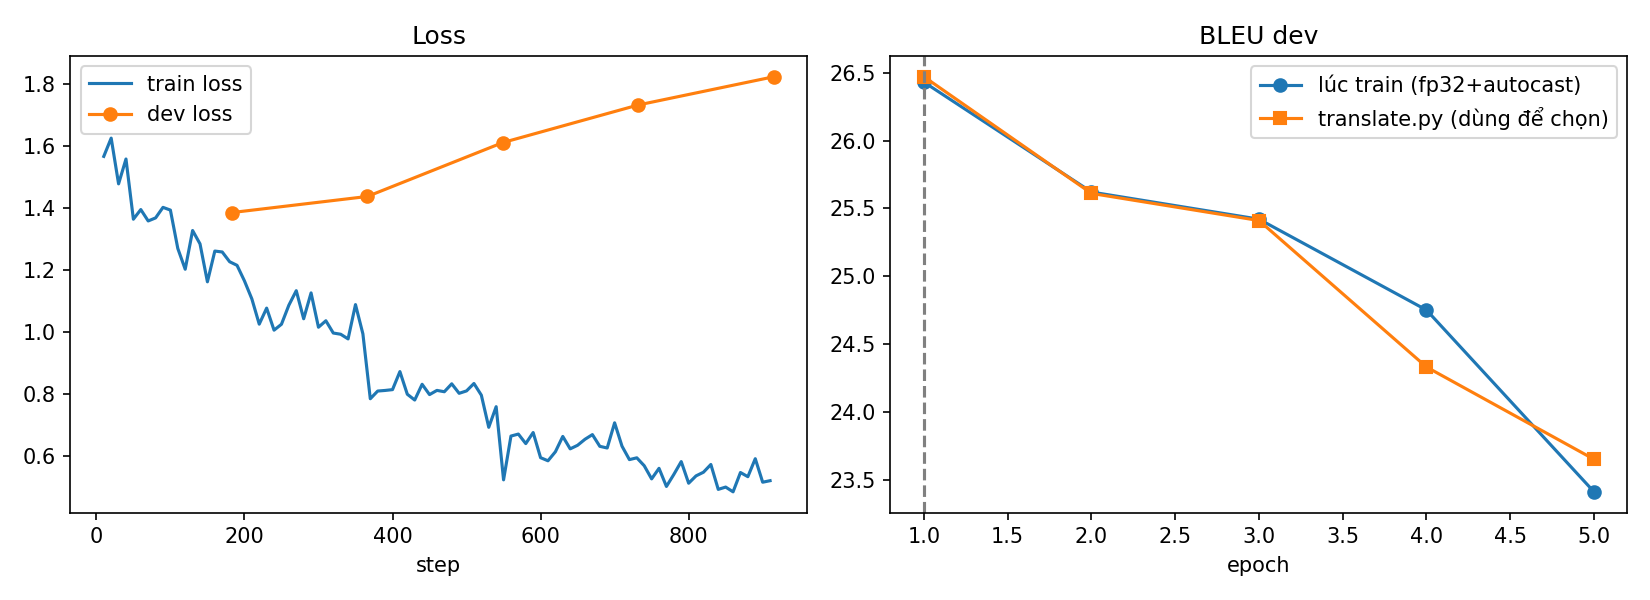

Checkpoint: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chon.json', 'dev_hyp.jsonl', 'dev_translate']
Epoch chọn: 1


In [21]:
train("V1", 2e-4, "fleurs_train_asr_pho")

In [22]:
dich("V1", "checkpoints/V1/best")

$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir runs/mt/V1/fleurs_dev_asr_pho --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V1/best


{"BLEU": 26.48, "chrF++": 52.5, "n": 361}


→ mã thoát 0, 0.6 phút


$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_clean.jsonl --out_dir runs/mt/V1/fleurs_dev_clean --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V1/best


{"BLEU": 35.97, "chrF++": 59.92, "n": 361}


→ mã thoát 0, 0.4 phút


... (8 outputs left out)

→ mã thoát 0, 4.9 phút


$ python scripts/mt/translate.py --input runs/mt_data/phomt_test.jsonl --out_dir runs/mt/V1/phomt_test --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V1/best


{"BLEU": 36.96, "chrF++": 58.07, "n": 19151}


→ mã thoát 0, 21.5 phút


$ python scripts/mt/train_lora.py --train runs/mt_data/fleurs_train_asr_pho.jsonl runs/mt_data/phomt_train_mix.jsonl --dev runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir checkpoints/V2 --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --epochs 5 --lr 0.0002 --batch_size 4 --grad_accum 4 --lora_r 16 --lora_alpha 32 --seed 42 --resume


{"epoch": 1, "dev_loss": 1.3941076914689547, "dev_BLEU": 26.11, "dev_chrF++": 52.62, "minutes": 5.43, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2275594240}


{"epoch": 2, "dev_loss": 1.4647085960551973, "dev_BLEU": 25.29, "dev_chrF++": 52.0, "minutes": 5.3, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2650902528}


{"epoch": 3, "dev_loss": 1.6057467843687105, "dev_BLEU": 24.81, "dev_chrF++": 51.26, "minutes": 5.07, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2645217280}


{"epoch": 4, "dev_loss": 1.7904567711901467, "dev_BLEU": 23.45, "dev_chrF++": 50.24, "minutes": 5.06, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2648637440}


{"epoch": 5, "dev_loss": 1.9235870507945645, "dev_BLEU": 22.87, "dev_chrF++": 49.61, "minutes": 5.44, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2651344896}


... (4 outputs left out)

{"BLEU": 23.35, "chrF++": 49.77, "n": 361}


best {'epoch': 1, 'dev_loss': 1.3941076914689547, 'dev_BLEU': 26.11, 'dev_chrF++': 52.62, 'minutes': 5.43, 'peak_vram_bytes': 5994292736, 'ram_rss_bytes': 2275594240, 'dev_BLEU_translate': 2


→ mã thoát 0, 30.6 phút


,epoch,dev_loss,BLEU dev,phút
0,1,1.3941,26.45,5.43
1,2,1.4647,25.26,5.30
2,3,1.6057,25.06,5.07
3,4,1.7905,23.30,5.06
4,5,1.9236,23.35,5.44


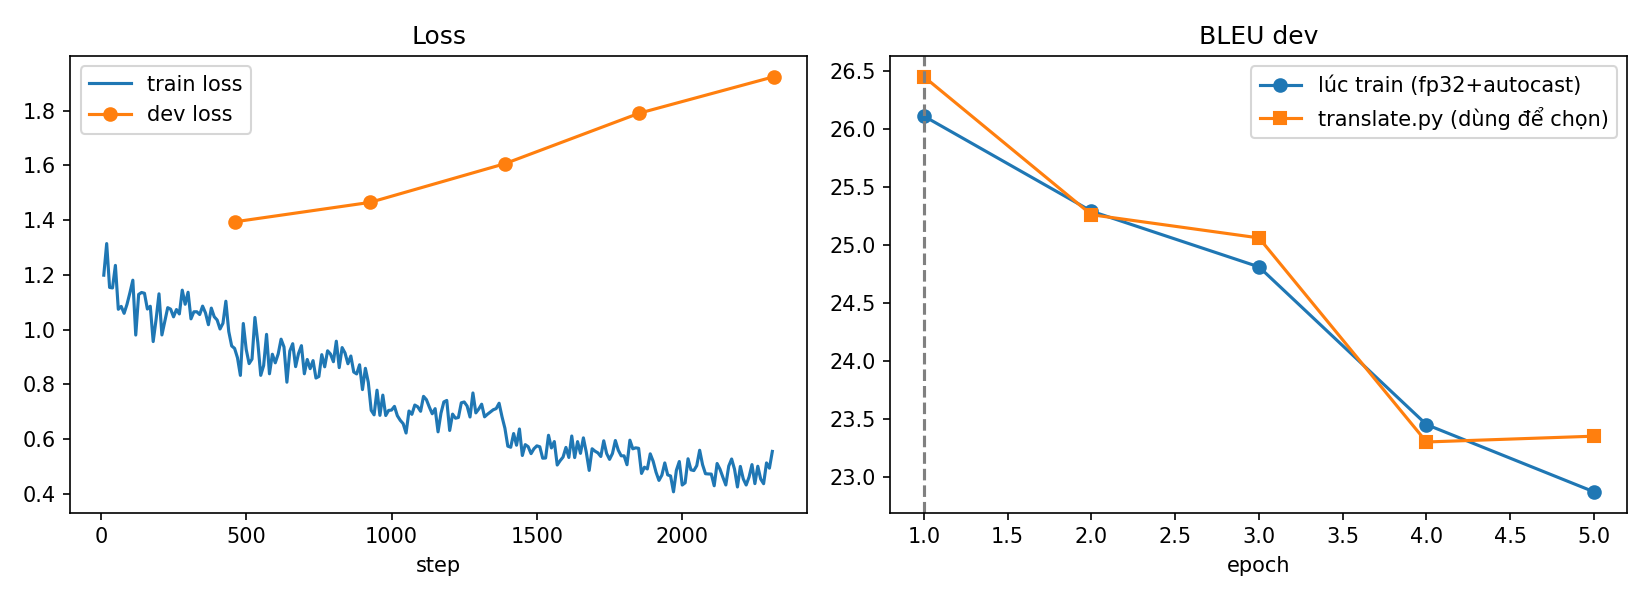

Checkpoint: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chon.json', 'dev_hyp.jsonl', 'dev_translate']
Epoch chọn: 1


In [23]:
train("V2", 2e-4, "fleurs_train_asr_pho", "phomt_train_mix")

In [24]:
dich("V2", "checkpoints/V2/best")

$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir runs/mt/V2/fleurs_dev_asr_pho --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V2/best


{"BLEU": 26.45, "chrF++": 52.74, "n": 361}


→ mã thoát 0, 0.5 phút


$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_clean.jsonl --out_dir runs/mt/V2/fleurs_dev_clean --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V2/best


{"BLEU": 36.93, "chrF++": 61.24, "n": 361}


→ mã thoát 0, 0.4 phút


... (8 outputs left out)

→ mã thoát 0, 4.5 phút


$ python scripts/mt/translate.py --input runs/mt_data/phomt_test.jsonl --out_dir runs/mt/V2/phomt_test --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V2/best


{"BLEU": 40.41, "chrF++": 60.35, "n": 19151}


→ mã thoát 0, 12.1 phút


$ python scripts/mt/train_lora.py --train runs/mt_data/fleurs_train_asr_pho_canbang.jsonl runs/mt_data/phomt_train_mix.jsonl --dev runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir checkpoints/V3 --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --epochs 5 --lr 0.0002 --batch_size 4 --grad_accum 4 --lora_r 16 --lora_alpha 32 --seed 42 --resume


{"epoch": 1, "dev_loss": 1.4211246191299522, "dev_BLEU": 26.59, "dev_chrF++": 52.49, "minutes": 6.55, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2148007936}


{"epoch": 2, "dev_loss": 1.6523121109959822, "dev_BLEU": 23.29, "dev_chrF++": 50.72, "minutes": 6.81, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2159767552}


{"epoch": 3, "dev_loss": 1.9285758373809982, "dev_BLEU": 22.82, "dev_chrF++": 49.48, "minutes": 6.45, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2164076544}


{"epoch": 4, "dev_loss": 2.2664975466160233, "dev_BLEU": 21.05, "dev_chrF++": 48.5, "minutes": 6.4, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2168594432}


{"epoch": 5, "dev_loss": 2.413601480362488, "dev_BLEU": 20.96, "dev_chrF++": 48.39, "minutes": 6.25, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2170998784}


... (4 outputs left out)

{"BLEU": 21.0, "chrF++": 48.46, "n": 361}


best {'epoch': 1, 'dev_loss': 1.4211246191299522, 'dev_BLEU': 26.59, 'dev_chrF++': 52.49, 'minutes': 6.55, 'peak_vram_bytes': 5994292736, 'ram_rss_bytes': 2148007936, 'dev_BLEU_translate': 2


→ mã thoát 0, 37.3 phút


,epoch,dev_loss,BLEU dev,phút
0,1,1.4211,26.71,6.55
1,2,1.6523,23.63,6.81
2,3,1.9286,22.57,6.45
3,4,2.2665,20.89,6.40
4,5,2.4136,21.00,6.25


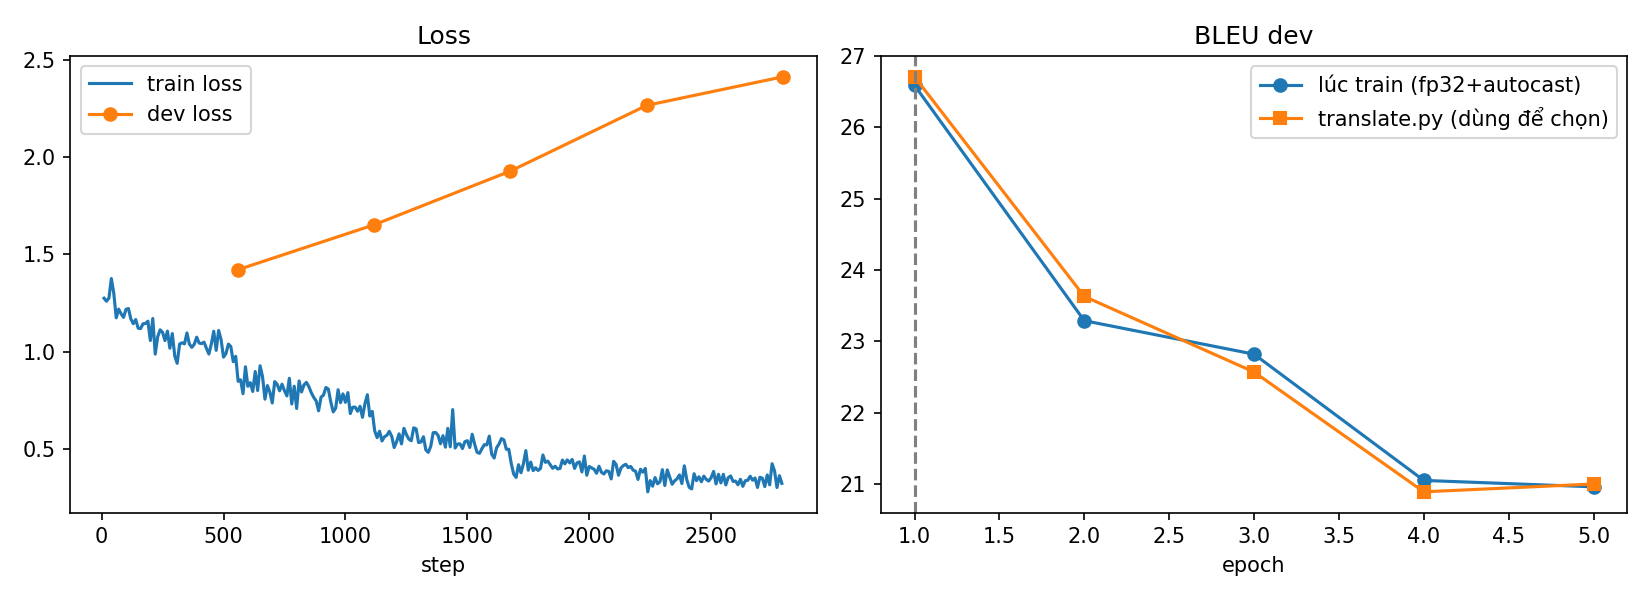

Checkpoint: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chon.json', 'dev_hyp.jsonl', 'dev_translate']
Epoch chọn: 1


In [25]:
train("V3", 2e-4, "fleurs_train_asr_pho_canbang", "phomt_train_mix")

In [26]:
dich("V3", "checkpoints/V3/best")

$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir runs/mt/V3/fleurs_dev_asr_pho --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V3/best


{"BLEU": 26.71, "chrF++": 52.5, "n": 361}


→ mã thoát 0, 0.5 phút


$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_clean.jsonl --out_dir runs/mt/V3/fleurs_dev_clean --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V3/best


{"BLEU": 36.37, "chrF++": 60.48, "n": 361}


→ mã thoát 0, 0.4 phút


... (8 outputs left out)

→ mã thoát 0, 1.0 phút


$ python scripts/mt/translate.py --input runs/mt_data/phomt_test.jsonl --out_dir runs/mt/V3/phomt_test --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V3/best


{"BLEU": 39.59, "chrF++": 59.8, "n": 19151}


→ mã thoát 0, 12.3 phút


$ python scripts/mt/train_lora.py --train runs/mt_data/fleurs_train_asr_pho_canbang.jsonl runs/mt_data/phomt_train_mix.jsonl --dev runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir checkpoints/V4 --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --epochs 5 --lr 5e-05 --batch_size 4 --grad_accum 4 --lora_r 16 --lora_alpha 32 --seed 42 --resume


{"epoch": 1, "dev_loss": 1.391740925424317, "dev_BLEU": 26.2, "dev_chrF++": 51.95, "minutes": 6.7, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2862104576}


{"epoch": 2, "dev_loss": 1.41685601680893, "dev_BLEU": 25.32, "dev_chrF++": 52.08, "minutes": 6.68, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2744147968}


{"epoch": 3, "dev_loss": 1.458540494422173, "dev_BLEU": 25.79, "dev_chrF++": 52.21, "minutes": 6.54, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2749063168}


{"epoch": 4, "dev_loss": 1.5024091536978936, "dev_BLEU": 25.14, "dev_chrF++": 51.8, "minutes": 6.52, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2755010560}


{"epoch": 5, "dev_loss": 1.5293285143342374, "dev_BLEU": 26.02, "dev_chrF++": 52.02, "minutes": 6.42, "peak_vram_bytes": 5994292736, "ram_rss_bytes": 2754457600}


... (4 outputs left out)

{"BLEU": 25.94, "chrF++": 52.0, "n": 361}


best {'epoch': 1, 'dev_loss': 1.391740925424317, 'dev_BLEU': 26.2, 'dev_chrF++': 51.95, 'minutes': 6.7, 'peak_vram_bytes': 5994292736, 'ram_rss_bytes': 2862104576, 'dev_BLEU_translate': 26.3


→ mã thoát 0, 37.2 phút


,epoch,dev_loss,BLEU dev,phút
0,1,1.3917,26.33,6.70
1,2,1.4169,25.38,6.68
2,3,1.4585,25.79,6.54
3,4,1.5024,25.14,6.52
4,5,1.5293,25.94,6.42


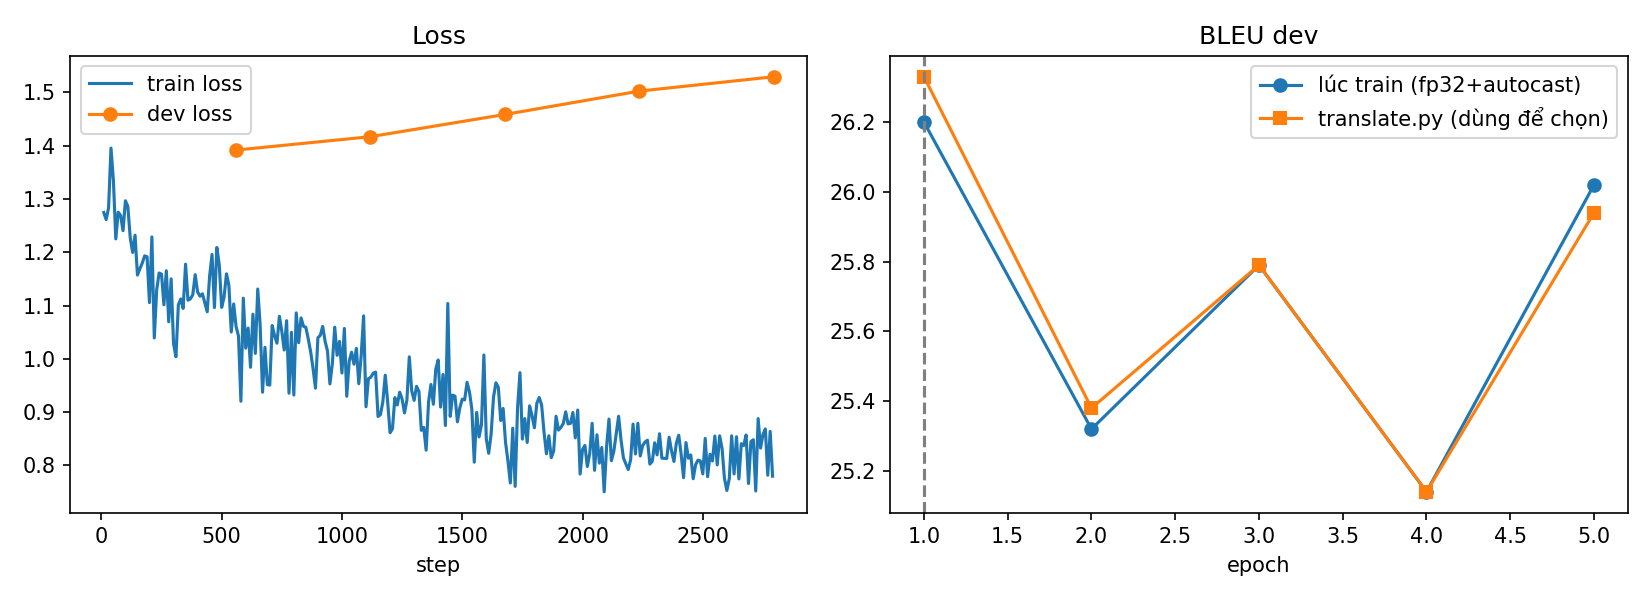

Checkpoint: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chon.json', 'dev_hyp.jsonl', 'dev_translate']
Epoch chọn: 1


In [27]:
train("V4", 5e-5, "fleurs_train_asr_pho_canbang", "phomt_train_mix")

In [28]:
dich("V4", "checkpoints/V4/best")

$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_asr_pho.jsonl --out_dir runs/mt/V4/fleurs_dev_asr_pho --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V4/best


{"BLEU": 26.33, "chrF++": 52.03, "n": 361}


→ mã thoát 0, 2.2 phút


$ python scripts/mt/translate.py --input runs/mt_data/fleurs_dev_clean.jsonl --out_dir runs/mt/V4/fleurs_dev_clean --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V4/best


{"BLEU": 36.75, "chrF++": 60.75, "n": 361}


→ mã thoát 0, 0.4 phút


... (8 outputs left out)

→ mã thoát 0, 5.5 phút


$ python scripts/mt/translate.py --input runs/mt_data/phomt_test.jsonl --out_dir runs/mt/V4/phomt_test --revision ae7baa85da07dbe8e23ac26a9f5ef560c17e2138 --adapter checkpoints/V4/best


{"BLEU": 40.08, "chrF++": 60.21, "n": 19151}


→ mã thoát 0, 11.6 phút


## 7. Đánh giá

In [29]:
%%tep bs_mau scripts/mt/bootstrap.py --a runs/mt/B0/fleurs_test_asr_pho/hyp.jsonl --b runs/mt/V2/fleurs_test_asr_pho/hyp.jsonl --data runs/mt_data/fleurs_test_asr_pho.jsonl --out reports/mt/bootstrap_B0_V2_mau.json
#!/usr/bin/env python3
"""Bootstrap theo cụm sent_id (FLEURS có nhiều bản thu cùng một câu) cho BLEU, so sánh cặp hai hệ thống.

python scripts/mt/bootstrap.py --a runs/mt/B0/fleurs_test_asr_pho/hyp.jsonl --b runs/mt/V1/fleurs_test_asr_pho/hyp.jsonl \
       --data runs/mt_data/fleurs_test_asr_pho.jsonl --out reports/mt/bootstrap_B0_V1.json
Mỗi lần lấy mẫu: rút có hoàn lại các sent_id, lấy mọi bản thu của câu được rút, tính corpus BLEU cho A và B trên cùng mẫu.
Báo cáo: BLEU A, B, delta, khoảng tin cậy 95% của delta, p (một phía: tỉ lệ lần delta <= 0).
"""
import argparse
import json
import random
from collections import defaultdict
from pathlib import Path

import sacrebleu


def load(p):
    return {json.loads(l)["id"]: json.loads(l) for l in open(p, encoding="utf-8") if l.strip()}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--a", required=True); ap.add_argument("--b", required=True)
    ap.add_argument("--data", required=True, help="JSONL có id, sent_id (để gom cụm)")
    ap.add_argument("--out", required=True, type=Path)
    ap.add_argument("--n", type=int, default=1000); ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()
    A, B, D = load(args.a), load(args.b), load(args.data)
    assert A.keys() == B.keys() == D.keys(), "id không khớp giữa hai hệ thống / dữ liệu"
    clusters = defaultdict(list)
    for i, d in D.items():
        clusters[d.get("sent_id") or i].append(i)
    keys = sorted(clusters)
    bleu = sacrebleu.BLEU()

    def corp(S, ids):
        return bleu.corpus_score([S[i]["hyp"] for i in ids], [[S[i]["ref"] for i in ids]]).score

    ids_all = sorted(D)
    a0, b0 = corp(A, ids_all), corp(B, ids_all)
    rng = random.Random(args.seed)
    deltas = []
    for _ in range(args.n):
        ids = [i for k in rng.choices(keys, k=len(keys)) for i in clusters[k]]
        deltas.append(corp(B, ids) - corp(A, ids))
    deltas.sort()
    res = {"A": args.a, "B": args.b, "BLEU_A": round(a0, 2), "BLEU_B": round(b0, 2), "delta": round(b0 - a0, 2),
           "ci95": [round(deltas[int(0.025 * args.n)], 2), round(deltas[int(0.975 * args.n) - 1], 2)],
           "p_one_sided_delta_le_0": sum(d <= 0 for d in deltas) / args.n, "n_resamples": args.n,
           "n_clusters": len(keys), "n_items": len(ids_all), "cluster": "sent_id", "seed": args.seed}
    args.out.parent.mkdir(parents=True, exist_ok=True)
    args.out.write_text(json.dumps(res, indent=2), encoding="utf-8")
    print(json.dumps(res))


if __name__ == "__main__":
    main()

$ python scripts/mt/bootstrap.py --a runs/mt/B0/fleurs_test_asr_pho/hyp.jsonl --b runs/mt/V2/fleurs_test_asr_pho/hyp.jsonl --data runs/mt_data/fleurs_test_asr_pho.jsonl --out reports/mt/bootstrap_B0_V2_mau.json


{"A": "runs/mt/B0/fleurs_test_asr_pho/hyp.jsonl", "B": "runs/mt/V2/fleurs_test_asr_pho/hyp.jsonl", "BLEU_A": 22.69, "BLEU_B": 27.47, "delta": 4.78, "ci95": [3.78, 5.83], "p_one_sided_delta_l


→ mã thoát 0, 1.4 phút


In [30]:
(W / "reports/mt").mkdir(parents=True, exist_ok=True)
for v in ("V1", "V2", "V3", "V4"):
    bs("B0", v, f"bootstrap_B0_{v}_cascade_test")
bs("V1", "V2", "bootstrap_V1_V2_cascade_test"); bs("V2", "V3", "bootstrap_V2_V3_cascade_test"); bs("V3", "V4", "bootstrap_V3_V4_cascade_test")

$ python scripts/mt/bootstrap.py --a runs/mt/B0/fleurs_test_asr_pho/hyp.jsonl --b runs/mt/V1/fleurs_test_asr_pho/hyp.jsonl --data runs/mt_data/fleurs_test_asr_pho.jsonl --out reports/mt/bootstrap_B0_V1_cascade_test.json


{"A": "runs/mt/B0/fleurs_test_asr_pho/hyp.jsonl", "B": "runs/mt/V1/fleurs_test_asr_pho/hyp.jsonl", "BLEU_A": 22.69, "BLEU_B": 27.49, "delta": 4.81, "ci95": [3.75, 5.92], "p_one_sided_delta_l


→ mã thoát 0, 1.3 phút


bootstrap_B0_V1_cascade_test {'BLEU_A': 22.69, 'BLEU_B': 27.49, 'delta': 4.81, 'ci95': [3.75, 5.92], 'p_one_sided_delta_le_0': 0.0}
$ python scripts/mt/bootstrap.py --a runs/mt/B0/fleurs_test_asr_pho/hyp.jsonl --b runs/mt/V2/fleurs_test_asr_pho/hyp.jsonl --data runs/mt_data/fleurs_test_asr_pho.jsonl --out reports/mt/bootstrap_B0_V2_cascade_test.json


{"A": "runs/mt/B0/fleurs_test_asr_pho/hyp.jsonl", "B": "runs/mt/V2/fleurs_test_asr_pho/hyp.jsonl", "BLEU_A": 22.69, "BLEU_B": 27.47, "delta": 4.78, "ci95": [3.78, 5.83], "p_one_sided_delta_l


→ mã thoát 0, 1.3 phút


... (12 outputs left out)

bootstrap_V2_V3_cascade_test {'BLEU_A': 27.47, 'BLEU_B': 27.33, 'delta': -0.14, 'ci95': [-1.05, 0.68], 'p_one_sided_delta_le_0': 0.683}
$ python scripts/mt/bootstrap.py --a runs/mt/V3/fleurs_test_asr_pho/hyp.jsonl --b runs/mt/V4/fleurs_test_asr_pho/hyp.jsonl --data runs/mt_data/fleurs_test_asr_pho.jsonl --out reports/mt/bootstrap_V3_V4_cascade_test.json


{"A": "runs/mt/V3/fleurs_test_asr_pho/hyp.jsonl", "B": "runs/mt/V4/fleurs_test_asr_pho/hyp.jsonl", "BLEU_A": 27.33, "BLEU_B": 27.37, "delta": 0.04, "ci95": [-0.92, 0.93], "p_one_sided_delta_


→ mã thoát 0, 1.3 phút


bootstrap_V3_V4_cascade_test {'BLEU_A': 27.33, 'BLEU_B': 27.37, 'delta': 0.04, 'ci95': [-0.92, 0.93], 'p_one_sided_delta_le_0': 0.408}


In [31]:
%%tep toc_do scripts/mt/do_toc_do.py --n 100 --out reports/toc_do/toc_do_V2.json --adapter checkpoints/V2/best
#!/usr/bin/env python3
"""S9 – Đo tốc độ cascade ASR → MT trên cùng máy (RTX 4060 Laptop), batch 1, như khi dùng thật.

Lấy N bản thu FLEURS test (chọn ngẫu nhiên seed 42, cố định), mỗi bản thu: ASR (theo protocol, short/long-form) rồi dịch 1 câu.
Ghi: thời gian ASR, MT, tổng; RTF = tổng thời gian xử lý / tổng thời lượng audio; latency p50/p95 mỗi bản thu;
VRAM đỉnh (torch.cuda.max_memory_allocated); dung lượng checkpoint trên đĩa (ASR, MT, adapter).
Có 3 lần warm-up không tính. Kết quả: --out (JSON) + per_utt.csv cạnh đó.
"""
import argparse
import csv
import json
import os
import random
import statistics
import sys
import threading
import time

import psutil
from pathlib import Path

import numpy as np
import soundfile as sf
import torch
from transformers import GenerationConfig, WhisperForConditionalGeneration, WhisperProcessor

sys.path.insert(0, str(Path(__file__).resolve().parent))
from translate import load_mt, translate_batch  # noqa: E402


def dir_bytes(p):
    return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file())


def weight_bytes(repo, revision):
    """Dung lượng file trọng số thật sự được nạp (ưu tiên safetensors như transformers), không cộng file trùng."""
    snap = Path(os.environ["HF_HUB_CACHE"]) / f"models--{repo.replace('/', '--')}" / "snapshots" / revision
    for n in ("model.safetensors", "pytorch_model.bin"):
        if (snap / n).exists():
            return (snap / n).stat().st_size, n
    return None, None


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--manifest", default="runs/manifests/asr_fleurs_test.jsonl")
    ap.add_argument("--asr_model", default="vinai/PhoWhisper-small")
    ap.add_argument("--asr_revision", default="a86b604c346caf7148c37512eafe783a16420adb")
    ap.add_argument("--mt_revision", default="ae7baa85da07dbe8e23ac26a9f5ef560c17e2138")
    ap.add_argument("--adapter", default=None)
    ap.add_argument("--suppress", default="configs/common_suppression_from_task1.json")
    ap.add_argument("--n", type=int, default=100)
    ap.add_argument("--out", required=True, type=Path)
    args = ap.parse_args()
    torch.manual_seed(42)
    items = [json.loads(l) for l in open(args.manifest, encoding="utf-8") if l.strip()]
    sample = random.Random(42).sample(items, args.n)

    proc = WhisperProcessor.from_pretrained(args.asr_model, revision=args.asr_revision)
    asr = WhisperForConditionalGeneration.from_pretrained(args.asr_model, revision=args.asr_revision, torch_dtype=torch.float16).cuda().eval()
    g = GenerationConfig.from_pretrained(args.asr_model, revision=args.asr_revision)
    sup = json.load(open(args.suppress, encoding="utf-8"))
    g.suppress_tokens, g.begin_suppress_tokens = sup["suppress_tokens"], sup["begin_suppress_tokens"]
    asr.generation_config = g
    common = dict(language="vi", task="transcribe", num_beams=5, do_sample=False, max_new_tokens=440, condition_on_prev_tokens=False)
    tok, mt = load_mt(args.mt_revision, args.adapter)

    @torch.inference_mode()
    def run(a):
        long_form = len(a) / 16000 > 30
        f = proc(a, sampling_rate=16000, return_tensors="pt", truncation=False,
                 padding="longest" if long_form else "max_length", return_attention_mask=True)
        out = asr.generate(f.input_features.cuda().half(), attention_mask=f.attention_mask.cuda(), **common, return_timestamps=long_form)
        return proc.batch_decode(out if not isinstance(out, dict) else out["sequences"], skip_special_tokens=True)[0].strip()

    for it in sample[:3]:  # warm-up
        translate_batch(tok, mt, [run(sf.read(it["audio"], dtype="float32")[0])])
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    proc_ps = psutil.Process()
    ram, stop = [proc_ps.memory_info().rss], threading.Event()

    def _lay_mau_ram():
        while not stop.wait(0.5):
            ram.append(proc_ps.memory_info().rss)
    th = threading.Thread(target=_lay_mau_ram, daemon=True); th.start()
    rows = []
    for it in sample:
        a = sf.read(it["audio"], dtype="float32")[0]
        torch.cuda.synchronize(); t0 = time.perf_counter()
        txt = run(a)
        torch.cuda.synchronize(); t1 = time.perf_counter()
        en = translate_batch(tok, mt, [txt])[0]
        torch.cuda.synchronize(); t2 = time.perf_counter()
        rows.append({"id": it["id"], "duration_s": len(a) / 16000, "asr_s": t1 - t0, "mt_s": t2 - t1, "total_s": t2 - t0,
                     "n_src_chars": len(txt), "n_hyp_chars": len(en)})
    dur = sum(r["duration_s"] for r in rows)
    tot = [r["total_s"] for r in rows]
    q = statistics.quantiles(tot, n=20)
    stop.set(); th.join()
    asr_b, asr_f = weight_bytes(args.asr_model, args.asr_revision)
    mt_b, mt_f = weight_bytes("vinai/vinai-translate-vi2en-v2", args.mt_revision)
    res = {"n": len(rows), "audio_s": round(dur, 1), "RTF_total": round(sum(tot) / dur, 3),
           "RTF_asr": round(sum(r["asr_s"] for r in rows) / dur, 3), "RTF_mt": round(sum(r["mt_s"] for r in rows) / dur, 3),
           "latency_p50_s": round(statistics.median(tot), 2), "latency_p95_s": round(q[18], 2),
           "latency_mean_s": round(statistics.mean(tot), 2), "asr_mean_s": round(statistics.mean(r["asr_s"] for r in rows), 2),
           "mt_mean_s": round(statistics.mean(r["mt_s"] for r in rows), 2),
           "gpu_peak_allocated_bytes": torch.cuda.max_memory_allocated(),
           "ram_rss_peak_bytes": max(ram), "ram_sampling": "RSS tiến trình Python, lấy mẫu mỗi 0,5 s trong lúc đo",
           "asr_checkpoint_bytes": asr_b, "asr_weight_file": asr_f, "mt_checkpoint_bytes": mt_b, "mt_weight_file": mt_f,
           "adapter_bytes": sum(f.stat().st_size for f in Path(args.adapter).glob("adapter_model.*")) if args.adapter else 0,
           "adapter": args.adapter,
           "gpu": torch.cuda.get_device_name(0), "torch": torch.__version__, "batch_size": 1,
           "note": "ASR fp16 beam 5 theo protocol; MT fp16 beam 5; adapter LoRA được merge vào trọng số trước khi đo"}
    args.out.parent.mkdir(parents=True, exist_ok=True)
    args.out.write_text(json.dumps(res, indent=2), encoding="utf-8")
    with open(args.out.with_suffix(".per_utt.csv"), "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
    print(json.dumps(res))


if __name__ == "__main__":
    main()

$ python scripts/mt/do_toc_do.py --n 100 --out reports/toc_do/toc_do_V2.json --adapter checkpoints/V2/best


{"n": 100, "audio_s": 1254.8, "RTF_total": 0.101, "RTF_asr": 0.073, "RTF_mt": 0.029, "latency_p50_s": 1.21, "latency_p95_s": 2.19, "latency_mean_s": 1.27, "asr_mean_s": 0.91, "mt_mean_s": 0.


→ mã thoát 0, 2.4 phút


In [32]:
chay("mien_ket_qua", "scripts/cham_theo_mien.py", bat_buoc=False)
f = W / "reports/domain/ket_qua_theo_mien.csv"
if f.exists():
    display(pd.read_csv(f).tail(12))

$ python scripts/cham_theo_mien.py


| Khối | Hệ | Tập | Miền | n | WER | CER | BLEU | chrF++ |


|---|---|---|---|---|---|---|---|---|


| ASR | phowhisper-small_fleurs_dev | FLEURS dev | Giáo dục (Wikibooks – sách giáo khoa mở) | 106 | 13.93 | 9.89 |  |  |


| ASR | phowhisper-small_fleurs_dev | FLEURS dev | Tin tức (Wikinews) | 131 | 16.48 | 13.11 |  |  |


| ASR | phowhisper-small_fleurs_dev | FLEURS dev | Du lịch (Wikivoyage) | 124 | 8.73 | 6.32 |  |  |


... (82 outputs left out)

| MT | V4 | fleurs_test_clean | Tin tức (Wikinews) | 267 |  |  | 38.28 | 62.63 |


| MT | V4 | fleurs_test_clean | Du lịch (Wikivoyage) | 254 |  |  | 35.86 | 58.4 |


→ mã thoát 0, 0.1 phút


,khoi,he,tap,mien,n_ban_thu,WER,CER,BLEU,chrF++
75,MT,V4,fleurs_dev_clean,Giáo dục (Wikibooks – sách giáo khoa mở),106,NaN,NaN,35.13,59.96
76,MT,V4,fleurs_dev_clean,Tin tức (Wikinews),131,NaN,NaN,37.17,61.54
77,MT,V4,fleurs_dev_clean,Du lịch (Wikivoyage),124,NaN,NaN,37.35,60.61
78,MT,V4,fleurs_test_asr_pho,Giáo dục (Wikibooks – sách giáo khoa mở),336,NaN,NaN,31.22,54.89
79,MT,V4,fleurs_test_asr_pho,Tin tức (Wikinews),267,NaN,NaN,22.30,51.26
80,MT,V4,fleurs_test_asr_pho,Du lịch (Wikivoyage),254,NaN,NaN,26.42,50.67
81,MT,V4,fleurs_test_asr_wsp,Giáo dục (Wikibooks – sách giáo khoa mở),336,NaN,NaN,22.83,46.80
82,MT,V4,fleurs_test_asr_wsp,Tin tức (Wikinews),267,NaN,NaN,17.41,44.69
83,MT,V4,fleurs_test_asr_wsp,Du lịch (Wikivoyage),254,NaN,NaN,20.25,43.76
84,MT,V4,fleurs_test_clean,Giáo dục (Wikibooks – sách giáo khoa mở),336,NaN,NaN,39.58,61.80


In [33]:
H = {"B0": "B0", "V1": "V1", "V2": "V2", "V3": "V3", "V4": "V4"}
d = []
for v in H:
    r = {"bản": v}
    for k, t in (("dev cascade", "fleurs_dev_asr_pho"), ("dev sạch", "fleurs_dev_clean"), ("test cascade", "fleurs_test_asr_pho"), ("test sạch", "fleurs_test_clean"), ("Whisper → dịch", "fleurs_test_asr_wsp"), ("PhoMT", "phomt_test")):
        s = json.loads((W / f"runs/mt/{v}/{t}/score.json").read_text(encoding="utf-8")); r[k] = s["BLEU"]
    d.append(r)
B = pd.DataFrame(d); display(B)
M = B[B["bản"] != "B0"]["dev cascade"].max(); hoa = B[(B["bản"] != "B0") & (B["dev cascade"] >= M - .5)]
print("Áp quy tắc DEV trên lần chạy này: nhóm hoà", list(hoa["bản"]), "→ chọn", hoa.sort_values("dev sạch", ascending=False).iloc[0]["bản"])

,bản,dev cascade,dev sạch,test cascade,test sạch,Whisper → dịch,PhoMT
0,B0,22.96,37.57,22.69,38.27,18.58,40.79
1,V1,26.48,35.97,27.49,36.21,20.41,36.96
2,V2,26.45,36.93,27.47,38.09,19.68,40.41
3,V3,26.71,36.37,27.33,36.76,19.86,39.59
4,V4,26.33,36.75,27.37,38.11,20.42,40.08


Áp quy tắc DEV trên lần chạy này: nhóm hoà ['V1', 'V2', 'V3', 'V4'] → chọn V2


In [34]:
# So với số đã báo cáo, chỉ để xem, không ghi vào đâu
c = []
for v in H:
    for k, t in (("test cascade", "fleurs_test_asr_pho"), ("test sạch", "fleurs_test_clean")):
        a = json.loads((T / f"runs/mt/{v}/{t}/score.json").read_text(encoding="utf-8"))["BLEU"]; b = json.loads((W / f"runs/mt/{v}/{t}/score.json").read_text(encoding="utf-8"))["BLEU"]
        c.append({"bản": v, "chỉ số": k, "đã báo cáo": a, "lần chạy này": b, "chênh": round(b - a, 2)})
pd.DataFrame(c)

,bản,chỉ số,đã báo cáo,lần chạy này,chênh
0,B0,test cascade,22.69,22.69,0.0
1,B0,test sạch,38.27,38.27,0.0
2,V1,test cascade,27.49,27.49,0.0
3,V1,test sạch,36.21,36.21,0.0
4,V2,test cascade,27.47,27.47,0.0
5,V2,test sạch,38.09,38.09,0.0
6,V3,test cascade,27.33,27.33,0.0
7,V3,test sạch,36.76,36.76,0.0
8,V4,test cascade,27.37,27.37,0.0
9,V4,test sạch,38.11,38.11,0.0
